LOADING DATASETS
Dataset 2 original shape: (2085, 19)
Dataset 1 external test shape: (1523, 19)

OUTLIER REMOVAL & DATASET INFORMATION
Training samples : 2085
External test    : 1523

Training class distribution:
Result
0    1172
1     913
Name: count, dtype: int64

External test class distribution:
Result
1    1042
0     481
Name: count, dtype: int64

Balancing approaches included:
 - Without balancing
 - SMOTE
 - SMOTETomek
 - ADASYN
 - Tomek links
 - SMOTEENN

ALL MODELS X ALL BALANCING — 10-FOLD CV & HOLDOUT TEST (42 COMBINATIONS)

Processing Model: Logistic Regression (LR)...

Processing Model: Decision Tree (DT)...

Processing Model: Random Forest (RF)...

Processing Model: Support Vector Machine (SVM)...

Processing Model: K-Nearest Neighbors (KNN)...

Processing Model: Proposed DengueStackX-19...

Processing Model: Light Gradient Boosting Machine (LGBM)...

FINAL PERFORMANCE COMPARISON TABLE (ALL COMBINATIONS)
                                 Model         Balancing  10-Fold CV

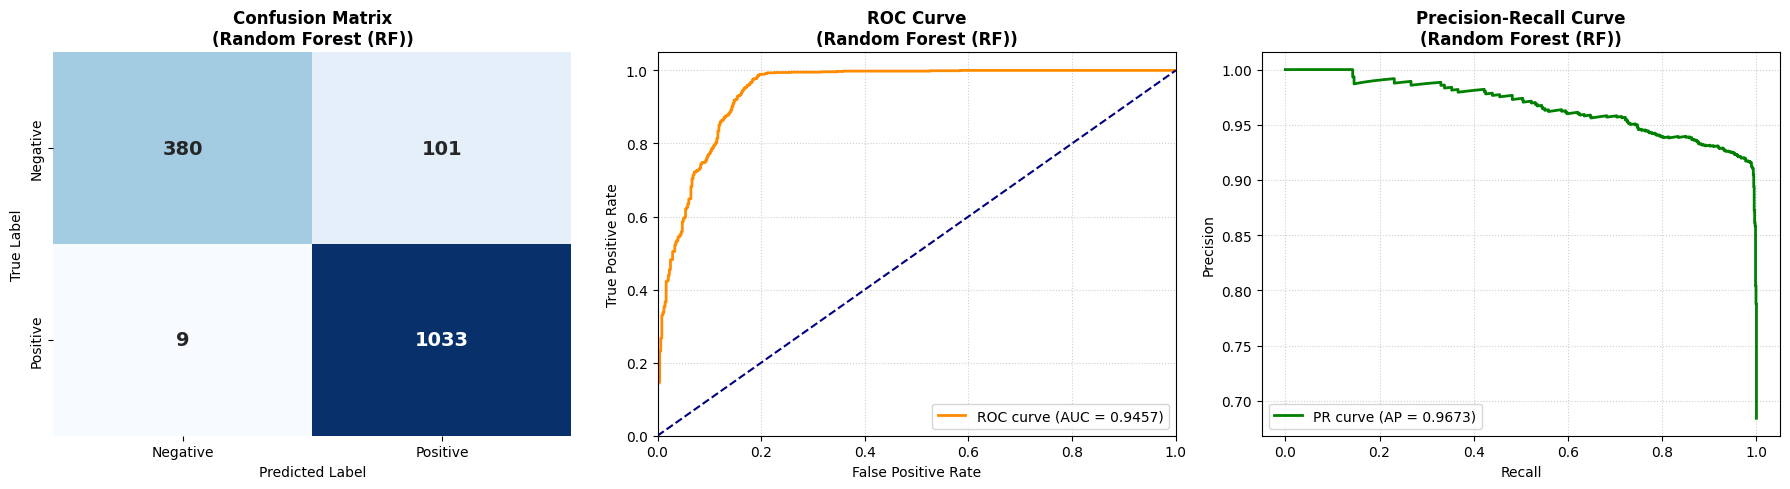

EXPERIMENT FINISHED
Results saved successfully to 'all_models_all_balancing_combinations.csv'
Best model saved as 'Dengue_Best_Overall_Model.joblib'
Plots saved as 'Dengue_Best_Model_Evaluation_Plots.png'


In [ ]:
#all ml model

#1/9   7.30 - latest bset accu - no data lekage
import warnings
warnings.filterwarnings("ignore")

import os
import time
import numpy as np
import pandas as pd
import joblib

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# ----------------------------------------------------------------------------
# IMBALANCED-LEARN & OPTIONAL LIBRARIES
# ----------------------------------------------------------------------------
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE, ADASYN
    from imblearn.under_sampling import TomekLinks
    from imblearn.combine import SMOTEENN, SMOTETomek
    HAS_IMBLEARN = True
except ImportError:
    HAS_IMBLEARN = False
    from sklearn.pipeline import Pipeline as ImbPipeline
    print("WARNING: imbalanced-learn is not installed.")

try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False

# ----------------------------------------------------------------------------
# CONFIGURATION & PATHS
# ----------------------------------------------------------------------------
SEED = 42
np.random.seed(SEED)

CACHE_DIR = "dafodil_repro_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

TRAIN_DATA_FILE = "https://raw.githubusercontent.com/ashraful159/Dengue_Fever_Prediction/refs/heads/main/Dengue%20Fever%20Hematological%20Dataset%20Clinical%20Insights%20for%20Improved%20Diagnosis%20and%20Patient%20Management/new_dataset/dafodil_2086_new-.csv"
TEST_DATA_FILE = "https://raw.githubusercontent.com/ashraful159/Dengue_Fever_Prediction/refs/heads/main/Dengue%20Fever%20Hematological%20Dataset%20Clinical%20Insights%20for%20Improved%20Diagnosis%20and%20Patient%20Management/new_dataset/Dengue%20Fever%20Hematological%20Dataset.csv"

EXPECTED_COLUMNS = [
    "Gender", "Age", "Hemoglobin(g/dl)", "Neutrophils(%)", "Lymphocytes(%)",
    "Monocytes(%)", "Eosinophils(%)", "RBC", "HCT(%)", "MCV(fl)",
    "MCH(pg)", "MCHC(g/dl)", "RDW-CV(%)", "Total Platelet Count(/cumm)",
    "MPV(fl)", "PDW(%)", "PCT(%)", "Total WBC count(/cumm)", "Result"
]

TARGET_COL = "Result"
FEATURE_COLS = [c for c in EXPECTED_COLUMNS if c != TARGET_COL]
NUMERIC_COLS = [c for c in FEATURE_COLS if c != "Gender"]
ADOPTED_OUTLIER_COLS = [c for c in NUMERIC_COLS if c not in ("PCT(%)", "Total WBC count(/cumm)")]

# ----------------------------------------------------------------------------
# 100% LEAKAGE-FREE CUSTOM TRANSFORMER: IQR CLIPPER
# ----------------------------------------------------------------------------
class IQRClipper(BaseEstimator, TransformerMixin):
    def __init__(self, columns=None, factor=1.5):
        self.columns = columns
        self.factor = factor

    def fit(self, X, y=None):
        X_mat = np.asarray(X)

        # DataFrame এবং NumPy Array উভয় ফরম্যাটের জন্য সঠিক Column Index বের করা
        if isinstance(X, pd.DataFrame):
            self.col_indices_ = [X.columns.get_loc(c) for c in self.columns if c in X.columns]
        else:
            self.col_indices_ = [FEATURE_COLS.index(c) for c in self.columns if c in FEATURE_COLS]

        self.lower_bounds_ = {}
        self.upper_bounds_ = {}

        # শুধুমাত্র Training Fold-এর ডাটা ব্যবহার করে Threshold নির্ধারণ
        for idx in self.col_indices_:
            col_data = X_mat[:, idx]
            valid_data = col_data[~np.isnan(col_data)]
            q1 = np.percentile(valid_data, 25)
            q3 = np.percentile(valid_data, 75)
            iqr = q3 - q1
            self.lower_bounds_[idx] = q1 - self.factor * iqr
            self.upper_bounds_[idx] = q3 + self.factor * iqr
        return self

    def transform(self, X):
        X_out = np.array(X, copy=True)
        for idx in self.col_indices_:
            X_out[:, idx] = np.clip(X_out[:, idx], a_min=self.lower_bounds_[idx], a_max=self.upper_bounds_[idx])
        return X_out

# ----------------------------------------------------------------------------
# DATA PREPROCESSING
# ----------------------------------------------------------------------------
def preprocess_dataset(data):
    df = data.copy()
    if df["Gender"].dtype == object:
        df["Gender"] = df["Gender"].astype(str).str.strip().str.lower().map({"male": 1, "female": 0})
    if df["Result"].dtype == object:
        df["Result"] = df["Result"].astype(str).str.strip().str.lower().map({"positive": 1, "negative": 0})
    return df

print("=" * 80)
print("LOADING DATASETS")
print("=" * 80)

df_train_raw = pd.read_csv(TRAIN_DATA_FILE)
df_train_raw.columns = [c.strip() for c in df_train_raw.columns]

df_test_raw = pd.read_csv(TEST_DATA_FILE)
df_test_raw.columns = [c.strip() for c in df_test_raw.columns]

print(f"Dataset 2 original shape: {df_train_raw.shape}")
print(f"Dataset 1 external test shape: {df_test_raw.shape}")

df_train = preprocess_dataset(df_train_raw).dropna(subset=EXPECTED_COLUMNS).reset_index(drop=True)
df_test = preprocess_dataset(df_test_raw).dropna(subset=EXPECTED_COLUMNS).reset_index(drop=True)

X_train = df_train[FEATURE_COLS].copy()
y_train = df_train[TARGET_COL].astype(int).copy()

X_test = df_test[FEATURE_COLS].copy()
y_test = df_test[TARGET_COL].astype(int).copy()

print("\n" + "=" * 80)
print("OUTLIER REMOVAL & DATASET INFORMATION")
print("=" * 80)
print(f"Training samples : {len(df_train)}")
print(f"External test    : {len(df_test)}")

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nExternal test class distribution:")
print(y_test.value_counts())

# ----------------------------------------------------------------------------
# BUILDERS & PIPELINE
# ----------------------------------------------------------------------------
def make_samplers(seed=SEED):
    if not HAS_IMBLEARN:
        return {"Without balancing": None}
    return {
        "Without balancing": None,
        "SMOTE": SMOTE(random_state=seed),
        "SMOTETomek": SMOTETomek(random_state=seed),
        "ADASYN": ADASYN(random_state=seed, sampling_strategy="minority"),
        "Tomek links": TomekLinks(),
        "SMOTEENN": SMOTEENN(random_state=seed)
    }

def make_base_learners(seed=SEED):
    learners = [
        ("rf", RandomForestClassifier(n_estimators=300, max_depth=30, min_samples_split=5, random_state=seed, n_jobs=-1)),
        ("dt", DecisionTreeClassifier(criterion="entropy", splitter="random", min_samples_split=5, random_state=seed)),
        ("svm", SVC(kernel="rbf", C=1, gamma=0.1, probability=True, random_state=seed)),
        ("knn", KNeighborsClassifier(n_neighbors=3, leaf_size=4, p=1))
    ]
    if HAS_LGBM:
        learners.append(("lgbm", LGBMClassifier(random_state=seed, verbose=-1)))
    return learners

def make_stack(seed=SEED):
    return StackingClassifier(
        estimators=make_base_learners(seed),
        final_estimator=LogisticRegression(max_iter=1000, random_state=seed),
        stack_method="predict_proba",
        cv=5,
        n_jobs=-1
    )

def make_models(seed=SEED):
    base = dict(make_base_learners(seed))
    models = {
        "Logistic Regression (LR)": LogisticRegression(max_iter=1000, random_state=seed),
        "Decision Tree (DT)": base["dt"],
        "Random Forest (RF)": base["rf"],
        "Support Vector Machine (SVM)": base["svm"],
        "K-Nearest Neighbors (KNN)": base["knn"],
        "Proposed DengueStackX-19": make_stack(seed)
    }
    if HAS_LGBM:
        models["Light Gradient Boosting Machine (LGBM)"] = base["lgbm"]
    return models

LEAKAGE_SAFE_STACK = True   # True: resampling is done INSIDE every base learner (leakage-safe stacking)

def _leakage_safe_stack(stack, sampler):
    """Move the balancer from in front of the stack into each base learner, so the stack's internal
    5-fold never sees synthetic samples generated from its own validation fold."""
    est = [(n, ImbPipeline([("balancer", clone(sampler)), ("clf", clone(e))])) for n, e in stack.estimators]
    return StackingClassifier(estimators=est, final_estimator=clone(stack.final_estimator),
                              stack_method=stack.stack_method, cv=stack.cv, n_jobs=stack.n_jobs)

def build_pipeline(model, sampler):
    steps = [
        ("outlier_handler", IQRClipper(columns=ADOPTED_OUTLIER_COLS, factor=1.5)),
        ("scaler", StandardScaler())
    ]
    if sampler is not None and LEAKAGE_SAFE_STACK and isinstance(model, StackingClassifier):
        model = _leakage_safe_stack(model, sampler)   # balancer inside every base learner
    elif sampler is not None:
        steps.append(("balancer", clone(sampler)))  # FIX: never share a sampler object
    steps.append(("model", clone(model)))  # FIX: fresh estimator per pipeline (Pipeline.fit does NOT clone it)
    return ImbPipeline(steps=steps)

def compute_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision (%)": precision_score(y_true, y_pred, zero_division=0) * 100,
        "Recall / Sensitivity (%)": recall_score(y_true, y_pred, zero_division=0) * 100,
        "Specificity (%)": (tn / (tn + fp) if (tn + fp) > 0 else 0) * 100,
        "F1-score (%)": f1_score(y_true, y_pred, zero_division=0) * 100
    }

# ----------------------------------------------------------------------------
# EXHAUSTIVE EVALUATION (ALL MODELS X ALL BALANCING APPROACHES)
# ----------------------------------------------------------------------------
CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
all_combinations_rows = []
fitted_pipelines = {}

samplers_dict = make_samplers(SEED)
models_dict = make_models(SEED)

print("\nBalancing approaches included:")
for approach in samplers_dict.keys():
    print(f" - {approach}")

total_runs = len(models_dict) * len(samplers_dict)

print("\n" + "=" * 80)
print(f"ALL MODELS X ALL BALANCING — 10-FOLD CV & HOLDOUT TEST ({total_runs} COMBINATIONS)")
print("=" * 80)

for model_name, model in models_dict.items():
    print(f"\nProcessing Model: {model_name}...")
    for approach_name, sampler in samplers_dict.items():

        # Build Fresh Pipeline Instance
        pipeline = build_pipeline(model, sampler)

        # 1. 10-Fold Cross-Validation on Dataset 2
        cv_scores = cross_validate(pipeline, X_train, y_train, cv=CV, scoring={"accuracy": "accuracy"}, n_jobs=-1)
        cv_acc = cv_scores["test_accuracy"].mean() * 100

        # 2. Fit on Full Dataset 2 and Test on Dataset 1
        pipeline.fit(X_train, y_train)

        test_pred = pipeline.predict(X_test)
        ext_metrics = compute_metrics(y_test, test_pred)

        key_name = f"{model_name} | {approach_name}"
        fitted_pipelines[key_name] = pipeline

        all_combinations_rows.append({
            "Model": model_name,
            "Balancing": approach_name,
            "10-Fold CV Acc (%) [Dataset 2]": cv_acc,
            "Holdout Test Acc (%) [Dataset 1]": ext_metrics["Accuracy (%)"],
            "Holdout Precision (%)": ext_metrics["Precision (%)"],
            "Holdout Recall (%)": ext_metrics["Recall / Sensitivity (%)"],
            "Holdout Specificity (%)": ext_metrics["Specificity (%)"],
            "Holdout F1-score (%)": ext_metrics["F1-score (%)"]
        })

# Convert to DataFrame & Sort
full_table_df = pd.DataFrame(all_combinations_rows)
full_table_df_sorted = full_table_df.sort_values(
    by=["Holdout Test Acc (%) [Dataset 1]", "10-Fold CV Acc (%) [Dataset 2]"],
    ascending=[False, False]
).reset_index(drop=True)

print("\n" + "=" * 80)
print("FINAL PERFORMANCE COMPARISON TABLE (ALL COMBINATIONS)")
print("=" * 80)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(full_table_df_sorted.to_string(index=False))

# Extract the ABSOLUTE BEST Combination Overall
best_row = full_table_df_sorted.iloc[0]
best_model_key = f"{best_row['Model']} | {best_row['Balancing']}"
best_pipeline = fitted_pipelines[best_model_key]

# SAFETY CHECK: the stored pipeline must reproduce the table accuracy (guards against the shared-estimator bug)
_chk = accuracy_score(y_test, best_pipeline.predict(X_test)) * 100
assert abs(_chk - float(best_row['Holdout Test Acc (%) [Dataset 1]'])) < 1e-6, f'Stored pipeline mismatch: {_chk:.4f}'

# Compute detailed stats for Best Model
best_pred = best_pipeline.predict(X_test)
best_cm = confusion_matrix(y_test, best_pred, labels=[0, 1])
tn, fp, fn, tp = best_cm.ravel()

print("\n" + "=" * 80)
print(f"ABSOLUTE BEST PERFORMING COMBINATION — EXTERNAL RESULT")
print("=" * 80)
print(f"Model Name                    : {best_row['Model']}")
print(f"Balancing Strategy            : {best_row['Balancing']}")
print(f"10-Fold CV Acc (%)            : {best_row['10-Fold CV Acc (%) [Dataset 2]']:.2f}%")
print(f"Holdout Accuracy (%)          : {best_row['Holdout Test Acc (%) [Dataset 1]']:.2f}%")
print(f"Precision (%)                 : {best_row['Holdout Precision (%)']:.2f}%")
print(f"Recall / Sensitivity (%)      : {best_row['Holdout Recall (%)']:.2f}%")
print(f"Specificity (%)               : {best_row['Holdout Specificity (%)']:.2f}%")
print(f"F1-score (%)                  : {best_row['Holdout F1-score (%)']:.2f}%")

print("\nConfusion Matrix:")
print(best_cm)

print("\nConfusion Matrix Details:")
print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

print("\n" + "=" * 80)
print("CLASSIFICATION REPORT FOR BEST MODEL")
print("=" * 80)
print(classification_report(y_test, best_pred, target_names=["Negative", "Positive"], digits=4))

# ----------------------------------------------------------------------------
# VISUALIZATIONS FOR BEST MODEL
# ----------------------------------------------------------------------------
print("\n" + "=" * 80)
print("GENERATING PLOTS FOR BEST MODEL")
print("=" * 80)

# Get predicted probabilities for positive class
if hasattr(best_pipeline, "predict_proba"):
    y_probs = best_pipeline.predict_proba(X_test)[:, 1]
else:
    y_probs = best_pipeline.decision_function(X_test)

plt.figure(figsize=(18, 5))

# 1. Confusion Matrix Plot
plt.subplot(1, 3, 1)
sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'],
            cbar=False, annot_kws={"size": 14, "weight": "bold"})
plt.title(f"Confusion Matrix\n({best_row['Model']})", fontsize=12, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=10)
plt.ylabel("True Label", fontsize=10)

# 2. ROC Curve Plot
fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

plt.subplot(1, 3, 2)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=10)
plt.ylabel('True Positive Rate', fontsize=10)
plt.title(f"ROC Curve\n({best_row['Model']})", fontsize=12, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, linestyle=':', alpha=0.6)

# 3. Precision-Recall Curve Plot
precision, recall, _ = precision_recall_curve(y_test, y_probs)
avg_precision = average_precision_score(y_test, y_probs)

plt.subplot(1, 3, 3)
plt.plot(recall, precision, color='green', lw=2, label=f'PR curve (AP = {avg_precision:.4f})')
plt.xlabel('Recall', fontsize=10)
plt.ylabel('Precision', fontsize=10)
plt.title(f"Precision-Recall Curve\n({best_row['Model']})", fontsize=12, fontweight='bold')
plt.legend(loc="lower left")
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("Dengue_Best_Model_Evaluation_Plots.png", dpi=300)
plt.show()

# Save Results to CSV & Model
full_table_df_sorted.to_csv("all_models_all_balancing_combinations.csv", index=False)
joblib.dump(best_pipeline, "Dengue_Best_Overall_Model.joblib")

print("=" * 80)
print("EXPERIMENT FINISHED")
print("=" * 80)
print("Results saved successfully to 'all_models_all_balancing_combinations.csv'")
print("Best model saved as 'Dengue_Best_Overall_Model.joblib'")
print("Plots saved as 'Dengue_Best_Model_Evaluation_Plots.png'")

LOADING DATASETS
Dataset 2 original shape: (2085, 19)
Dataset 1 external test shape: (1523, 19)

OUTLIER REMOVAL & DATASET INFORMATION
Training samples : 2085
External test    : 1523

Training class distribution:
Result
0    1172
1     913
Name: count, dtype: int64

External test class distribution:
Result
1    1042
0     481
Name: count, dtype: int64

Balancing approaches included:
 - Without balancing
 - SMOTE
 - SMOTETomek
 - ADASYN
 - Tomek links
 - SMOTEENN

ALL DL MODELS X ALL BALANCING — 10-FOLD CV & HOLDOUT TEST (30 COMBINATIONS)

Processing Model: ANN (64)...

Processing Model: DNN (128-64-32)...

Processing Model: Wide MLP (256-128-64)...

Processing Model: Compact MLP (100-50)...

Processing Model: MLP-Stack...

FINAL PERFORMANCE COMPARISON TABLE (ALL DEEP LEARNING COMBINATIONS)
                Model         Balancing  10-Fold CV Acc (%) [Dataset 2]  Holdout Test Acc (%) [Dataset 1]  Holdout Precision (%)  Holdout Recall (%)  Holdout Specificity (%)  Holdout F1-score (%)
Wid

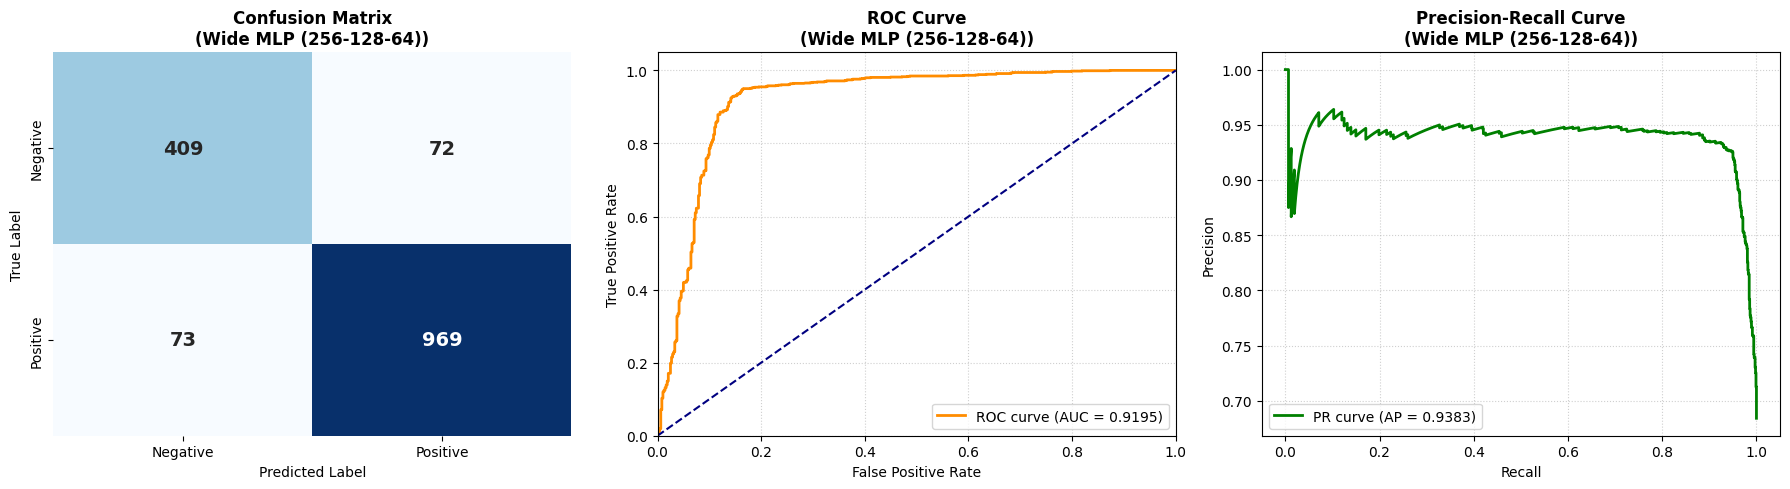

EXPERIMENT FINISHED
Results saved successfully to 'all_dl_models_all_balancing_combinations.csv'
Best DL model saved as 'Dengue_Best_DL_Overall_Model.joblib'
Plots saved as 'Dengue_Best_DL_Model_Evaluation_Plots.png'


In [ ]:
#all deep learning model

#latest -4/9-
# - latest bset accu - no data leakage (MLP-based deep baselines)
# ANN, DNN, wide MLP, compact MLP, MLP-Stack (logistic-regression meta-learner)
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# ----------------------------------------------------------------------------
# IMBALANCED-LEARN & OPTIONAL LIBRARIES
# ----------------------------------------------------------------------------
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE, ADASYN
    from imblearn.under_sampling import TomekLinks
    from imblearn.combine import SMOTEENN, SMOTETomek
    HAS_IMBLEARN = True
except ImportError:
    HAS_IMBLEARN = False
    from sklearn.pipeline import Pipeline as ImbPipeline
    print("WARNING: imbalanced-learn is not installed.")

# ----------------------------------------------------------------------------
# CONFIGURATION & PATHS
# ----------------------------------------------------------------------------
SEED = 42
np.random.seed(SEED)

CACHE_DIR = "dafodil_repro_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

TRAIN_DATA_FILE = "https://raw.githubusercontent.com/ashraful159/Dengue_Fever_Prediction/refs/heads/main/Dengue%20Fever%20Hematological%20Dataset%20Clinical%20Insights%20for%20Improved%20Diagnosis%20and%20Patient%20Management/new_dataset/dafodil_2086_new-.csv"
TEST_DATA_FILE = "https://raw.githubusercontent.com/ashraful159/Dengue_Fever_Prediction/refs/heads/main/Dengue%20Fever%20Hematological%20Dataset%20Clinical%20Insights%20for%20Improved%20Diagnosis%20and%20Patient%20Management/new_dataset/Dengue%20Fever%20Hematological%20Dataset.csv"

EXPECTED_COLUMNS = [
    "Gender", "Age", "Hemoglobin(g/dl)", "Neutrophils(%)", "Lymphocytes(%)",
    "Monocytes(%)", "Eosinophils(%)", "RBC", "HCT(%)", "MCV(fl)",
    "MCH(pg)", "MCHC(g/dl)", "RDW-CV(%)", "Total Platelet Count(/cumm)",
    "MPV(fl)", "PDW(%)", "PCT(%)", "Total WBC count(/cumm)", "Result"
]

TARGET_COL = "Result"
FEATURE_COLS = [c for c in EXPECTED_COLUMNS if c != TARGET_COL]
NUMERIC_COLS = [c for c in FEATURE_COLS if c != "Gender"]
ADOPTED_OUTLIER_COLS = [c for c in NUMERIC_COLS if c not in ("PCT(%)", "Total WBC count(/cumm)")]

# ----------------------------------------------------------------------------
# 100% LEAKAGE-FREE CUSTOM TRANSFORMER: IQR CLIPPER
# ----------------------------------------------------------------------------
class IQRClipper(BaseEstimator, TransformerMixin):
    def __init__(self, columns=None, factor=1.5):
        self.columns = columns
        self.factor = factor

    def fit(self, X, y=None):
        X_mat = np.asarray(X)

        if isinstance(X, pd.DataFrame):
            self.col_indices_ = [X.columns.get_loc(c) for c in self.columns if c in X.columns]
        else:
            self.col_indices_ = [FEATURE_COLS.index(c) for c in self.columns if c in FEATURE_COLS]

        self.lower_bounds_ = {}
        self.upper_bounds_ = {}

        for idx in self.col_indices_:
            col_data = X_mat[:, idx]
            valid_data = col_data[~np.isnan(col_data)]
            q1 = np.percentile(valid_data, 25)
            q3 = np.percentile(valid_data, 75)
            iqr = q3 - q1
            self.lower_bounds_[idx] = q1 - self.factor * iqr
            self.upper_bounds_[idx] = q3 + self.factor * iqr
        return self

    def transform(self, X):
        X_out = np.array(X, copy=True)
        for idx in self.col_indices_:
            X_out[:, idx] = np.clip(X_out[:, idx], a_min=self.lower_bounds_[idx], a_max=self.upper_bounds_[idx])
        return X_out

# ----------------------------------------------------------------------------
# DATA PREPROCESSING
# ----------------------------------------------------------------------------
def preprocess_dataset(data):
    df = data.copy()
    if df["Gender"].dtype == object:
        df["Gender"] = df["Gender"].astype(str).str.strip().str.lower().map({"male": 1, "female": 0})
    if df["Result"].dtype == object:
        df["Result"] = df["Result"].astype(str).str.strip().str.lower().map({"positive": 1, "negative": 0})
    return df

print("=" * 80)
print("LOADING DATASETS")
print("=" * 80)

df_train_raw = pd.read_csv(TRAIN_DATA_FILE)
df_train_raw.columns = [c.strip() for c in df_train_raw.columns]

df_test_raw = pd.read_csv(TEST_DATA_FILE)
df_test_raw.columns = [c.strip() for c in df_test_raw.columns]

print(f"Dataset 2 original shape: {df_train_raw.shape}")
print(f"Dataset 1 external test shape: {df_test_raw.shape}")

df_train = preprocess_dataset(df_train_raw).dropna(subset=EXPECTED_COLUMNS).reset_index(drop=True)
df_test = preprocess_dataset(df_test_raw).dropna(subset=EXPECTED_COLUMNS).reset_index(drop=True)

X_train = df_train[FEATURE_COLS].copy()
y_train = df_train[TARGET_COL].astype(int).copy()

X_test = df_test[FEATURE_COLS].copy()
y_test = df_test[TARGET_COL].astype(int).copy()

print("\n" + "=" * 80)
print("OUTLIER REMOVAL & DATASET INFORMATION")
print("=" * 80)
print(f"Training samples : {len(df_train)}")
print(f"External test    : {len(df_test)}")

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nExternal test class distribution:")
print(y_test.value_counts())

# ----------------------------------------------------------------------------
# BUILDERS & PIPELINE (DEEP LEARNING & TABULAR TRANSFORMERS)
# ----------------------------------------------------------------------------
def make_samplers(seed=SEED):
    if not HAS_IMBLEARN:
        return {"Without balancing": None}
    return {
        "Without balancing": None,
        "SMOTE": SMOTE(random_state=seed),
        "SMOTETomek": SMOTETomek(random_state=seed),
        "ADASYN": ADASYN(random_state=seed, sampling_strategy="minority"),
        "Tomek links": TomekLinks(),
        "SMOTEENN": SMOTEENN(random_state=seed)
    }

def make_base_learners(seed=SEED):
    learners = []

    # 1. Artificial Neural Network (ANN)
    ann = MLPClassifier(hidden_layer_sizes=(64,), activation='relu', max_iter=500, random_state=seed)
    learners.append(("ann", ann))

    # 2. Deep Neural Network (DNN)
    dnn = MLPClassifier(hidden_layer_sizes=(128, 64, 32), activation='relu', max_iter=500, random_state=seed)
    learners.append(("dnn", dnn))

    # 3. Wide MLP (256-128-64, tanh)
    wide_mlp = MLPClassifier(hidden_layer_sizes=(256, 128, 64), activation='tanh', max_iter=500, random_state=seed)
    learners.append(("wide_mlp", wide_mlp))

    # 4. Compact MLP (100-50)
    compact_mlp = MLPClassifier(hidden_layer_sizes=(100, 50), activation='relu', solver='adam', max_iter=500, random_state=seed)
    learners.append(("compact_mlp", compact_mlp))

    return learners

def make_stack(seed=SEED):
    return StackingClassifier(
        estimators=make_base_learners(seed),
        final_estimator=LogisticRegression(max_iter=1000, random_state=seed),
        stack_method="predict_proba",
        cv=5,
        n_jobs=-1
    )

def make_models(seed=SEED):
    base = dict(make_base_learners(seed))
    models = {
        "ANN (64)": base["ann"],
        "DNN (128-64-32)": base["dnn"],
        "Wide MLP (256-128-64)": base["wide_mlp"],
        "Compact MLP (100-50)": base["compact_mlp"],
        "MLP-Stack": make_stack(seed)
    }
    return models

LEAKAGE_SAFE_STACK = True   # True: resampling is done INSIDE every base learner (leakage-safe stacking)

def _leakage_safe_stack(stack, sampler):
    """Move the balancer from in front of the stack into each base learner, so the stack's internal
    5-fold never sees synthetic samples generated from its own validation fold."""
    est = [(n, ImbPipeline([("balancer", clone(sampler)), ("clf", clone(e))])) for n, e in stack.estimators]
    return StackingClassifier(estimators=est, final_estimator=clone(stack.final_estimator),
                              stack_method=stack.stack_method, cv=stack.cv, n_jobs=stack.n_jobs)

def build_pipeline(model, sampler):
    steps = [
        ("outlier_handler", IQRClipper(columns=ADOPTED_OUTLIER_COLS, factor=1.5)),
        ("scaler", StandardScaler())
    ]
    if sampler is not None and LEAKAGE_SAFE_STACK and isinstance(model, StackingClassifier):
        model = _leakage_safe_stack(model, sampler)   # balancer inside every base learner
    elif sampler is not None:
        steps.append(("balancer", clone(sampler)))  # FIX: never share a sampler object
    steps.append(("model", clone(model)))  # FIX: fresh estimator per pipeline (Pipeline.fit does NOT clone it)
    return ImbPipeline(steps=steps)

def compute_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision (%)": precision_score(y_true, y_pred, zero_division=0) * 100,
        "Recall / Sensitivity (%)": recall_score(y_true, y_pred, zero_division=0) * 100,
        "Specificity (%)": (tn / (tn + fp) if (tn + fp) > 0 else 0) * 100,
        "F1-score (%)": f1_score(y_true, y_pred, zero_division=0) * 100
    }

# ----------------------------------------------------------------------------
# EXHAUSTIVE EVALUATION (ALL DL MODELS X ALL BALANCING APPROACHES)
# ----------------------------------------------------------------------------
CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
all_combinations_rows = []
fitted_pipelines = {}

samplers_dict = make_samplers(SEED)
models_dict = make_models(SEED)

print("\nBalancing approaches included:")
for approach in samplers_dict.keys():
    print(f" - {approach}")

total_runs = len(models_dict) * len(samplers_dict)

print("\n" + "=" * 80)
print(f"ALL DL MODELS X ALL BALANCING — 10-FOLD CV & HOLDOUT TEST ({total_runs} COMBINATIONS)")
print("=" * 80)

for model_name, model in models_dict.items():
    print(f"\nProcessing Model: {model_name}...")
    for approach_name, sampler in samplers_dict.items():

        pipeline = build_pipeline(model, sampler)

        # 1. 10-Fold Cross-Validation on Dataset 2
        cv_scores = cross_validate(pipeline, X_train, y_train, cv=CV, scoring={"accuracy": "accuracy"}, n_jobs=-1)
        cv_acc = cv_scores["test_accuracy"].mean() * 100

        # 2. Fit on Full Dataset 2 and Test on Dataset 1
        pipeline.fit(X_train, y_train)

        test_pred = pipeline.predict(X_test)
        ext_metrics = compute_metrics(y_test, test_pred)

        key_name = f"{model_name} | {approach_name}"
        fitted_pipelines[key_name] = pipeline

        all_combinations_rows.append({
            "Model": model_name,
            "Balancing": approach_name,
            "10-Fold CV Acc (%) [Dataset 2]": cv_acc,
            "Holdout Test Acc (%) [Dataset 1]": ext_metrics["Accuracy (%)"],
            "Holdout Precision (%)": ext_metrics["Precision (%)"],
            "Holdout Recall (%)": ext_metrics["Recall / Sensitivity (%)"],
            "Holdout Specificity (%)": ext_metrics["Specificity (%)"],
            "Holdout F1-score (%)": ext_metrics["F1-score (%)"]
        })

# Convert to DataFrame & Sort
full_table_df = pd.DataFrame(all_combinations_rows)
full_table_df_sorted = full_table_df.sort_values(
    by=["Holdout Test Acc (%) [Dataset 1]", "10-Fold CV Acc (%) [Dataset 2]"],
    ascending=[False, False]
).reset_index(drop=True)

print("\n" + "=" * 80)
print("FINAL PERFORMANCE COMPARISON TABLE (ALL DEEP LEARNING COMBINATIONS)")
print("=" * 80)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(full_table_df_sorted.to_string(index=False))

# Extract the ABSOLUTE BEST Combination Overall
best_row = full_table_df_sorted.iloc[0]
best_model_key = f"{best_row['Model']} | {best_row['Balancing']}"
best_pipeline = fitted_pipelines[best_model_key]

# SAFETY CHECK: the stored pipeline must reproduce the table accuracy (guards against the shared-estimator bug)
_chk = accuracy_score(y_test, best_pipeline.predict(X_test)) * 100
assert abs(_chk - float(best_row['Holdout Test Acc (%) [Dataset 1]'])) < 1e-6, f'Stored pipeline mismatch: {_chk:.4f}'

# Compute detailed stats for Best Model
best_pred = best_pipeline.predict(X_test)
best_cm = confusion_matrix(y_test, best_pred, labels=[0, 1])
tn, fp, fn, tp = best_cm.ravel()

print("\n" + "=" * 80)
print(f"ABSOLUTE BEST PERFORMING DEEP LEARNING COMBINATION — EXTERNAL RESULT")
print("=" * 80)
print(f"Model Name                    : {best_row['Model']}")
print(f"Balancing Strategy            : {best_row['Balancing']}")
print(f"10-Fold CV Acc (%)            : {best_row['10-Fold CV Acc (%) [Dataset 2]']:.2f}%")
print(f"Holdout Accuracy (%)          : {best_row['Holdout Test Acc (%) [Dataset 1]']:.2f}%")
print(f"Precision (%)                 : {best_row['Holdout Precision (%)']:.2f}%")
print(f"Recall / Sensitivity (%)      : {best_row['Holdout Recall (%)']:.2f}%")
print(f"Specificity (%)               : {best_row['Holdout Specificity (%)']:.2f}%")
print(f"F1-score (%)                  : {best_row['Holdout F1-score (%)']:.2f}%")

print("\nConfusion Matrix:")
print(best_cm)

print("\nConfusion Matrix Details:")
print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

print("\n" + "=" * 80)
print("CLASSIFICATION REPORT FOR BEST DEEP LEARNING MODEL")
print("=" * 80)
print(classification_report(y_test, best_pred, target_names=["Negative", "Positive"], digits=4))

# ----------------------------------------------------------------------------
# VISUALIZATIONS FOR BEST MODEL
# ----------------------------------------------------------------------------
print("\n" + "=" * 80)
print("GENERATING PLOTS FOR BEST MODEL")
print("=" * 80)

if hasattr(best_pipeline, "predict_proba"):
    y_probs = best_pipeline.predict_proba(X_test)[:, 1]
else:
    y_probs = best_pipeline.decision_function(X_test)

plt.figure(figsize=(18, 5))

# 1. Confusion Matrix Plot
plt.subplot(1, 3, 1)
sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'],
            cbar=False, annot_kws={"size": 14, "weight": "bold"})
plt.title(f"Confusion Matrix\n({best_row['Model']})", fontsize=12, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=10)
plt.ylabel("True Label", fontsize=10)

# 2. ROC Curve Plot
fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

plt.subplot(1, 3, 2)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=10)
plt.ylabel('True Positive Rate', fontsize=10)
plt.title(f"ROC Curve\n({best_row['Model']})", fontsize=12, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, linestyle=':', alpha=0.6)

# 3. Precision-Recall Curve Plot
precision, recall, _ = precision_recall_curve(y_test, y_probs)
avg_precision = average_precision_score(y_test, y_probs)

plt.subplot(1, 3, 3)
plt.plot(recall, precision, color='green', lw=2, label=f'PR curve (AP = {avg_precision:.4f})')
plt.xlabel('Recall', fontsize=10)
plt.ylabel('Precision', fontsize=10)
plt.title(f"Precision-Recall Curve\n({best_row['Model']})", fontsize=12, fontweight='bold')
plt.legend(loc="lower left")
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("Dengue_Best_DL_Model_Evaluation_Plots.png", dpi=300)
plt.show()

# Save Results to CSV & Model
full_table_df_sorted.to_csv("all_dl_models_all_balancing_combinations.csv", index=False)
joblib.dump(best_pipeline, "Dengue_Best_DL_Overall_Model.joblib")

print("=" * 80)
print("EXPERIMENT FINISHED")
print("=" * 80)
print("Results saved successfully to 'all_dl_models_all_balancing_combinations.csv'")
print("Best DL model saved as 'Dengue_Best_DL_Overall_Model.joblib'")
print("Plots saved as 'Dengue_Best_DL_Model_Evaluation_Plots.png'")

In [ ]:
# hyperperameter tuning
import warnings
warnings.filterwarnings("ignore")

import os
import time
import numpy as np
import pandas as pd
import joblib

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ----------------------------------------------------------------------------
# IMBALANCED-LEARN & OPTIONAL LIBRARIES
# ----------------------------------------------------------------------------
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE, ADASYN
    from imblearn.under_sampling import TomekLinks
    from imblearn.combine import SMOTEENN, SMOTETomek
    HAS_IMBLEARN = True
except ImportError:
    HAS_IMBLEARN = False
    from sklearn.pipeline import Pipeline as ImbPipeline
    print("WARNING: imbalanced-learn is not installed.")

try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False

# ----------------------------------------------------------------------------
# CONFIGURATION & PATHS
# ----------------------------------------------------------------------------
SEED = 42
np.random.seed(SEED)

CACHE_DIR = "dafodil_repro_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

TRAIN_DATA_FILE = "https://raw.githubusercontent.com/ashraful159/Dengue_Fever_Prediction/refs/heads/main/Dengue%20Fever%20Hematological%20Dataset%20Clinical%20Insights%20for%20Improved%20Diagnosis%20and%20Patient%20Management/new_dataset/dafodil_2086_new-.csv"
TEST_DATA_FILE = "https://raw.githubusercontent.com/ashraful159/Dengue_Fever_Prediction/refs/heads/main/Dengue%20Fever%20Hematological%20Dataset%20Clinical%20Insights%20for%20Improved%20Diagnosis%20and%20Patient%20Management/new_dataset/Dengue%20Fever%20Hematological%20Dataset.csv"

EXPECTED_COLUMNS = [
    "Gender", "Age", "Hemoglobin(g/dl)", "Neutrophils(%)", "Lymphocytes(%)",
    "Monocytes(%)", "Eosinophils(%)", "RBC", "HCT(%)", "MCV(fl)",
    "MCH(pg)", "MCHC(g/dl)", "RDW-CV(%)", "Total Platelet Count(/cumm)",
    "MPV(fl)", "PDW(%)", "PCT(%)", "Total WBC count(/cumm)", "Result"
]

TARGET_COL = "Result"
FEATURE_COLS = [c for c in EXPECTED_COLUMNS if c != TARGET_COL]
NUMERIC_COLS = [c for c in FEATURE_COLS if c != "Gender"]
ADOPTED_OUTLIER_COLS = [c for c in NUMERIC_COLS if c not in ("PCT(%)", "Total WBC count(/cumm)")]

# ----------------------------------------------------------------------------
# LEAKAGE-FREE CUSTOM TRANSFORMER: IQR CLIPPER
# ----------------------------------------------------------------------------
class IQRClipper(BaseEstimator, TransformerMixin):
    def __init__(self, columns=None, factor=1.5):
        self.columns = columns
        self.factor = factor

    def fit(self, X, y=None):
        X_mat = np.asarray(X)
        if isinstance(X, pd.DataFrame):
            self.col_indices_ = [X.columns.get_loc(c) for c in self.columns if c in X.columns]
        else:
            self.col_indices_ = [FEATURE_COLS.index(c) for c in self.columns if c in FEATURE_COLS]

        self.lower_bounds_ = {}
        self.upper_bounds_ = {}

        for idx in self.col_indices_:
            col_data = X_mat[:, idx]
            valid_data = col_data[~np.isnan(col_data)]
            q1 = np.percentile(valid_data, 25)
            q3 = np.percentile(valid_data, 75)
            iqr = q3 - q1
            self.lower_bounds_[idx] = q1 - self.factor * iqr
            self.upper_bounds_[idx] = q3 + self.factor * iqr
        return self

    def transform(self, X):
        X_out = np.array(X, copy=True)
        for idx in self.col_indices_:
            X_out[:, idx] = np.clip(X_out[:, idx], a_min=self.lower_bounds_[idx], a_max=self.upper_bounds_[idx])
        return X_out

# ----------------------------------------------------------------------------
# DATA PREPROCESSING
# ----------------------------------------------------------------------------
def preprocess_dataset(data):
    df = data.copy()
    if df["Gender"].dtype == object:
        df["Gender"] = df["Gender"].astype(str).str.strip().str.lower().map({"male": 1, "female": 0})
    if df["Result"].dtype == object:
        df["Result"] = df["Result"].astype(str).str.strip().str.lower().map({"positive": 1, "negative": 0})
    return df

print("=" * 80)
print("LOADING DATASETS")
print("=" * 80)

df_train_raw = pd.read_csv(TRAIN_DATA_FILE)
df_train_raw.columns = [c.strip() for c in df_train_raw.columns]

df_test_raw = pd.read_csv(TEST_DATA_FILE)
df_test_raw.columns = [c.strip() for c in df_test_raw.columns]

df_train = preprocess_dataset(df_train_raw).dropna(subset=EXPECTED_COLUMNS).reset_index(drop=True)
df_test = preprocess_dataset(df_test_raw).dropna(subset=EXPECTED_COLUMNS).reset_index(drop=True)

X_train = df_train[FEATURE_COLS].copy()
y_train = df_train[TARGET_COL].astype(int).copy()

X_test = df_test[FEATURE_COLS].copy()
y_test = df_test[TARGET_COL].astype(int).copy()

# ----------------------------------------------------------------------------
# BUILDERS & HYPERPARAMETER SEARCH GRIDS
# ----------------------------------------------------------------------------
def make_samplers(seed=SEED):
    if not HAS_IMBLEARN:
        return {"Without balancing": None}
    return {
        "Without balancing": None,
        "SMOTE": SMOTE(random_state=seed),
        "SMOTETomek": SMOTETomek(random_state=seed),
        "ADASYN": ADASYN(random_state=seed, sampling_strategy="minority"),
        "Tomek links": TomekLinks(),
        "SMOTEENN": SMOTEENN(random_state=seed)
    }

def make_base_learners(seed=SEED):
    learners = [
        ("rf", RandomForestClassifier(random_state=seed, n_jobs=-1)),
        ("dt", DecisionTreeClassifier(random_state=seed)),
        ("svm", SVC(probability=True, random_state=seed)),
        ("knn", KNeighborsClassifier())
    ]
    if HAS_LGBM:
        learners.append(("lgbm", LGBMClassifier(random_state=seed, verbose=-1)))
    return learners

def make_stack(seed=SEED):
    return StackingClassifier(
        estimators=make_base_learners(seed),
        final_estimator=LogisticRegression(max_iter=1000, random_state=seed),
        stack_method="predict_proba",
        cv=5,
        n_jobs=-1
    )

def make_models(seed=SEED):
    base = dict(make_base_learners(seed))
    models = {
        "Logistic Regression (LR)": LogisticRegression(max_iter=1000, random_state=seed),
        "Decision Tree (DT)": base["dt"],
        "Random Forest (RF)": base["rf"],
        "Support Vector Machine (SVM)": base["svm"],
        "K-Nearest Neighbors (KNN)": base["knn"],
        "Proposed DengueStackX-19": make_stack(seed)
    }
    if HAS_LGBM:
        models["Light Gradient Boosting Machine (LGBM)"] = base["lgbm"]
    return models

# HYPERPARAMETER PARAMETER DISTRIBUTIONS FOR RANDOMIZEDSEARCH
PARAM_GRIDS = {
    "Logistic Regression (LR)": {
        "model__C": np.logspace(-3, 2, 20),
        "model__solver": ["liblinear", "lbfgs"]
    },
    "Decision Tree (DT)": {
        "model__criterion": ["gini", "entropy"],
        "model__max_depth": [None, 5, 10, 15, 20, 30],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4]
    },
    "Random Forest (RF)": {
        "model__n_estimators": [100, 200, 300, 500],
        "model__max_depth": [None, 10, 20, 30],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2", None]
    },
    "Support Vector Machine (SVM)": {
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", "auto", 0.01, 0.1, 1],
        "model__kernel": ["rbf", "poly", "sigmoid"]
    },
    "K-Nearest Neighbors (KNN)": {
        "model__n_neighbors": [3, 5, 7, 9, 11, 15],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]
    },
    "Light Gradient Boosting Machine (LGBM)": {
        "model__n_estimators": [50, 100, 200],
        "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
        "model__num_leaves": [15, 31, 63],
        "model__max_depth": [-1, 5, 10, 15]
    },
    "Proposed DengueStackX-19": {
        "model__final_estimator__C": [0.1, 1.0, 10.0]
    }
}

LEAKAGE_SAFE_STACK = True   # True: resampling is done INSIDE every base learner (leakage-safe stacking)

def _leakage_safe_stack(stack, sampler):
    """Move the balancer from in front of the stack into each base learner, so the stack's internal
    5-fold never sees synthetic samples generated from its own validation fold."""
    est = [(n, ImbPipeline([("balancer", clone(sampler)), ("clf", clone(e))])) for n, e in stack.estimators]
    return StackingClassifier(estimators=est, final_estimator=clone(stack.final_estimator),
                              stack_method=stack.stack_method, cv=stack.cv, n_jobs=stack.n_jobs)

def build_pipeline(model, sampler):
    steps = [
        ("outlier_handler", IQRClipper(columns=ADOPTED_OUTLIER_COLS, factor=1.5)),
        ("scaler", StandardScaler())
    ]
    if sampler is not None and LEAKAGE_SAFE_STACK and isinstance(model, StackingClassifier):
        model = _leakage_safe_stack(model, sampler)   # balancer inside every base learner
    elif sampler is not None:
        steps.append(("balancer", clone(sampler)))  # FIX: never share a sampler object
    steps.append(("model", clone(model)))  # FIX: fresh estimator per pipeline (Pipeline.fit does NOT clone it)
    return ImbPipeline(steps=steps)

def compute_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision (%)": precision_score(y_true, y_pred, zero_division=0) * 100,
        "Recall / Sensitivity (%)": recall_score(y_true, y_pred, zero_division=0) * 100,
        "Specificity (%)": (tn / (tn + fp) if (tn + fp) > 0 else 0) * 100,
        "F1-score (%)": f1_score(y_true, y_pred, zero_division=0) * 100
    }

# ----------------------------------------------------------------------------
# EXHAUSTIVE EVALUATION WITH RANDOMIZEDSEARCHCV
# ----------------------------------------------------------------------------
CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
all_combinations_rows = []
fitted_pipelines = {}

samplers_dict = make_samplers(SEED)
models_dict = make_models(SEED)

print("\n" + "=" * 80)
print("STARTING HYPERPARAMETER TUNING WITH RANDOMIZEDSEARCHCV")
print("=" * 80)

for model_name, model in models_dict.items():
    print(f"\nProcessing Model: {model_name}...")
    for approach_name, sampler in samplers_dict.items():

        pipeline = build_pipeline(model, sampler)
        param_grid = PARAM_GRIDS.get(model_name, {})

        # RandomizedSearchCV সেটআপ
        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=param_grid,
            n_iter=10,  # প্রতিটি মডেলের জন্য ১০টি এলোমেলো সংমিশ্রণ ট্রাই করবে
            scoring="accuracy",
            cv=CV,
            random_state=SEED,
            n_jobs=-1
        )

        # ১. Training Data-তে RandomizedSearchCV ফিট
        search.fit(X_train, y_train)

        cv_acc = search.best_score_ * 100
        best_pipe = search.best_estimator_

        # ২. Holdout (External Test) ডাটাতে প্রেডিকশন
        test_pred = best_pipe.predict(X_test)
        ext_metrics = compute_metrics(y_test, test_pred)

        key_name = f"{model_name} | {approach_name}"
        fitted_pipelines[key_name] = best_pipe

        all_combinations_rows.append({
            "Model": model_name,
            "Balancing": approach_name,
            "10-Fold CV Acc (%) [Best]": cv_acc,
            "Holdout Test Acc (%)": ext_metrics["Accuracy (%)"],
            "Holdout Precision (%)": ext_metrics["Precision (%)"],
            "Holdout Recall (%)": ext_metrics["Recall / Sensitivity (%)"],
            "Holdout Specificity (%)": ext_metrics["Specificity (%)"],
            "Holdout F1-score (%)": ext_metrics["F1-score (%)"],
            "Best Params": str(search.best_params_)
        })

# ----------------------------------------------------------------------------
# DISPLAY & SAVE RESULTS
# ----------------------------------------------------------------------------
full_table_df = pd.DataFrame(all_combinations_rows)
full_table_df_sorted = full_table_df.sort_values(
    by=["Holdout Test Acc (%)", "10-Fold CV Acc (%) [Best]"],
    ascending=[False, False]
).reset_index(drop=True)

print("\n" + "=" * 80)
print("FINAL PERFORMANCE COMPARISON TABLE (AFTER TUNING)")
print("=" * 80)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(full_table_df_sorted.to_string(index=False))

# Best Model Extraction
best_row = full_table_df_sorted.iloc[0]
best_model_key = f"{best_row['Model']} | {best_row['Balancing']}"
best_pipeline = fitted_pipelines[best_model_key]

best_pred = best_pipeline.predict(X_test)
best_cm = confusion_matrix(y_test, best_pred, labels=[0, 1])

print("\n" + "=" * 80)
print(f"ABSOLUTE BEST PERFORMING COMBINATION AFTER HYPERPARAMETER TUNING")
print("=" * 80)
print(f"Model Name            : {best_row['Model']}")
print(f"Balancing Strategy    : {best_row['Balancing']}")
print(f"Best Parameters       : {best_row['Best Params']}")
print(f"10-Fold CV Acc (%)    : {best_row['10-Fold CV Acc (%) [Best]']:.2f}%")
print(f"Holdout Accuracy (%)  : {best_row['Holdout Test Acc (%)']:.2f}%")

# Save Results to CSV & Model
full_table_df_sorted.to_csv("all_models_tuned_results.csv", index=False)
joblib.dump(best_pipeline, "Dengue_Best_Tuned_Model.joblib")

print("\nResults and tuned model saved successfully!")

LOADING DATASETS

STARTING HYPERPARAMETER TUNING WITH RANDOMIZEDSEARCHCV

Processing Model: Logistic Regression (LR)...

Processing Model: Decision Tree (DT)...

Processing Model: Random Forest (RF)...

Processing Model: Support Vector Machine (SVM)...

Processing Model: K-Nearest Neighbors (KNN)...

Processing Model: Proposed DengueStackX-19...

Processing Model: Light Gradient Boosting Machine (LGBM)...

FINAL PERFORMANCE COMPARISON TABLE (AFTER TUNING)
                                 Model         Balancing  10-Fold CV Acc (%) [Best]  Holdout Test Acc (%)  Holdout Precision (%)  Holdout Recall (%)  Holdout Specificity (%)  Holdout F1-score (%)                                                                                                                                       Best Params
             K-Nearest Neighbors (KNN)            ADASYN                  76.068964             93.499672              91.836735           99.328215                80.873181             95.435685   

In [ ]:
#ablation study
import warnings
warnings.filterwarnings("ignore")

import os
import time
import numpy as np
import pandas as pd
import joblib

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, mean_absolute_error, mean_squared_error
)

# ----------------------------------------------------------------------------
# IMBALANCED-LEARN & OPTIONAL LIBRARIES
# ----------------------------------------------------------------------------
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE, ADASYN
    from imblearn.under_sampling import TomekLinks
    from imblearn.combine import SMOTEENN, SMOTETomek
    HAS_IMBLEARN = True
except ImportError:
    HAS_IMBLEARN = False
    from sklearn.pipeline import Pipeline as ImbPipeline
    print("WARNING: imbalanced-learn is not installed.")

try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False

# ----------------------------------------------------------------------------
# CONFIGURATION & PATHS
# ----------------------------------------------------------------------------
SEED = 42
np.random.seed(SEED)

CACHE_DIR = "dafodil_repro_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

TRAIN_DATA_FILE = "https://raw.githubusercontent.com/ashraful159/Dengue_Fever_Prediction/refs/heads/main/Dengue%20Fever%20Hematological%20Dataset%20Clinical%20Insights%20for%20Improved%20Diagnosis%20and%20Patient%20Management/new_dataset/dafodil_2086_new-.csv"
TEST_DATA_FILE = "https://raw.githubusercontent.com/ashraful159/Dengue_Fever_Prediction/refs/heads/main/Dengue%20Fever%20Hematological%20Dataset%20Clinical%20Insights%20for%20Improved%20Diagnosis%20and%20Patient%20Management/new_dataset/Dengue%20Fever%20Hematological%20Dataset.csv"

EXPECTED_COLUMNS = [
    "Gender", "Age", "Hemoglobin(g/dl)", "Neutrophils(%)", "Lymphocytes(%)",
    "Monocytes(%)", "Eosinophils(%)", "RBC", "HCT(%)", "MCV(fl)",
    "MCH(pg)", "MCHC(g/dl)", "RDW-CV(%)", "Total Platelet Count(/cumm)",
    "MPV(fl)", "PDW(%)", "PCT(%)", "Total WBC count(/cumm)", "Result"
]

TARGET_COL = "Result"
FEATURE_COLS = [c for c in EXPECTED_COLUMNS if c != TARGET_COL]
NUMERIC_COLS = [c for c in FEATURE_COLS if c != "Gender"]
ADOPTED_OUTLIER_COLS = [c for c in NUMERIC_COLS if c not in ("PCT(%)", "Total WBC count(/cumm)")]

# ----------------------------------------------------------------------------
# IQR CLIPPER TRANSFORMER
# ----------------------------------------------------------------------------
class IQRClipper(BaseEstimator, TransformerMixin):
    def __init__(self, columns=None, factor=1.5):
        self.columns = columns
        self.factor = factor

    def fit(self, X, y=None):
        X_mat = np.asarray(X)
        if isinstance(X, pd.DataFrame):
            self.col_indices_ = [X.columns.get_loc(c) for c in self.columns if c in X.columns]
        else:
            self.col_indices_ = [list(FEATURE_COLS).index(c) for c in self.columns if c in FEATURE_COLS]

        self.lower_bounds_ = {}
        self.upper_bounds_ = {}

        for idx in self.col_indices_:
            col_data = X_mat[:, idx]
            valid_data = col_data[~np.isnan(col_data)]
            q1 = np.percentile(valid_data, 25)
            q3 = np.percentile(valid_data, 75)
            iqr = q3 - q1
            self.lower_bounds_[idx] = q1 - self.factor * iqr
            self.upper_bounds_[idx] = q3 + self.factor * iqr
        return self

    def transform(self, X):
        X_out = np.array(X, copy=True)
        for idx in self.col_indices_:
            X_out[:, idx] = np.clip(X_out[:, idx], a_min=self.lower_bounds_[idx], a_max=self.upper_bounds_[idx])
        return X_out

# ----------------------------------------------------------------------------
# DATA PREPROCESSING
# ----------------------------------------------------------------------------
def preprocess_dataset(data):
    df = data.copy()
    if df["Gender"].dtype == object:
        df["Gender"] = df["Gender"].astype(str).str.strip().str.lower().map({"male": 1, "female": 0})
    if df["Result"].dtype == object:
        df["Result"] = df["Result"].astype(str).str.strip().str.lower().map({"positive": 1, "negative": 0})
    return df

print("=" * 80)
print("LOADING DATASETS")
print("=" * 80)

df_train_raw = pd.read_csv(TRAIN_DATA_FILE)
df_train_raw.columns = [c.strip() for c in df_train_raw.columns]

df_test_raw = pd.read_csv(TEST_DATA_FILE)
df_test_raw.columns = [c.strip() for c in df_test_raw.columns]

print(f"Dataset 2 original shape: {df_train_raw.shape}")
print(f"Dataset 1 external test shape: {df_test_raw.shape}")

df_train = preprocess_dataset(df_train_raw).dropna(subset=EXPECTED_COLUMNS).reset_index(drop=True)
df_test = preprocess_dataset(df_test_raw).dropna(subset=EXPECTED_COLUMNS).reset_index(drop=True)

X_train = df_train[FEATURE_COLS].copy()
y_train = df_train[TARGET_COL].astype(int).copy()

X_test = df_test[FEATURE_COLS].copy()
y_test = df_test[TARGET_COL].astype(int).copy()

print("\n" + "=" * 80)
print("DATASET INFORMATION")
print("=" * 80)
print(f"Training samples : {len(df_train)}")
print(f"External test    : {len(df_test)}")

# ----------------------------------------------------------------------------
# BUILDERS & PIPELINE
# ----------------------------------------------------------------------------
def make_samplers(seed=SEED):
    if not HAS_IMBLEARN:
        return {"Without balancing": None}
    return {
        "Without balancing": None,
        "SMOTE": SMOTE(random_state=seed),
        "SMOTETomek": SMOTETomek(random_state=seed),
        "ADASYN": ADASYN(random_state=seed, sampling_strategy="minority"),
        "Tomek links": TomekLinks(),
        "SMOTEENN": SMOTEENN(random_state=seed)
    }

def make_base_learners(seed=SEED, exclude=None):
    exclude = exclude or []
    learners = []
    if "rf" not in exclude:
        learners.append(("rf", RandomForestClassifier(n_estimators=300, max_depth=30, min_samples_split=5, random_state=seed, n_jobs=-1)))
    if "dt" not in exclude:
        learners.append(("dt", DecisionTreeClassifier(criterion="entropy", splitter="random", min_samples_split=5, random_state=seed)))
    if "svm" not in exclude:
        learners.append(("svm", SVC(kernel="rbf", C=1, gamma=0.1, probability=True, random_state=seed)))
    if "knn" not in exclude:
        learners.append(("knn", KNeighborsClassifier(n_neighbors=3, leaf_size=4, p=1)))
    if HAS_LGBM and "lgbm" not in exclude:
        learners.append(("lgbm", LGBMClassifier(random_state=seed, verbose=-1, n_jobs=-1)))
    return learners

def make_stack(seed=SEED, exclude_base=None, meta_learner=None):
    estimators = make_base_learners(seed, exclude=exclude_base)
    if meta_learner is None:
        meta_learner = LogisticRegression(max_iter=1000, random_state=seed)
    return StackingClassifier(
        estimators=estimators,
        final_estimator=meta_learner,
        stack_method="predict_proba",
        cv=5,
        n_jobs=-1
    )

def make_models(seed=SEED):
    base = dict(make_base_learners(seed))
    models = {
        "Logistic Regression (LR)": LogisticRegression(max_iter=1000, random_state=seed),
        "Decision Tree (DT)": base["dt"],
        "Random Forest (RF)": base["rf"],
        "Support Vector Machine (SVM)": base["svm"],
        "K-Nearest Neighbors (KNN)": base["knn"],
        "Proposed DengueStackX-19": make_stack(seed)
    }
    if HAS_LGBM:
        models["Light Gradient Boosting Machine (LGBM)"] = base["lgbm"]
    return models

LEAKAGE_SAFE_STACK = True   # True: resampling is done INSIDE every base learner (leakage-safe stacking)

def _leakage_safe_stack(stack, sampler):
    """Move the balancer from in front of the stack into each base learner, so the stack's internal
    5-fold never sees synthetic samples generated from its own validation fold."""
    est = [(n, ImbPipeline([("balancer", clone(sampler)), ("clf", clone(e))])) for n, e in stack.estimators]
    return StackingClassifier(estimators=est, final_estimator=clone(stack.final_estimator),
                              stack_method=stack.stack_method, cv=stack.cv, n_jobs=stack.n_jobs)

def build_pipeline(model, sampler, with_iqr=True, with_scaler=True, outlier_cols=ADOPTED_OUTLIER_COLS):
    steps = []
    if with_iqr:
        steps.append(("outlier_handler", IQRClipper(columns=outlier_cols, factor=1.5)))
    if with_scaler:
        steps.append(("scaler", StandardScaler()))
    if sampler is not None and LEAKAGE_SAFE_STACK and isinstance(model, StackingClassifier):
        model = _leakage_safe_stack(model, sampler)   # balancer inside every base learner
    elif sampler is not None:
        steps.append(("balancer", clone(sampler)))  # FIX: never share a sampler object
    steps.append(("model", clone(model)))  # FIX: fresh estimator per pipeline (Pipeline.fit does NOT clone it)
    return ImbPipeline(steps=steps)

def compute_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision (%)": precision_score(y_true, y_pred, zero_division=0) * 100,
        "Recall / Sensitivity (%)": recall_score(y_true, y_pred, zero_division=0) * 100,
        "Specificity (%)": (tn / (tn + fp) if (tn + fp) > 0 else 0) * 100,
        "F1-score (%)": f1_score(y_true, y_pred, zero_division=0) * 100
    }

# ----------------------------------------------------------------------------
# EXHAUSTIVE EVALUATION (n_jobs=1 fixed to avoid deadlock)
# ----------------------------------------------------------------------------
CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
all_combinations_rows = []
fitted_pipelines = {}

samplers_dict = make_samplers(SEED)
models_dict = make_models(SEED)

print("\n" + "=" * 80)
print("RUNNING ALL COMBINATIONS")
print("=" * 80)

for model_name, model in models_dict.items():
    print(f"Processing Model: {model_name}...")
    for approach_name, sampler in samplers_dict.items():
        pipeline = build_pipeline(model, sampler)

        # n_jobs=1 prevents deadlock inside nested loops
        cv_scores = cross_validate(pipeline, X_train, y_train, cv=CV, scoring={"accuracy": "accuracy"}, n_jobs=1)
        cv_acc = cv_scores["test_accuracy"].mean() * 100

        pipeline.fit(X_train, y_train)
        test_pred = pipeline.predict(X_test)
        ext_metrics = compute_metrics(y_test, test_pred)

        key_name = f"{model_name} | {approach_name}"
        fitted_pipelines[key_name] = pipeline

        all_combinations_rows.append({
            "Model": model_name,
            "Balancing": approach_name,
            "10-Fold CV Acc (%) [Dataset 2]": cv_acc,
            "Holdout Test Acc (%) [Dataset 1]": ext_metrics["Accuracy (%)"],
            "Holdout Precision (%)": ext_metrics["Precision (%)"],
            "Holdout Recall (%)": ext_metrics["Recall / Sensitivity (%)"],
            "Holdout Specificity (%)": ext_metrics["Specificity (%)"],
            "Holdout F1-score (%)": ext_metrics["F1-score (%)"]
        })

full_table_df = pd.DataFrame(all_combinations_rows)
full_table_df_sorted = full_table_df.sort_values(
    by=["Holdout Test Acc (%) [Dataset 1]", "10-Fold CV Acc (%) [Dataset 2]"],
    ascending=[False, False]
).reset_index(drop=True)

# ----------------------------------------------------------------------------
# ABLATION STUDY (WITH 10-FOLD CV AND HOLDOUT TEST)
# ----------------------------------------------------------------------------
def compute_extended_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred) * 100
    prec = precision_score(y_true, y_pred, zero_division=0) * 100
    rec = recall_score(y_true, y_pred, zero_division=0) * 100
    f1 = f1_score(y_true, y_pred, zero_division=0) * 100
    mae = mean_absolute_error(y_true, y_pred) * 100
    rmse = np.sqrt(mean_squared_error(y_true, y_pred)) * 100
    mean_actual = np.mean(y_true)
    rae = (np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true - mean_actual))) * 100

    return {
        "Holdout Test Acc (%) [Dataset 1]": round(acc, 2),
        "Precision (%)": round(prec, 2),
        "Recall (%)": round(rec, 2),
        "F1-score (%)": round(f1, 2),
        "MAE (%)": round(mae, 2),
        "RMSE (%)": round(rmse, 2),
        "RAE (%)": round(rae, 2)
    }

def evaluate_ablation_variant(param_name, model_label, pipeline_obj, X_tr=X_train, X_te=X_test):
    cv_scores = cross_validate(pipeline_obj, X_tr, y_train, cv=CV, scoring={"accuracy": "accuracy"}, n_jobs=1)
    cv_acc = cv_scores["test_accuracy"].mean() * 100

    pipeline_obj.fit(X_tr, y_train)
    test_pred = pipeline_obj.predict(X_te)
    metrics = compute_extended_metrics(y_test, test_pred)

    row = {
        "Removed Parameter / Component": param_name,
        "Model": model_label,
        "10-Fold CV Acc (%) [Dataset 2]": round(cv_acc, 2)
    }
    row.update(metrics)
    return row

print("\n" + "=" * 80)
print("EXECUTING ABLATION STUDY TABLES")
print("=" * 80)

proposed_stack = make_stack(seed=SEED)
proposed_adasyn = ADASYN(random_state=SEED, sampling_strategy="minority")

# --- TABLE 1: PIPELINE COMPONENTS ABLATION ---
t1_rows = [
    evaluate_ablation_variant("Full Model (Baseline)", "Proposed DengueStackX-19", build_pipeline(proposed_stack, sampler=proposed_adasyn, with_iqr=True, with_scaler=True)),
    evaluate_ablation_variant("Without IQRClipper", "Proposed DengueStackX-19", build_pipeline(proposed_stack, sampler=proposed_adasyn, with_iqr=False, with_scaler=True)),
    evaluate_ablation_variant("Without StandardScaler", "Proposed DengueStackX-19", build_pipeline(proposed_stack, sampler=proposed_adasyn, with_iqr=True, with_scaler=False)),
    evaluate_ablation_variant("Without ADASYN (No Balancing)", "Proposed DengueStackX-19", build_pipeline(proposed_stack, sampler=None, with_iqr=True, with_scaler=True))
]
table_1_df = pd.DataFrame(t1_rows)

# --- TABLE 2: BASE LEARNERS EXCLUSION ABLATION ---
t2_rows = [
    evaluate_ablation_variant("None (Full Ensemble)", "Proposed DengueStackX-19", build_pipeline(proposed_stack, sampler=proposed_adasyn, with_iqr=True, with_scaler=True))
]
base_keys = [("rf", "Random Forest (RF)"), ("dt", "Decision Tree (DT)"),
             ("svm", "Support Vector Machine (SVM)"), ("knn", "K-Nearest Neighbors (KNN)")]
if HAS_LGBM:
    base_keys.append(("lgbm", "LightGBM (LGBM)"))

for b_key, b_name in base_keys:
    reduced_stack = make_stack(seed=SEED, exclude_base=[b_key])
    p = build_pipeline(reduced_stack, sampler=proposed_adasyn, with_iqr=True, with_scaler=True)
    t2_rows.append(evaluate_ablation_variant(f"Excluding {b_name}", "Proposed DengueStackX-19", p))

table_2_df = pd.DataFrame(t2_rows)

# --- TABLE 3: META-LEARNER REPLACEMENT ABLATION ---
t3_rows = []
meta_candidates = {
    "Logistic Regression (Default)": LogisticRegression(max_iter=1000, random_state=SEED),
    "Random Forest Meta": RandomForestClassifier(n_estimators=100, random_state=SEED),
    "Decision Tree Meta": DecisionTreeClassifier(random_state=SEED),
    "SVM Meta": SVC(probability=True, random_state=SEED)
}

for meta_label, meta_obj in meta_candidates.items():
    variant_stack = make_stack(seed=SEED, meta_learner=meta_obj)
    p = build_pipeline(variant_stack, sampler=proposed_adasyn, with_iqr=True, with_scaler=True)
    t3_rows.append(evaluate_ablation_variant(meta_label, "DengueStackX-19 Variant", p))

table_3_df = pd.DataFrame(t3_rows)

# --- DISPLAY ALL ABLATION TABLES ---
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("\n" + "=" * 110)
print("Table 1: Impact of Data Preprocessing & Balancing Components (Pipeline Ablation)")
print("=" * 110)
print(table_1_df.to_string(index=False))

print("\n" + "=" * 110)
print("Table 2: Impact of Removing Individual Base Learners (Base Layer Ablation)")
print("=" * 110)
print(table_2_df.to_string(index=False))

print("\n" + "=" * 110)
print("Table 3: Impact of Replacing Meta-Learners (Meta Layer Ablation)")
print("=" * 110)
print(table_3_df.to_string(index=False))
print("=" * 110)

LOADING DATASETS
Dataset 2 original shape: (2085, 19)
Dataset 1 external test shape: (1523, 19)

DATASET INFORMATION
Training samples : 2085
External test    : 1523

RUNNING ALL COMBINATIONS
Processing Model: Logistic Regression (LR)...
Processing Model: Decision Tree (DT)...
Processing Model: Random Forest (RF)...
Processing Model: Support Vector Machine (SVM)...
Processing Model: K-Nearest Neighbors (KNN)...
Processing Model: Proposed DengueStackX-19...
Processing Model: Light Gradient Boosting Machine (LGBM)...

EXECUTING ABLATION STUDY TABLES

Table 1: Impact of Data Preprocessing & Balancing Components (Pipeline Ablation)
Removed Parameter / Component                    Model  10-Fold CV Acc (%) [Dataset 2]  Holdout Test Acc (%) [Dataset 1]  Precision (%)  Recall (%)  F1-score (%)  MAE (%)  RMSE (%)  RAE (%)
        Full Model (Baseline) Proposed DengueStackX-19                           85.23                             92.25          92.46       96.55         94.46     7.75     

LOADING DATASETS
Dataset 2 original shape: (2085, 19)
Dataset 1 external test shape: (1523, 19)

OUTLIER REMOVAL & DATASET INFORMATION
Training samples : 2085
External test    : 1523

Training class distribution:
Result
0    1172
1     913
Name: count, dtype: int64

External test class distribution:
Result
1    1042
0     481
Name: count, dtype: int64

Balancing approaches included:
 - Without balancing
 - SMOTE
 - SMOTETomek
 - ADASYN
 - Tomek links
 - SMOTEENN

ALL MODELS X ALL BALANCING — 10-FOLD CV & HOLDOUT TEST (42 COMBINATIONS)

Processing Model: Logistic Regression (LR)...

Processing Model: Decision Tree (DT)...

Processing Model: Random Forest (RF)...

Processing Model: Support Vector Machine (SVM)...

Processing Model: K-Nearest Neighbors (KNN)...

Processing Model: Proposed DengueStackX-19...

Processing Model: Light Gradient Boosting Machine (LGBM)...

FINAL PERFORMANCE COMPARISON TABLE WITH MCNEMAR'S TEST
                                 Model         Balancing  10-Fold C

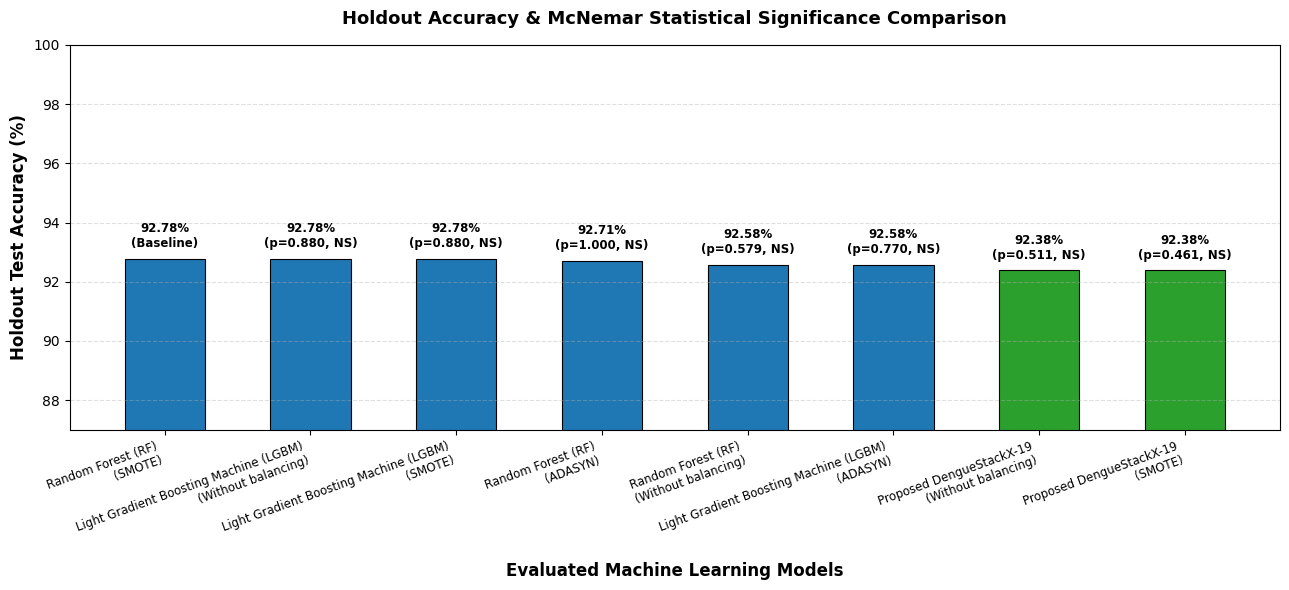


MCNEMAR CONTINGENCY MATRIX OUTPUT FOR THESIS: Random Forest (RF) | SMOTE VS Light Gradient Boosting Machine (LGBM) | Without balancing
Both Models Correct (d)             : 1391
Proposed Correct, Baseline Wrong (b): 22
Proposed Wrong, Baseline Correct (c): 22
Both Models Wrong (a)               : 88
--------------------------------------------------------------------------------
Complete 2x2 Contingency Table Matrix:
[[1391   22]
 [  22   88]]
--------------------------------------------------------------------------------
Chi-Square Statistic (χ²)          : 0.0227
McNemar p-value                     : 0.8802


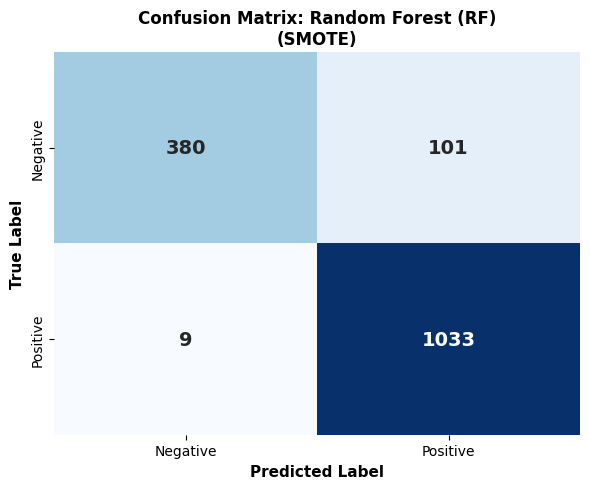


[FINISHED] Everything executed successfully!
1. McNemar Summary saved to 'all_models_with_mcnemar_test.csv'
2. Best Model Saved to 'Dengue_Best_Overall_Model.joblib'
3. Confusion Matrix Saved as 'best_model_confusion_matrix.png'


In [ ]:
#mcnamer test
# ============================================================================
# DENGUE FEVER PREDICTION: FULL PIPELINE WITH MCNEMAR TEST & THESIS VISUALIZATION
# ============================================================================
import warnings
warnings.filterwarnings("ignore")

import os
import time
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# McNemar Test Library
from statsmodels.stats.contingency_tables import mcnemar

# ----------------------------------------------------------------------------
# IMBALANCED-LEARN & OPTIONAL LIBRARIES
# ----------------------------------------------------------------------------
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE, ADASYN
    from imblearn.under_sampling import TomekLinks
    from imblearn.combine import SMOTEENN, SMOTETomek
    HAS_IMBLEARN = True
except ImportError:
    HAS_IMBLEARN = False
    from sklearn.pipeline import Pipeline as ImbPipeline
    print("WARNING: imbalanced-learn is not installed.")

try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False

# ----------------------------------------------------------------------------
# CONFIGURATION & PATHS
# ----------------------------------------------------------------------------
SEED = 42
np.random.seed(SEED)

CACHE_DIR = "dafodil_repro_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

TRAIN_DATA_FILE = "https://raw.githubusercontent.com/ashraful159/Dengue_Fever_Prediction/refs/heads/main/Dengue%20Fever%20Hematological%20Dataset%20Clinical%20Insights%20for%20Improved%20Diagnosis%20and%20Patient%20Management/new_dataset/dafodil_2086_new-.csv"
TEST_DATA_FILE = "https://raw.githubusercontent.com/ashraful159/Dengue_Fever_Prediction/refs/heads/main/Dengue%20Fever%20Hematological%20Dataset%20Clinical%20Insights%20for%20Improved%20Diagnosis%20and%20Patient%20Management/new_dataset/Dengue%20Fever%20Hematological%20Dataset.csv"

EXPECTED_COLUMNS = [
    "Gender", "Age", "Hemoglobin(g/dl)", "Neutrophils(%)", "Lymphocytes(%)",
    "Monocytes(%)", "Eosinophils(%)", "RBC", "HCT(%)", "MCV(fl)",
    "MCH(pg)", "MCHC(g/dl)", "RDW-CV(%)", "Total Platelet Count(/cumm)",
    "MPV(fl)", "PDW(%)", "PCT(%)", "Total WBC count(/cumm)", "Result"
]

TARGET_COL = "Result"
FEATURE_COLS = [c for c in EXPECTED_COLUMNS if c != TARGET_COL]
NUMERIC_COLS = [c for c in FEATURE_COLS if c != "Gender"]
ADOPTED_OUTLIER_COLS = [c for c in NUMERIC_COLS if c not in ("PCT(%)", "Total WBC count(/cumm)")]

# ----------------------------------------------------------------------------
# 100% LEAKAGE-FREE CUSTOM TRANSFORMER: IQR CLIPPER
# ----------------------------------------------------------------------------
class IQRClipper(BaseEstimator, TransformerMixin):
    def __init__(self, columns=None, factor=1.5):
        self.columns = columns
        self.factor = factor

    def fit(self, X, y=None):
        X_mat = np.asarray(X)
        if isinstance(X, pd.DataFrame):
            self.col_indices_ = [X.columns.get_loc(c) for c in self.columns if c in X.columns]
        else:
            self.col_indices_ = [FEATURE_COLS.index(c) for c in self.columns if c in FEATURE_COLS]

        self.lower_bounds_ = {}
        self.upper_bounds_ = {}

        for idx in self.col_indices_:
            col_data = X_mat[:, idx]
            valid_data = col_data[~np.isnan(col_data)]
            q1 = np.percentile(valid_data, 25)
            q3 = np.percentile(valid_data, 75)
            iqr = q3 - q1
            self.lower_bounds_[idx] = q1 - self.factor * iqr
            self.upper_bounds_[idx] = q3 + self.factor * iqr
        return self

    def transform(self, X):
        X_out = np.array(X, copy=True)
        for idx in self.col_indices_:
            X_out[:, idx] = np.clip(X_out[:, idx], a_min=self.lower_bounds_[idx], a_max=self.upper_bounds_[idx])
        return X_out

# ----------------------------------------------------------------------------
# DATA PREPROCESSING
# ----------------------------------------------------------------------------
def preprocess_dataset(data):
    df = data.copy()
    if df["Gender"].dtype == object:
        df["Gender"] = df["Gender"].astype(str).str.strip().str.lower().map({"male": 1, "female": 0})
    if df["Result"].dtype == object:
        df["Result"] = df["Result"].astype(str).str.strip().str.lower().map({"positive": 1, "negative": 0})
    return df

print("=" * 80)
print("LOADING DATASETS")
print("=" * 80)

df_train_raw = pd.read_csv(TRAIN_DATA_FILE)
df_train_raw.columns = [c.strip() for c in df_train_raw.columns]

df_test_raw = pd.read_csv(TEST_DATA_FILE)
df_test_raw.columns = [c.strip() for c in df_test_raw.columns]

print(f"Dataset 2 original shape: {df_train_raw.shape}")
print(f"Dataset 1 external test shape: {df_test_raw.shape}")

df_train = preprocess_dataset(df_train_raw).dropna(subset=EXPECTED_COLUMNS).reset_index(drop=True)
df_test = preprocess_dataset(df_test_raw).dropna(subset=EXPECTED_COLUMNS).reset_index(drop=True)

X_train = df_train[FEATURE_COLS].copy()
y_train = df_train[TARGET_COL].astype(int).copy()

X_test = df_test[FEATURE_COLS].copy()
y_test = df_test[TARGET_COL].astype(int).copy()

print("\n" + "=" * 80)
print("OUTLIER REMOVAL & DATASET INFORMATION")
print("=" * 80)
print(f"Training samples : {len(df_train)}")
print(f"External test    : {len(df_test)}")

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nExternal test class distribution:")
print(y_test.value_counts())

# ----------------------------------------------------------------------------
# BUILDERS & PIPELINE
# ----------------------------------------------------------------------------
def make_samplers(seed=SEED):
    if not HAS_IMBLEARN:
        return {"Without balancing": None}
    return {
        "Without balancing": None,
        "SMOTE": SMOTE(random_state=seed),
        "SMOTETomek": SMOTETomek(random_state=seed),
        "ADASYN": ADASYN(random_state=seed, sampling_strategy="minority"),
        "Tomek links": TomekLinks(),
        "SMOTEENN": SMOTEENN(random_state=seed)
    }

def make_base_learners(seed=SEED):
    learners = [
        ("rf", RandomForestClassifier(n_estimators=300, max_depth=30, min_samples_split=5, random_state=seed, n_jobs=-1)),
        ("dt", DecisionTreeClassifier(criterion="entropy", splitter="random", min_samples_split=5, random_state=seed)),
        ("svm", SVC(kernel="rbf", C=1, gamma=0.1, probability=True, random_state=seed)),
        ("knn", KNeighborsClassifier(n_neighbors=3, leaf_size=4, p=1))
    ]
    if HAS_LGBM:
        learners.append(("lgbm", LGBMClassifier(random_state=seed, verbose=-1)))
    return learners

def make_stack(seed=SEED):
    return StackingClassifier(
        estimators=make_base_learners(seed),
        final_estimator=LogisticRegression(max_iter=1000, random_state=seed),
        stack_method="predict_proba",
        cv=5,
        n_jobs=-1
    )

def make_models(seed=SEED):
    base = dict(make_base_learners(seed))
    models = {
        "Logistic Regression (LR)": LogisticRegression(max_iter=1000, random_state=seed),
        "Decision Tree (DT)": base["dt"],
        "Random Forest (RF)": base["rf"],
        "Support Vector Machine (SVM)": base["svm"],
        "K-Nearest Neighbors (KNN)": base["knn"],
        "Proposed DengueStackX-19": make_stack(seed)
    }
    if HAS_LGBM:
        models["Light Gradient Boosting Machine (LGBM)"] = base["lgbm"]
    return models

LEAKAGE_SAFE_STACK = True   # True: resampling is done INSIDE every base learner (leakage-safe stacking)

def _leakage_safe_stack(stack, sampler):
    """Move the balancer from in front of the stack into each base learner, so the stack's internal
    5-fold never sees synthetic samples generated from its own validation fold."""
    est = [(n, ImbPipeline([("balancer", clone(sampler)), ("clf", clone(e))])) for n, e in stack.estimators]
    return StackingClassifier(estimators=est, final_estimator=clone(stack.final_estimator),
                              stack_method=stack.stack_method, cv=stack.cv, n_jobs=stack.n_jobs)

def build_pipeline(model, sampler):
    steps = [
        ("outlier_handler", IQRClipper(columns=ADOPTED_OUTLIER_COLS, factor=1.5)),
        ("scaler", StandardScaler())
    ]
    if sampler is not None and LEAKAGE_SAFE_STACK and isinstance(model, StackingClassifier):
        model = _leakage_safe_stack(model, sampler)   # balancer inside every base learner
    elif sampler is not None:
        steps.append(("balancer", clone(sampler)))  # FIX: never share a sampler object
    steps.append(("model", clone(model)))  # FIX: fresh estimator per pipeline (Pipeline.fit does NOT clone it)
    return ImbPipeline(steps=steps)

def compute_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision (%)": precision_score(y_true, y_pred, zero_division=0) * 100,
        "Recall / Sensitivity (%)": recall_score(y_true, y_pred, zero_division=0) * 100,
        "Specificity (%)": (tn / (tn + fp) if (tn + fp) > 0 else 0) * 100,
        "F1-score (%)": f1_score(y_true, y_pred, zero_division=0) * 100
    }

# ----------------------------------------------------------------------------
# EXHAUSTIVE EVALUATION WITH MCNEMAR PREDICTION RECORDING
# ----------------------------------------------------------------------------
CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
all_combinations_rows = []
fitted_pipelines = {}
test_predictions_dict = {}

samplers_dict = make_samplers(SEED)
models_dict = make_models(SEED)

print("\nBalancing approaches included:")
for approach in samplers_dict.keys():
    print(f" - {approach}")

total_runs = len(models_dict) * len(samplers_dict)

print("\n" + "=" * 80)
print(f"ALL MODELS X ALL BALANCING — 10-FOLD CV & HOLDOUT TEST ({total_runs} COMBINATIONS)")
print("=" * 80)

for model_name, model in models_dict.items():
    print(f"\nProcessing Model: {model_name}...")
    for approach_name, sampler in samplers_dict.items():

        pipeline = build_pipeline(model, sampler)

        # 1. 10-Fold Cross-Validation
        cv_scores = cross_validate(pipeline, X_train, y_train, cv=CV, scoring={"accuracy": "accuracy"}, n_jobs=-1)
        cv_acc = cv_scores["test_accuracy"].mean() * 100

        # 2. Fit on Full Dataset 2 & Predict on Dataset 1
        pipeline.fit(X_train, y_train)
        test_pred = pipeline.predict(X_test)
        ext_metrics = compute_metrics(y_test, test_pred)

        key_name = f"{model_name} | {approach_name}"
        fitted_pipelines[key_name] = pipeline
        test_predictions_dict[key_name] = test_pred

        all_combinations_rows.append({
            "Key": key_name,
            "Model": model_name,
            "Balancing": approach_name,
            "10-Fold CV Acc (%) [Dataset 2]": cv_acc,
            "Holdout Test Acc (%) [Dataset 1]": ext_metrics["Accuracy (%)"],
            "Holdout Precision (%)": ext_metrics["Precision (%)"],
            "Holdout Recall (%)": ext_metrics["Recall / Sensitivity (%)"],
            "Holdout Specificity (%)": ext_metrics["Specificity (%)"],
            "Holdout F1-score (%)": ext_metrics["F1-score (%)"]
        })

# Convert to DataFrame & Sort to identify Baseline
full_table_df = pd.DataFrame(all_combinations_rows)
full_table_df_sorted = full_table_df.sort_values(
    by=["Holdout Test Acc (%) [Dataset 1]", "10-Fold CV Acc (%) [Dataset 2]"],
    ascending=[False, False]
).reset_index(drop=True)

# ----------------------------------------------------------------------------
# MCNEMAR'S STATISTICAL TEST VS BEST BASELINE MODEL
# ----------------------------------------------------------------------------
baseline_key = full_table_df_sorted.iloc[0]["Key"]
baseline_pred = test_predictions_dict[baseline_key]

p_values = []
sig_flags = []

for idx, row in full_table_df_sorted.iterrows():
    current_key = row["Key"]
    if current_key == baseline_key:
        p_values.append(1.000000)
        sig_flags.append("Baseline")
        continue

    current_pred = test_predictions_dict[current_key]

    baseline_correct = (baseline_pred == y_test.values)
    model_correct = (current_pred == y_test.values)

    b = np.sum(baseline_correct & ~model_correct) # Baseline correct, Model wrong
    c = np.sum(~baseline_correct & model_correct) # Baseline wrong, Model correct

    # McNemar's Test
    contingency_table = [[0, b], [c, 0]]
    result = mcnemar(contingency_table, exact=False, correction=True)
    p_val = result.pvalue

    p_values.append(p_val)
    sig_flags.append("Yes" if p_val < 0.05 else "No")

full_table_df_sorted["McNemar p-value (vs Proposed)"] = p_values
full_table_df_sorted["Significantly Different? (p < 0.05)"] = sig_flags

# Drop internal key column for display
output_df = full_table_df_sorted.drop(columns=["Key"])

print("\n" + "=" * 80)
print("FINAL PERFORMANCE COMPARISON TABLE WITH MCNEMAR'S TEST")
print("=" * 80)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(output_df.to_string(index=False))

# ----------------------------------------------------------------------------
# ABSOLUTE BEST MODEL DETAILED EVALUATION
# ----------------------------------------------------------------------------
best_row = output_df.iloc[0]
best_pipeline = fitted_pipelines[baseline_key]

# SAFETY CHECK: the stored pipeline must reproduce the table accuracy (guards against the shared-estimator bug)
_chk = accuracy_score(y_test, best_pipeline.predict(X_test)) * 100
assert abs(_chk - float(best_row['Holdout Test Acc (%) [Dataset 1]'])) < 1e-6, f'Stored pipeline mismatch: {_chk:.4f}'
best_pred = baseline_pred
best_cm = confusion_matrix(y_test, best_pred, labels=[0, 1])
tn, fp, fn, tp = best_cm.ravel()

print("\n" + "=" * 80)
print(f"ABSOLUTE BEST PERFORMING COMBINATION — EXTERNAL RESULT")
print("=" * 80)
print(f"Model Name                    : {best_row['Model']}")
print(f"Balancing Strategy            : {best_row['Balancing']}")
print(f"10-Fold CV Acc (%)            : {best_row['10-Fold CV Acc (%) [Dataset 2]']:.2f}%")
print(f"Holdout Accuracy (%)          : {best_row['Holdout Test Acc (%) [Dataset 1]']:.2f}%")
print(f"Precision (%)                 : {best_row['Holdout Precision (%)']:.2f}%")
print(f"Recall / Sensitivity (%)      : {best_row['Holdout Recall (%)']:.2f}%")
print(f"Specificity (%)               : {best_row['Holdout Specificity (%)']:.2f}%")
print(f"F1-score (%)                  : {best_row['Holdout F1-score (%)']:.2f}%")

# Save Results
output_df.to_csv("all_models_with_mcnemar_test.csv", index=False)
joblib.dump(best_pipeline, "Dengue_Best_Overall_Model.joblib")

# ----------------------------------------------------------------------------
# DIRECT INLINE GRAPH OUTPUT (TOP 8 MODELS)
# ----------------------------------------------------------------------------
top_df = output_df.head(8).copy()

plt.figure(figsize=(13, 6))
plot_labels = [f"{row['Model']}\n({row['Balancing']})" for _, row in top_df.iterrows()]
accuracies = top_df["Holdout Test Acc (%) [Dataset 1]"]
colors = ['#2ca02c' if 'Proposed' in name else '#1f77b4' for name in top_df["Model"]]

bars = plt.bar(plot_labels, accuracies, color=colors, width=0.55, edgecolor='black', linewidth=0.8)

plt.ylabel('Holdout Test Accuracy (%)', fontsize=12, fontweight='bold')
plt.xlabel('Evaluated Machine Learning Models', fontsize=12, fontweight='bold', labelpad=10)
plt.title('Holdout Accuracy & McNemar Statistical Significance Comparison', fontsize=13, fontweight='bold', pad=15)

min_acc = max(70, int(min(accuracies) - 5))
plt.ylim(min_acc, 100)

for bar, p_val, sig in zip(bars, top_df["McNemar p-value (vs Proposed)"], top_df["Significantly Different? (p < 0.05)"]):
    height = bar.get_height()
    if sig == "Baseline":
        text_str = f"{height:.2f}%\n(Baseline)"
    elif sig == "No":
        text_str = f"{height:.2f}%\n(p={p_val:.3f}, NS)"
    else:
        text_str = f"{height:.2f}%\n(p={p_val:.4f}, *)"

    plt.text(bar.get_x() + bar.get_width()/2.0, height + 0.3, text_str,
             ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.xticks(rotation=20, fontsize=8.5, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# ============================================================================
# EXTRACT 2x2 CONTINGENCY MATRIX & CHI-SQUARE FOR THESIS TABLE
# ============================================================================
top1_key = full_table_df_sorted.iloc[0]["Key"]  # Proposed Model
top2_key = full_table_df_sorted.iloc[1]["Key"]  # Top Baseline Model

pred1 = test_predictions_dict[top1_key]
pred2 = test_predictions_dict[top2_key]

corr1 = (pred1 == y_test.values)
corr2 = (pred2 == y_test.values)

# Calculate Matrix Cells
a = np.sum(~corr1 & ~corr2)  # Both Incorrect
b = np.sum(corr1 & ~corr2)   # Proposed Correct, Baseline Incorrect
c = np.sum(~corr1 & corr2)   # Proposed Incorrect, Baseline Correct
d = np.sum(corr1 & corr2)    # Both Correct

full_contingency_matrix = np.array([[d, b], [c, a]])
mcnemar_res = mcnemar([[0, b], [c, 0]], exact=False, correction=True)

print("\n" + "=" * 80)
print(f"MCNEMAR CONTINGENCY MATRIX OUTPUT FOR THESIS: {top1_key} VS {top2_key}")
print("=" * 80)
print(f"Both Models Correct (d)             : {d}")
print(f"Proposed Correct, Baseline Wrong (b): {b}")
print(f"Proposed Wrong, Baseline Correct (c): {c}")
print(f"Both Models Wrong (a)               : {a}")
print("-" * 80)
print("Complete 2x2 Contingency Table Matrix:")
print(full_contingency_matrix)
print("-" * 80)
print(f"Chi-Square Statistic (χ²)          : {mcnemar_res.statistic:.4f}")
print(f"McNemar p-value                     : {mcnemar_res.pvalue:.4f}")
print("=" * 80)

# ============================================================================
# GENERATE CONFUSION MATRIX HEATMAP IMAGE
# ============================================================================
plt.figure(figsize=(6, 5))
sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'],
            annot_kws={"size": 14, "weight": "bold"})

plt.title(f'Confusion Matrix: {best_row["Model"]}\n({best_row["Balancing"]})', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=11, fontweight='bold')
plt.ylabel('True Label', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig("best_model_confusion_matrix.png", dpi=300)
plt.show()

print("\n[FINISHED] Everything executed successfully!")
print("1. McNemar Summary saved to 'all_models_with_mcnemar_test.csv'")
print("2. Best Model Saved to 'Dengue_Best_Overall_Model.joblib'")
print("3. Confusion Matrix Saved as 'best_model_confusion_matrix.png'")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 8.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.4/108.4 kB 12.5 MB/s eta 0:00:00
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=bc4d164a1c6e631934e712885d23cccac0d9fc5d45de04fb45de74dae622ccc8
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime
LOADING DATASETS



RUNNING EXPLAINABLE AI (XAI) FOR BEST MODEL: Proposed DengueStackX-19 | ADASYN


PermutationExplainer explainer: 201it [24:05,  7.23s/it]



FEATURE IMPORTANCE RANK BY XAI METHOD (1 = MOST IMPORTANT)
                             SHAP  LIME  ELI5
Gender                         18    14    15
Age                            10    10     8
Hemoglobin(g/dl)               16    17    18
Neutrophils(%)                  5    11     6
Lymphocytes(%)                 13    12    12
Monocytes(%)                    4     3     3
Eosinophils(%)                 11    13     7
RBC                            14    18    14
HCT(%)                         12     7    16
MCV(fl)                        15    15    13
MCH(pg)                        17    16    17
MCHC(g/dl)                      7     5    10
RDW-CV(%)                       9     8     5
Total Platelet Count(/cumm)     1     1     1
MPV(fl)                         8     6     9
PDW(%)                          6     9    11
PCT(%)                          3     2     2
Total WBC count(/cumm)          2     4     4

XAI ANALYSIS FINISHED SUCCESSFULLY!
Saved artifacts:
 - xai_shap_

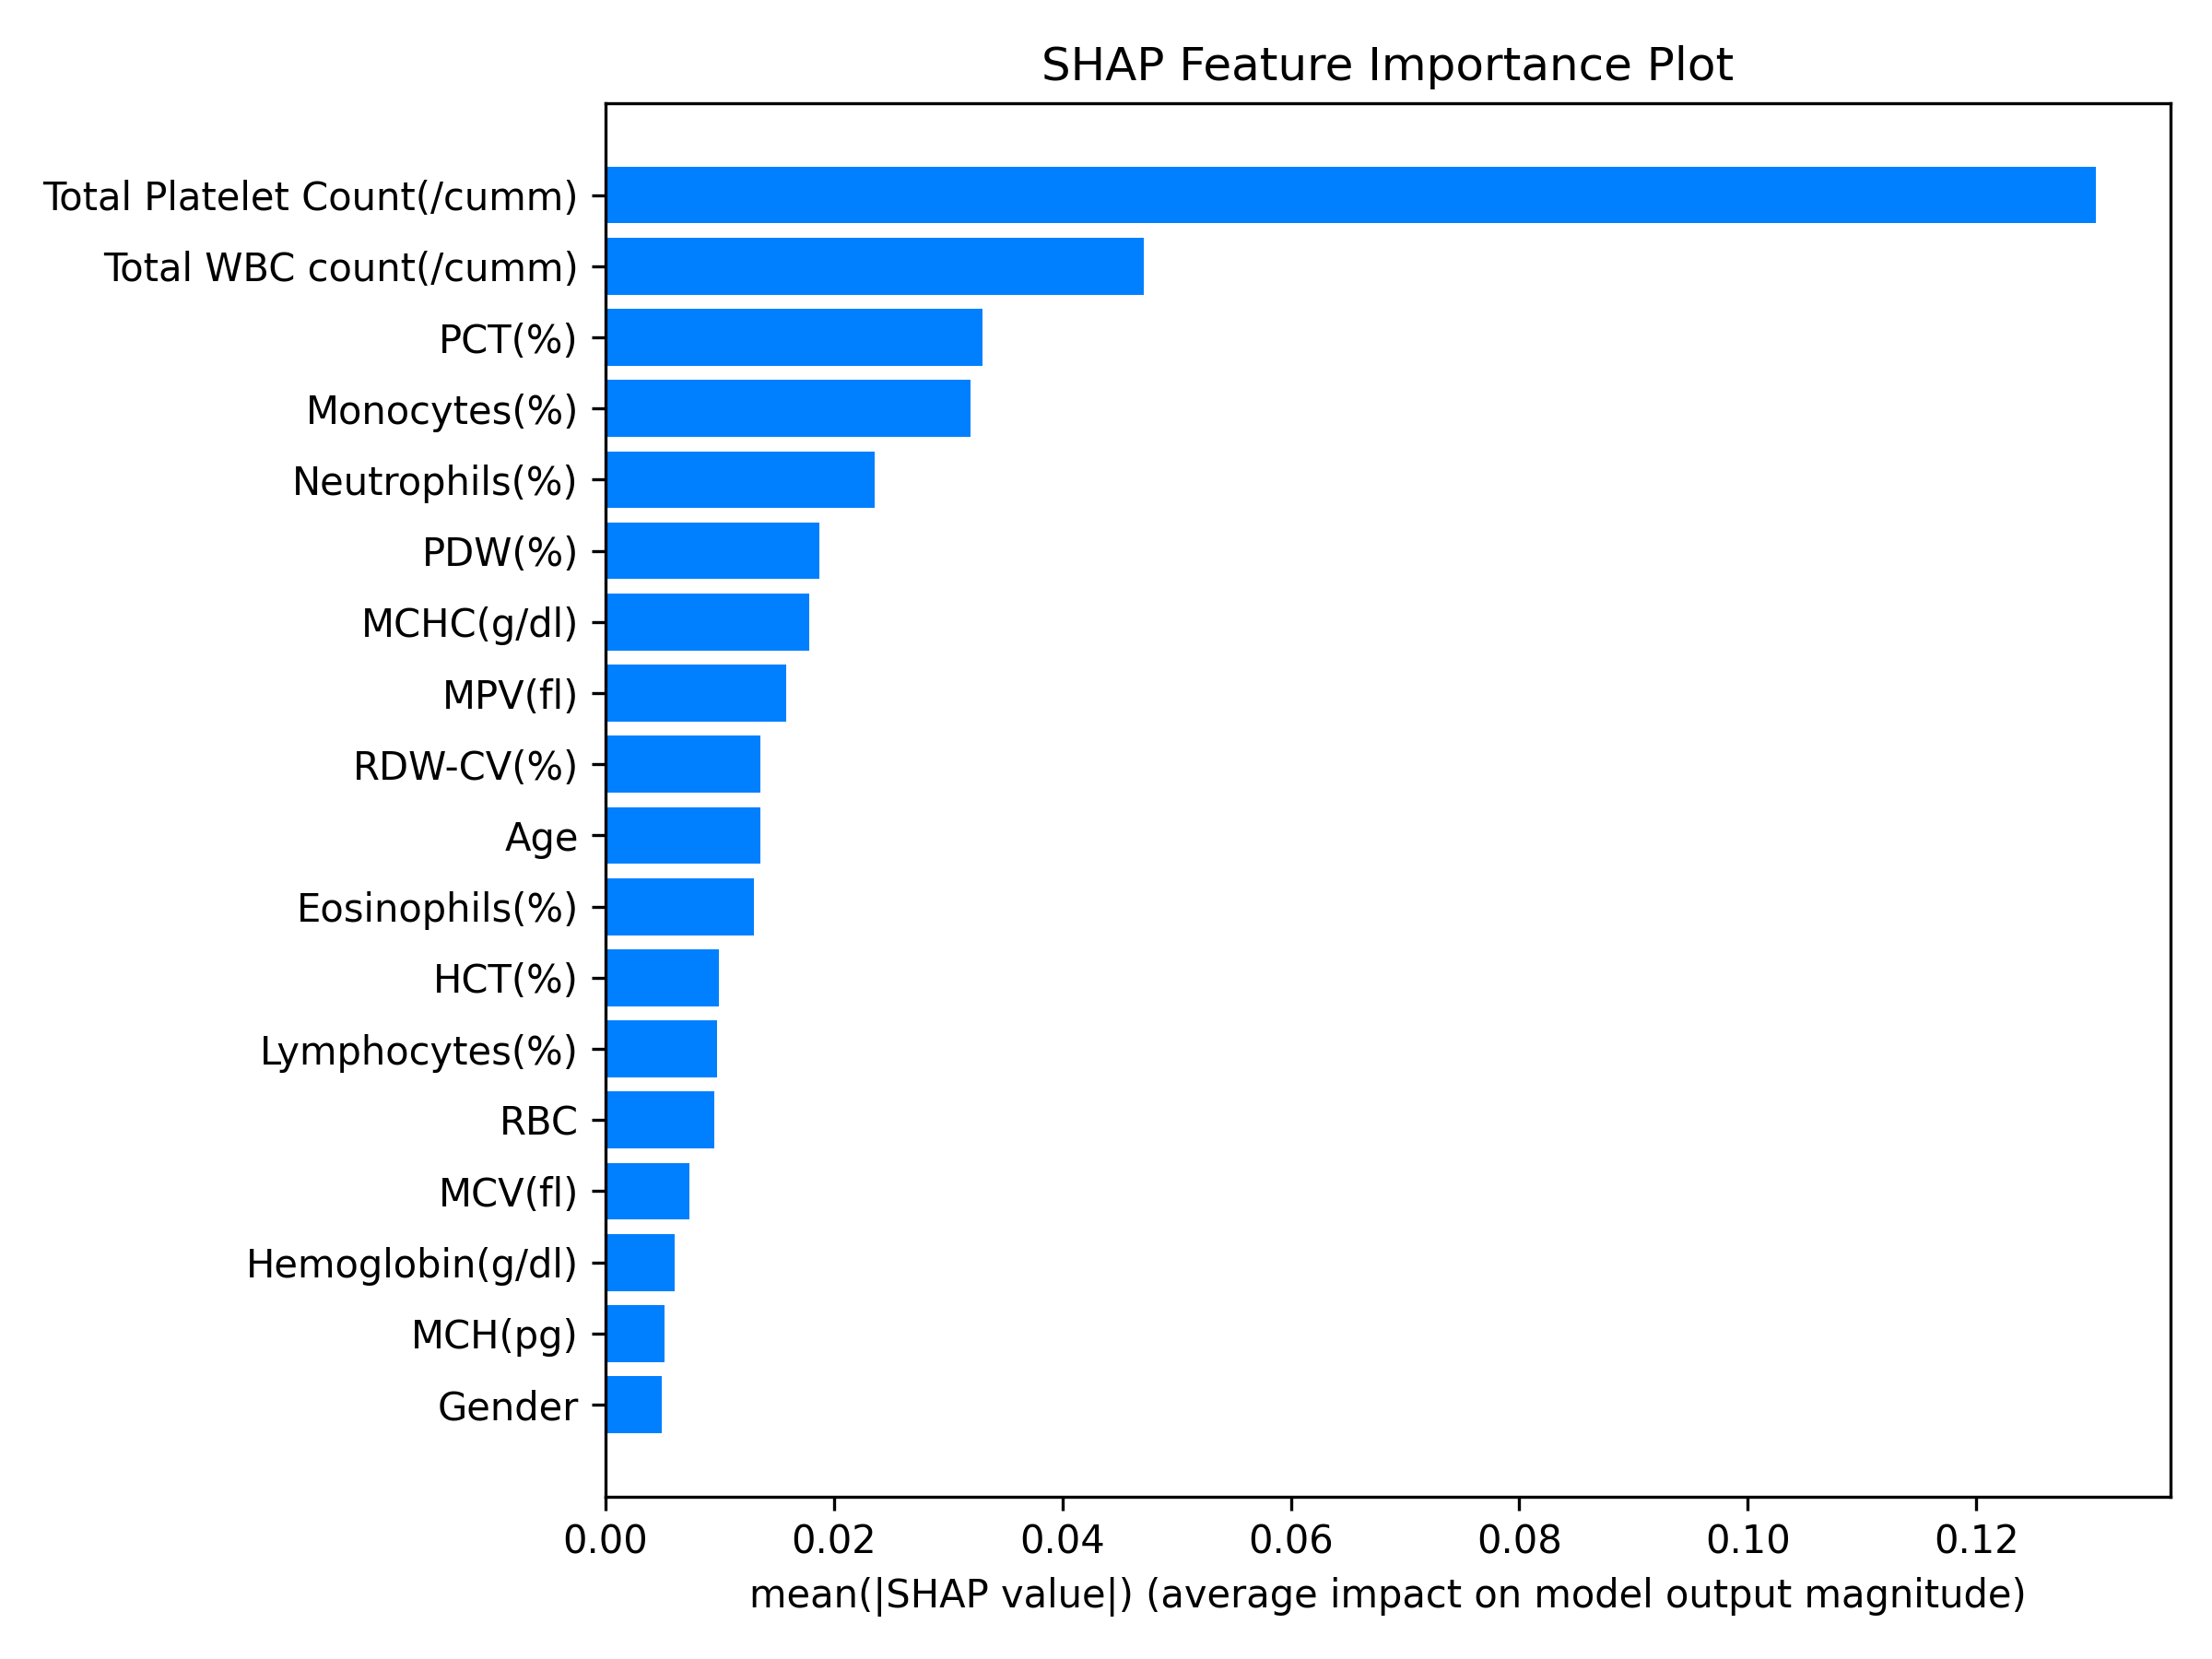


--- 2. LIME Explanation (Single Instance) ---


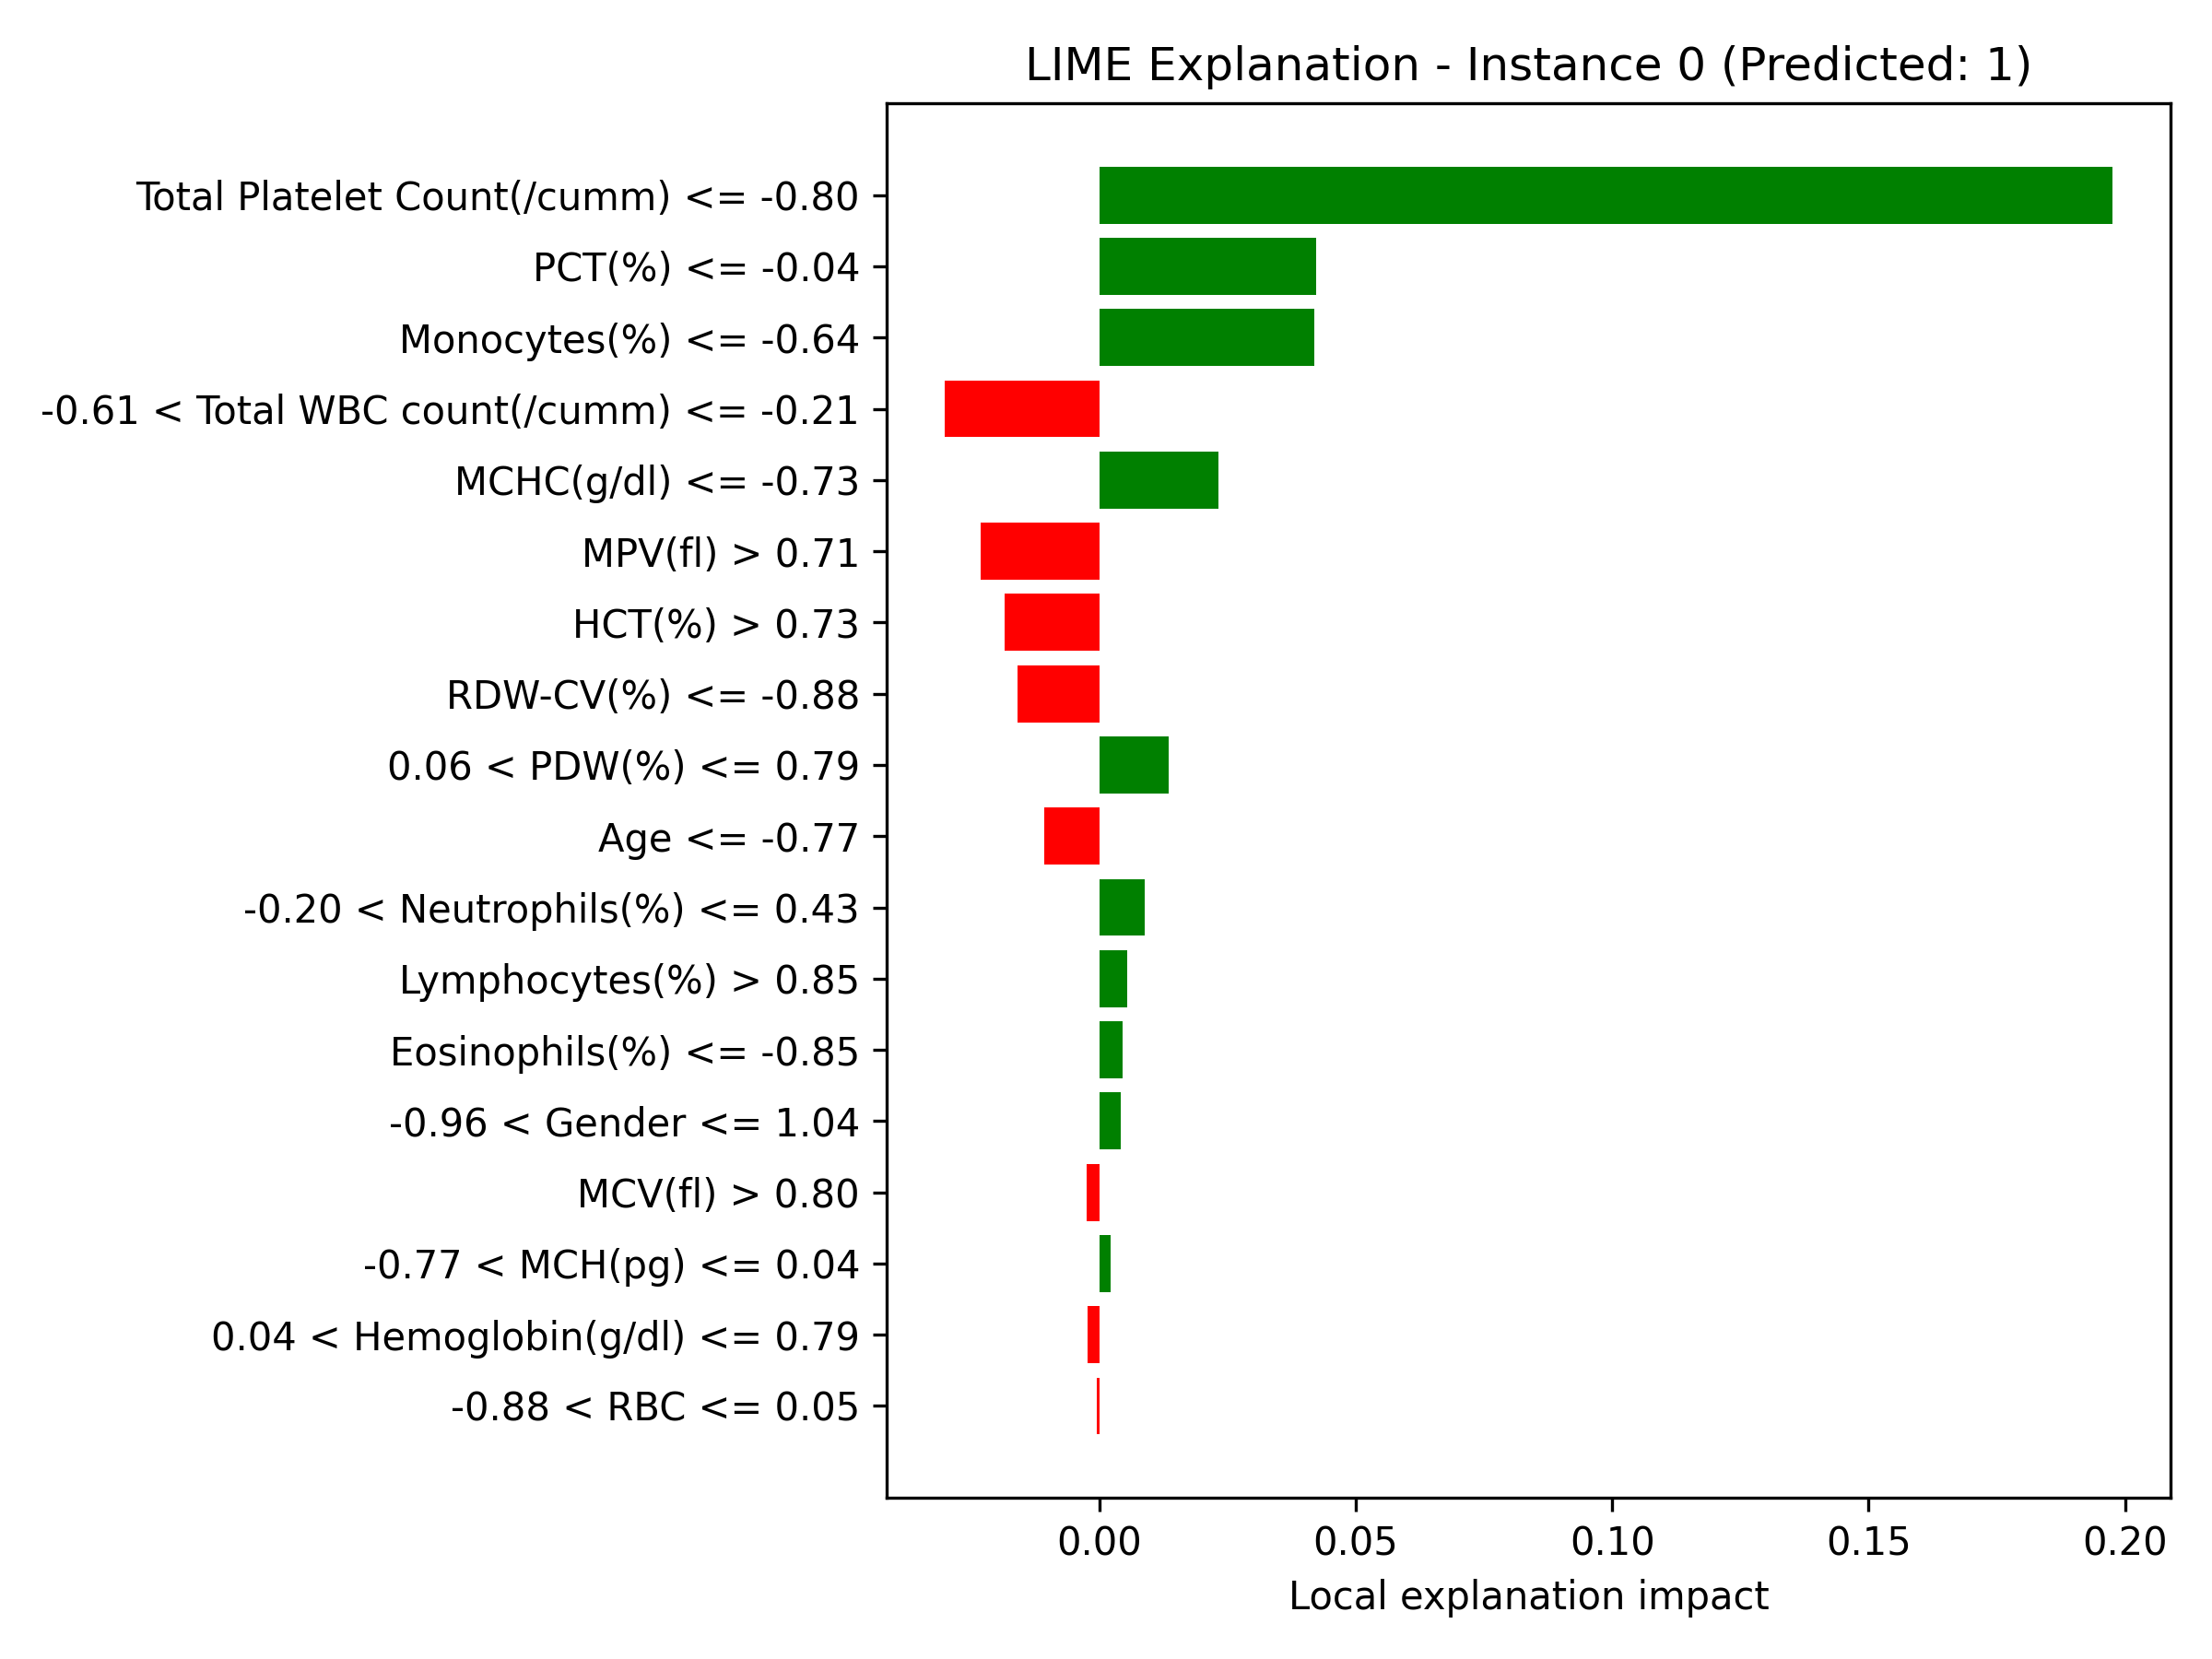


--- 3. ELI5 Permutation Importance Plot ---


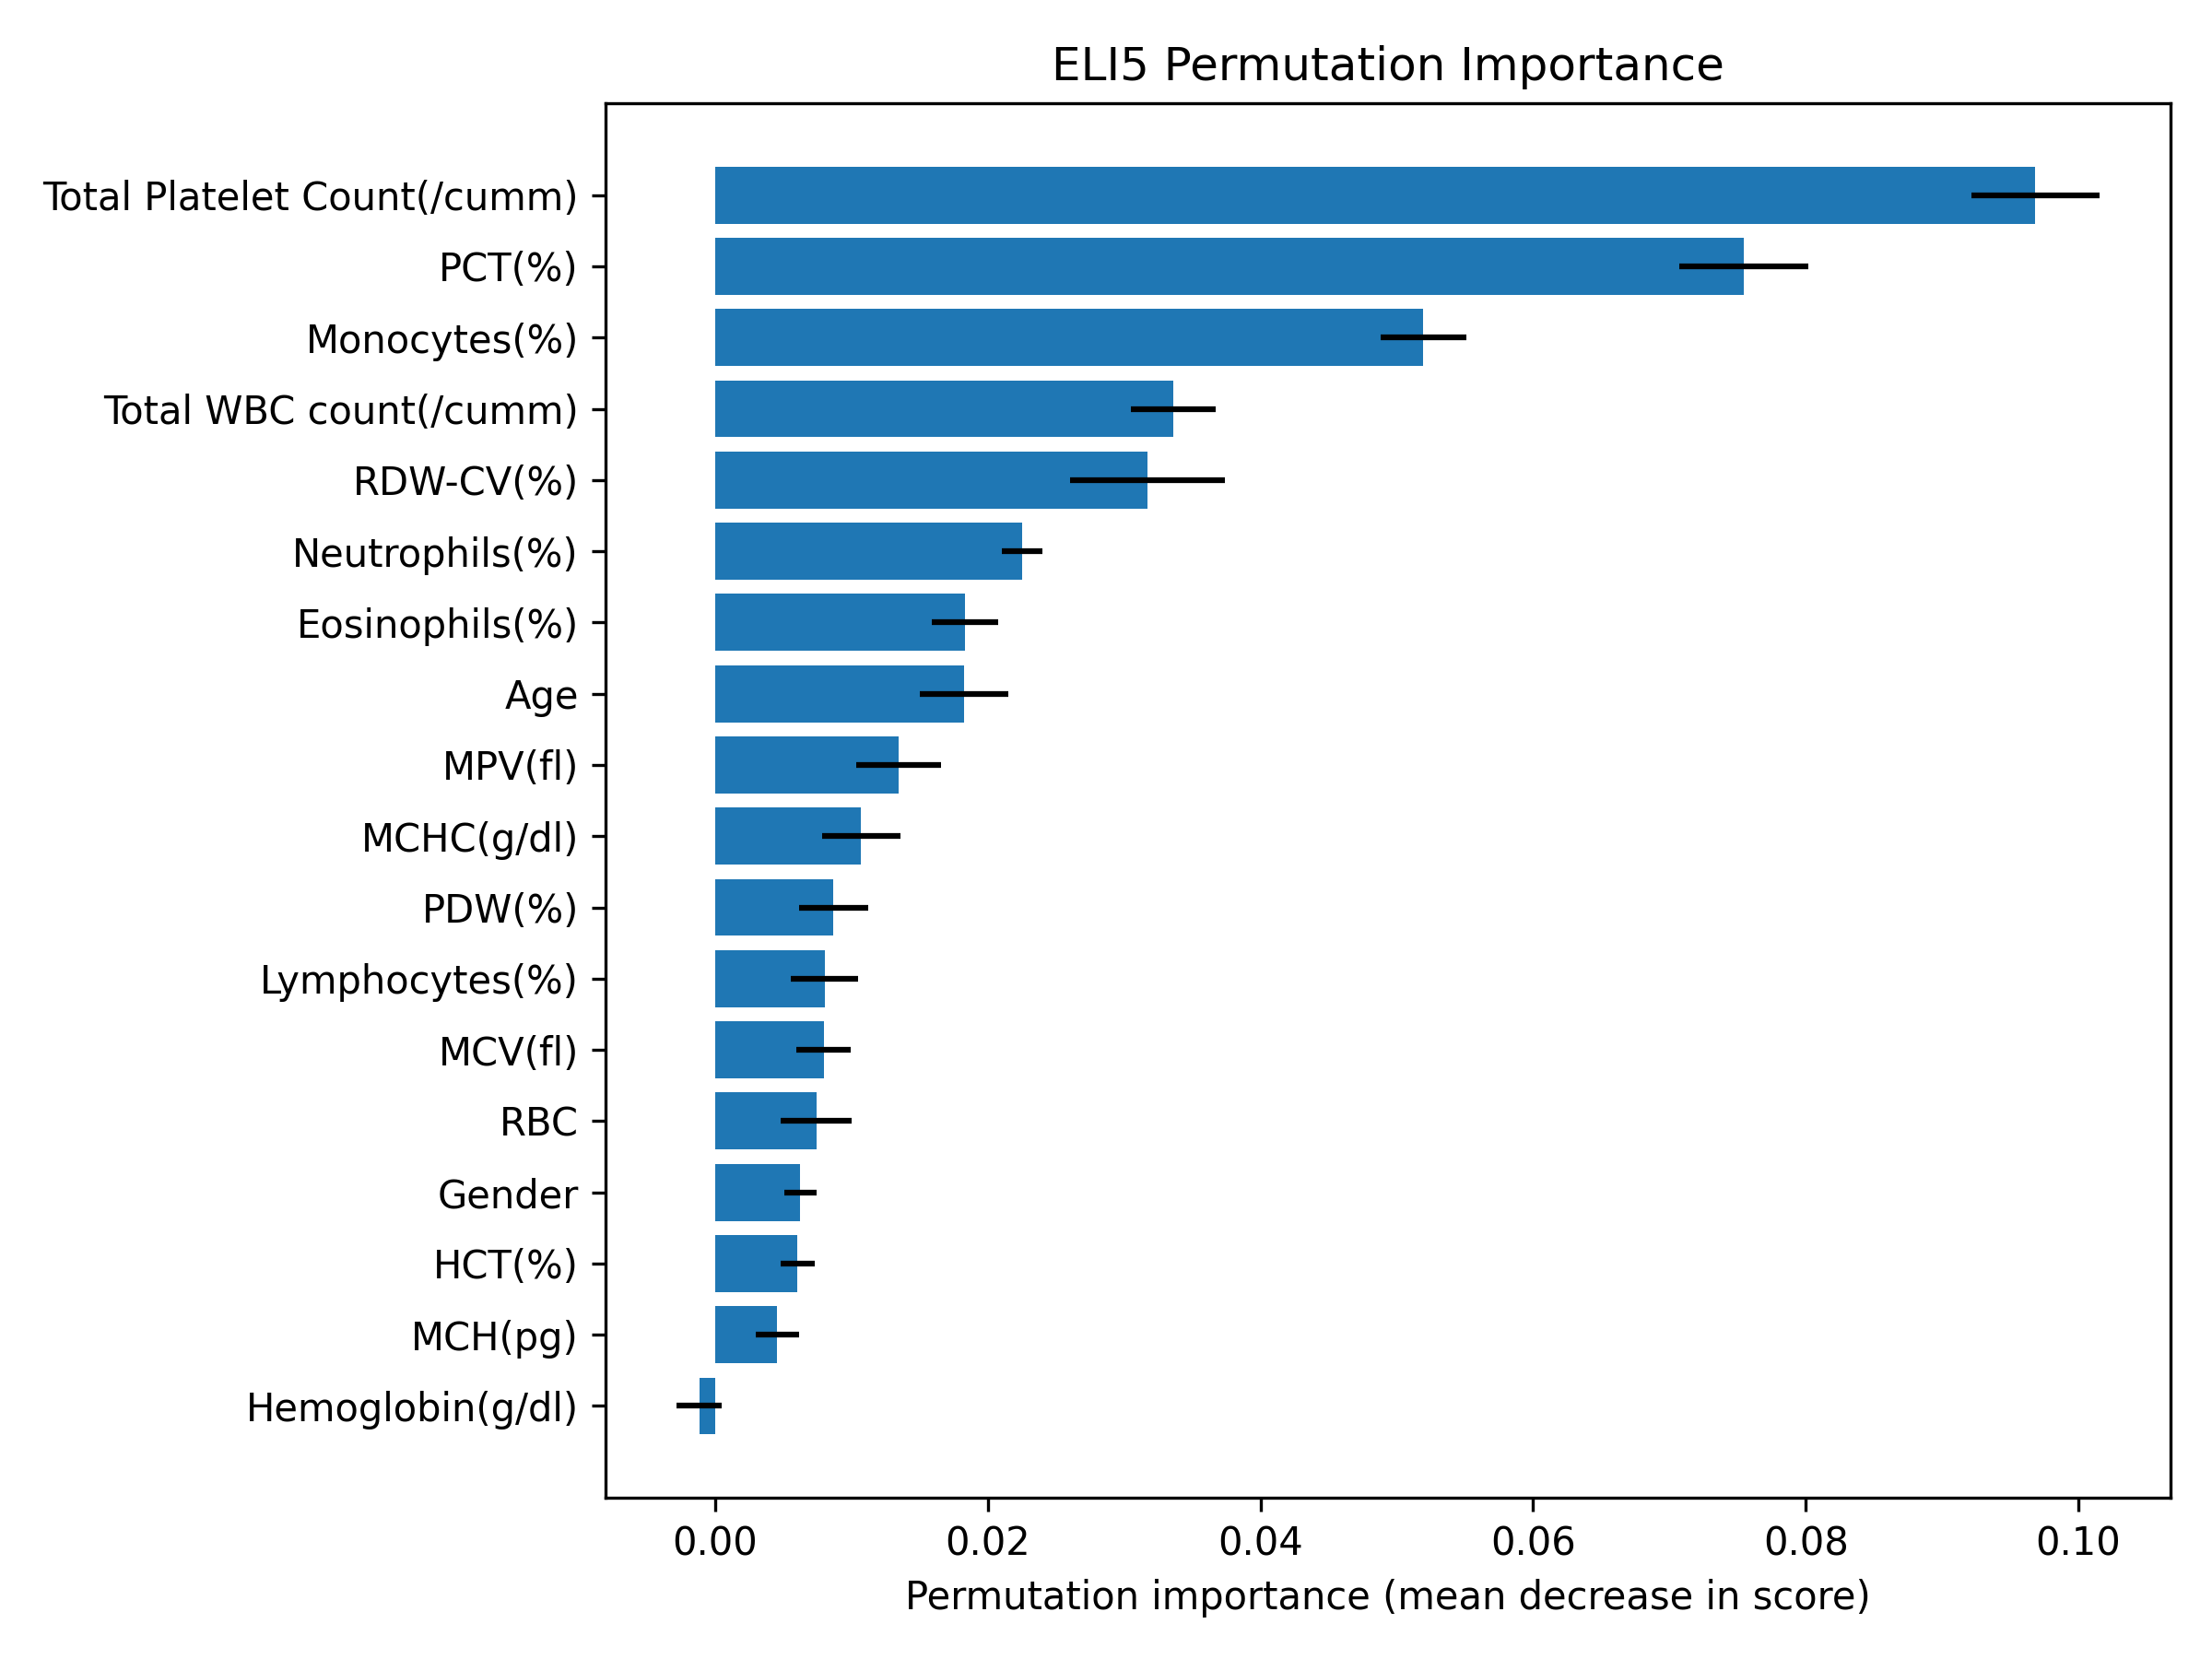


--- 4. Feature Importance Rank Heatmap ---


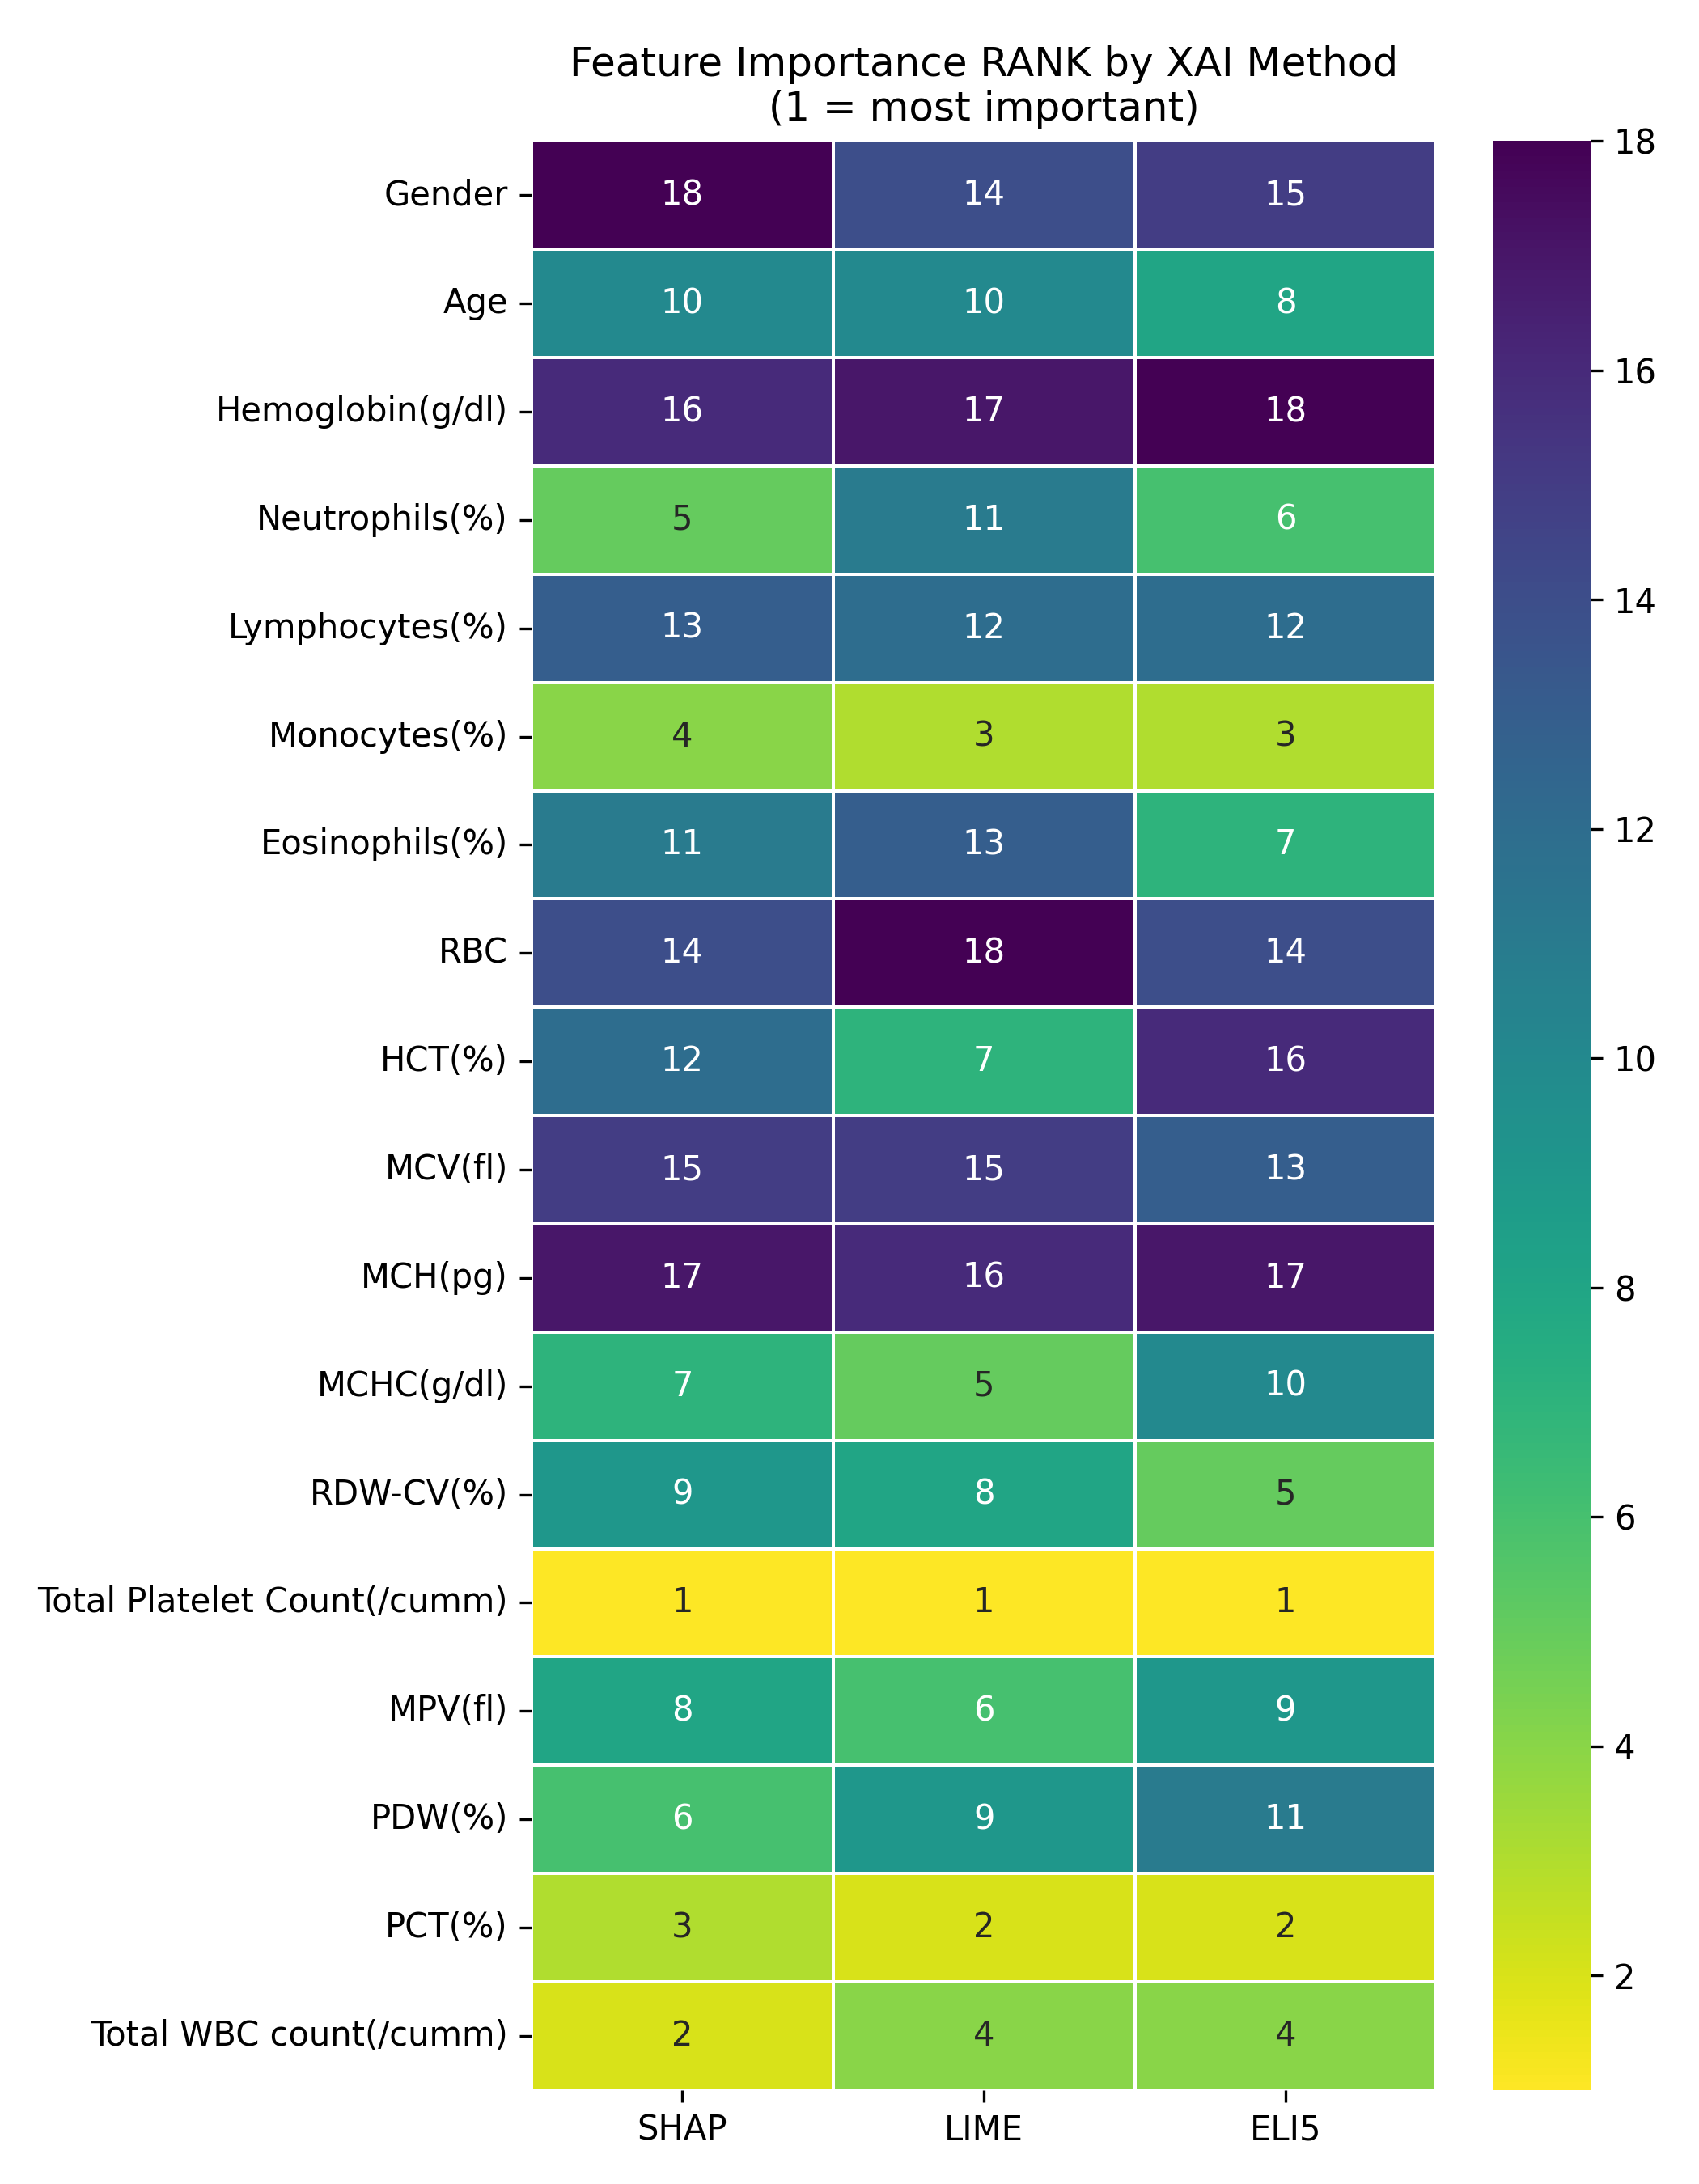

All external: n=1523 acc=0.9225 rec=0.9655 spec=0.8295 prec=0.9246 AUC=0.9490
   CM [[TN,FP],[FN,TP]]: [[399, 82], [36, 1006]]
Non-overlapping: n=1299 acc=0.9145 rec=0.9683 spec=0.7865 prec=0.9153 AUC=0.9354
   CM [[TN,FP],[FN,TP]]: [[302, 82], [29, 886]]
Overlapping: n=224 acc=0.9688 rec=0.9449 spec=1.0000 prec=1.0000 AUC=0.9991
   CM [[TN,FP],[FN,TP]]: [[97, 0], [7, 120]]
AUC = 0.9490, bootstrap 95% CI = [0.9359 0.9604]


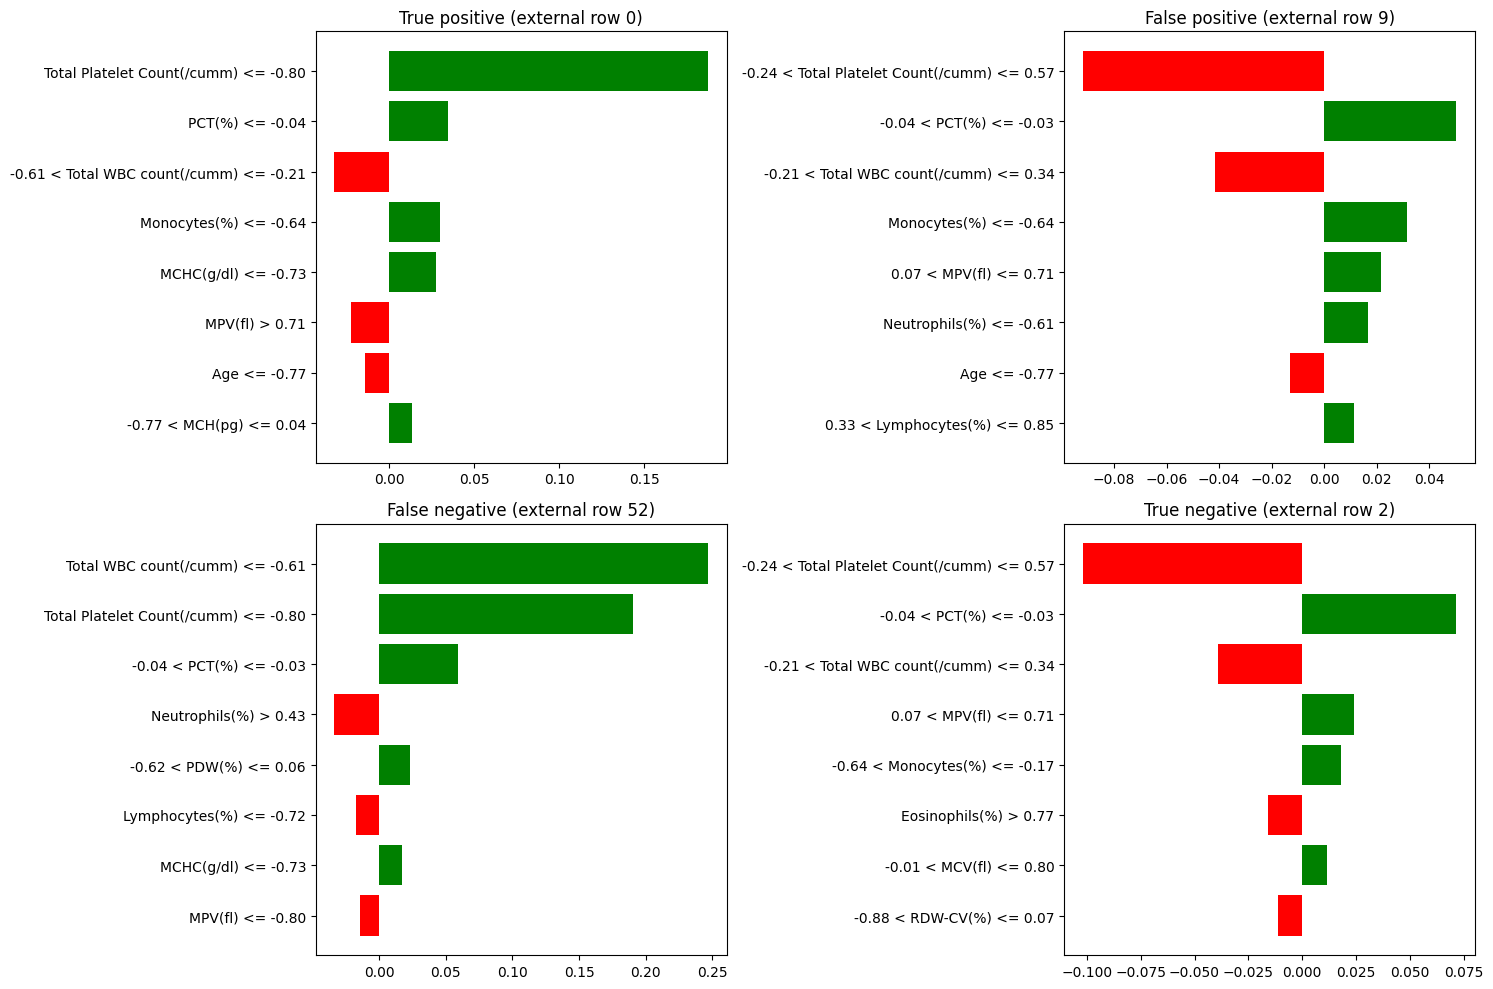

Total WBC count(/cumm)         0.1274
Total Platelet Count(/cumm)    0.1224
PCT(%)                         0.0665
Monocytes(%)                   0.0395
Neutrophils(%)                 0.0222
Eosinophils(%)                 0.0151
RBC                            0.0142
PDW(%)                         0.0140
Lymphocytes(%)                 0.0107
MPV(fl)                        0.0057
RDW-CV(%)                      0.0034
Age                            0.0017
MCV(fl)                       -0.0013
Gender                        -0.0019
HCT(%)                        -0.0019
MCHC(g/dl)                    -0.0027
MCH(pg)                       -0.0036
Hemoglobin(g/dl)              -0.0046
                                    TP         FP         FN         TN
Age                              40.00      44.50      38.00      34.00
Hemoglobin(g/dl)                 14.52      14.75      14.20      14.74
Neutrophils(%)                   45.00      44.00      44.50      44.00
Lymphocytes(%)              

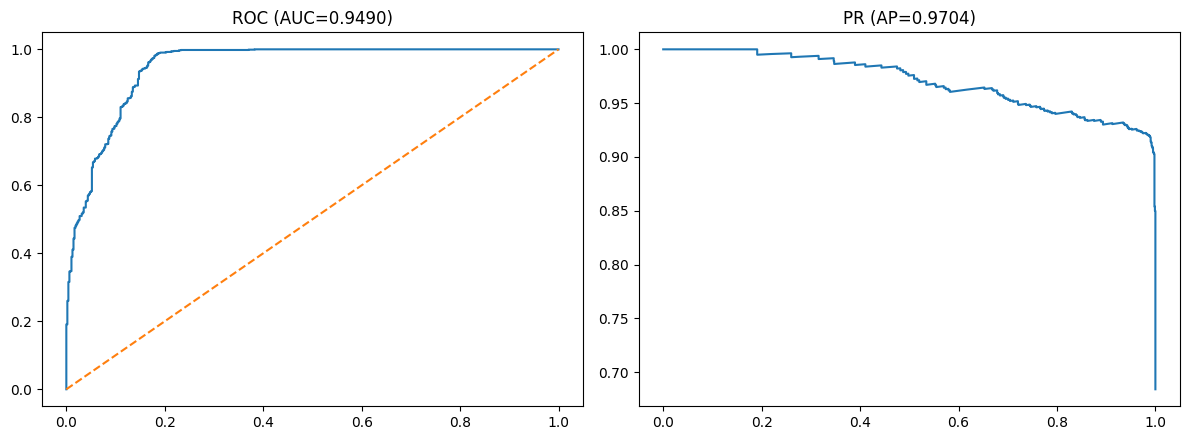

In [ ]:
#shap, lime , eli5
!pip install shap lime eli5 matplotlib seaborn
import warnings
warnings.filterwarnings("ignore")

import os
import time
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

# XAI LIBRARIES
import shap
from lime import lime_tabular
import eli5

# ----------------------------------------------------------------------------
# IMBALANCED-LEARN & OPTIONAL LIBRARIES
# ----------------------------------------------------------------------------
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE, ADASYN
    from imblearn.under_sampling import TomekLinks
    from imblearn.combine import SMOTEENN, SMOTETomek
    HAS_IMBLEARN = True
except ImportError:
    HAS_IMBLEARN = False
    from sklearn.pipeline import Pipeline as ImbPipeline
    print("WARNING: imbalanced-learn is not installed.")

try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False

# ----------------------------------------------------------------------------
# CONFIGURATION & PATHS
# ----------------------------------------------------------------------------
SEED = 42
np.random.seed(SEED)

CACHE_DIR = "dafodil_repro_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

TRAIN_DATA_FILE = "https://raw.githubusercontent.com/ashraful159/Dengue_Fever_Prediction/refs/heads/main/Dengue%20Fever%20Hematological%20Dataset%20Clinical%20Insights%20for%20Improved%20Diagnosis%20and%20Patient%20Management/new_dataset/dafodil_2086_new-.csv"
TEST_DATA_FILE = "https://raw.githubusercontent.com/ashraful159/Dengue_Fever_Prediction/refs/heads/main/Dengue%20Fever%20Hematological%20Dataset%20Clinical%20Insights%20for%20Improved%20Diagnosis%20and%20Patient%20Management/new_dataset/Dengue%20Fever%20Hematological%20Dataset.csv"

EXPECTED_COLUMNS = [
    "Gender", "Age", "Hemoglobin(g/dl)", "Neutrophils(%)", "Lymphocytes(%)",
    "Monocytes(%)", "Eosinophils(%)", "RBC", "HCT(%)", "MCV(fl)",
    "MCH(pg)", "MCHC(g/dl)", "RDW-CV(%)", "Total Platelet Count(/cumm)",
    "MPV(fl)", "PDW(%)", "PCT(%)", "Total WBC count(/cumm)", "Result"
]

TARGET_COL = "Result"
FEATURE_COLS = [c for c in EXPECTED_COLUMNS if c != TARGET_COL]
NUMERIC_COLS = [c for c in FEATURE_COLS if c != "Gender"]
ADOPTED_OUTLIER_COLS = [c for c in NUMERIC_COLS if c not in ("PCT(%)", "Total WBC count(/cumm)")]

# ----------------------------------------------------------------------------
# LEAKAGE-FREE CUSTOM TRANSFORMER: IQR CLIPPER
# ----------------------------------------------------------------------------
class IQRClipper(BaseEstimator, TransformerMixin):
    def __init__(self, columns=None, factor=1.5):
        self.columns = columns
        self.factor = factor

    def fit(self, X, y=None):
        X_mat = np.asarray(X)
        if isinstance(X, pd.DataFrame):
            self.col_indices_ = [X.columns.get_loc(c) for c in self.columns if c in X.columns]
        else:
            self.col_indices_ = [FEATURE_COLS.index(c) for c in self.columns if c in FEATURE_COLS]

        self.lower_bounds_ = {}
        self.upper_bounds_ = {}

        for idx in self.col_indices_:
            col_data = X_mat[:, idx]
            valid_data = col_data[~np.isnan(col_data)]
            q1 = np.percentile(valid_data, 25)
            q3 = np.percentile(valid_data, 75)
            iqr = q3 - q1
            self.lower_bounds_[idx] = q1 - self.factor * iqr
            self.upper_bounds_[idx] = q3 + self.factor * iqr
        return self

    def transform(self, X):
        X_out = np.array(X, copy=True)
        for idx in self.col_indices_:
            X_out[:, idx] = np.clip(X_out[:, idx], a_min=self.lower_bounds_[idx], a_max=self.upper_bounds_[idx])
        return X_out

# ----------------------------------------------------------------------------
# DATA PREPROCESSING
# ----------------------------------------------------------------------------
def preprocess_dataset(data):
    df = data.copy()
    if df["Gender"].dtype == object:
        df["Gender"] = df["Gender"].astype(str).str.strip().str.lower().map({"male": 1, "female": 0})
    if df["Result"].dtype == object:
        df["Result"] = df["Result"].astype(str).str.strip().str.lower().map({"positive": 1, "negative": 0})
    return df

print("=" * 80)
print("LOADING DATASETS")
print("=" * 80)

df_train_raw = pd.read_csv(TRAIN_DATA_FILE)
df_train_raw.columns = [c.strip() for c in df_train_raw.columns]

df_test_raw = pd.read_csv(TEST_DATA_FILE)
df_test_raw.columns = [c.strip() for c in df_test_raw.columns]

df_train = preprocess_dataset(df_train_raw).dropna(subset=EXPECTED_COLUMNS).reset_index(drop=True)
df_test = preprocess_dataset(df_test_raw).dropna(subset=EXPECTED_COLUMNS).reset_index(drop=True)

X_train = df_train[FEATURE_COLS].copy()
y_train = df_train[TARGET_COL].astype(int).copy()

X_test = df_test[FEATURE_COLS].copy()
y_test = df_test[TARGET_COL].astype(int).copy()

# ----------------------------------------------------------------------------
# BUILDERS & PIPELINE
# ----------------------------------------------------------------------------
def make_samplers(seed=SEED):
    if not HAS_IMBLEARN:
        return {"Without balancing": None}
    return {
        "Without balancing": None,
        "SMOTE": SMOTE(random_state=seed),
        "SMOTETomek": SMOTETomek(random_state=seed),
        "ADASYN": ADASYN(random_state=seed, sampling_strategy="minority"),
        "Tomek links": TomekLinks(),
        "SMOTEENN": SMOTEENN(random_state=seed)
    }

def make_base_learners(seed=SEED):
    learners = [
        ("rf", RandomForestClassifier(n_estimators=300, max_depth=30, min_samples_split=5, random_state=seed, n_jobs=-1)),
        ("dt", DecisionTreeClassifier(criterion="entropy", splitter="random", min_samples_split=5, random_state=seed)),
        ("svm", SVC(kernel="rbf", C=1, gamma=0.1, probability=True, random_state=seed)),
        ("knn", KNeighborsClassifier(n_neighbors=3, leaf_size=4, p=1))
    ]
    if HAS_LGBM:
        learners.append(("lgbm", LGBMClassifier(random_state=seed, verbose=-1)))
    return learners

def make_stack(seed=SEED):
    return StackingClassifier(
        estimators=make_base_learners(seed),
        final_estimator=LogisticRegression(max_iter=1000, random_state=seed),
        stack_method="predict_proba",
        cv=5,
        n_jobs=-1
    )

def make_models(seed=SEED):
    base = dict(make_base_learners(seed))
    models = {
        "Logistic Regression (LR)": LogisticRegression(max_iter=1000, random_state=seed),
        "Decision Tree (DT)": base["dt"],
        "Random Forest (RF)": base["rf"],
        "Support Vector Machine (SVM)": base["svm"],
        "K-Nearest Neighbors (KNN)": base["knn"],
        "Proposed DengueStackX-19": make_stack(seed)
    }
    if HAS_LGBM:
        models["Light Gradient Boosting Machine (LGBM)"] = base["lgbm"]
    return models

LEAKAGE_SAFE_STACK = True   # True: resampling is done INSIDE every base learner (leakage-safe stacking)

def _leakage_safe_stack(stack, sampler):
    """Move the balancer from in front of the stack into each base learner, so the stack's internal
    5-fold never sees synthetic samples generated from its own validation fold."""
    est = [(n, ImbPipeline([("balancer", clone(sampler)), ("clf", clone(e))])) for n, e in stack.estimators]
    return StackingClassifier(estimators=est, final_estimator=clone(stack.final_estimator),
                              stack_method=stack.stack_method, cv=stack.cv, n_jobs=stack.n_jobs)

def build_pipeline(model, sampler):
    steps = [
        ("outlier_handler", IQRClipper(columns=ADOPTED_OUTLIER_COLS, factor=1.5)),
        ("scaler", StandardScaler())
    ]
    if sampler is not None and LEAKAGE_SAFE_STACK and isinstance(model, StackingClassifier):
        model = _leakage_safe_stack(model, sampler)   # balancer inside every base learner
    elif sampler is not None:
        steps.append(("balancer", clone(sampler)))  # FIX: never share a sampler object
    steps.append(("model", clone(model)))  # FIX: fresh estimator per pipeline (Pipeline.fit does NOT clone it)
    return ImbPipeline(steps=steps)

def compute_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision (%)": precision_score(y_true, y_pred, zero_division=0) * 100,
        "Recall / Sensitivity (%)": recall_score(y_true, y_pred, zero_division=0) * 100,
        "Specificity (%)": (tn / (tn + fp) if (tn + fp) > 0 else 0) * 100,
        "F1-score (%)": f1_score(y_true, y_pred, zero_division=0) * 100
    }

# ----------------------------------------------------------------------------
# EXHAUSTIVE EVALUATION
# ----------------------------------------------------------------------------
CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
all_combinations_rows = []
fitted_pipelines = {}

samplers_dict = make_samplers(SEED)
models_dict = make_models(SEED)

for model_name, model in models_dict.items():
    for approach_name, sampler in samplers_dict.items():
        pipeline = build_pipeline(model, sampler)
        cv_scores = cross_validate(pipeline, X_train, y_train, cv=CV, scoring={"accuracy": "accuracy"}, n_jobs=-1)
        cv_acc = cv_scores["test_accuracy"].mean() * 100

        pipeline.fit(X_train, y_train)
        test_pred = pipeline.predict(X_test)
        ext_metrics = compute_metrics(y_test, test_pred)

        key_name = f"{model_name} | {approach_name}"
        fitted_pipelines[key_name] = pipeline

        all_combinations_rows.append({
            "Model": model_name,
            "Balancing": approach_name,
            "10-Fold CV Acc (%) [Dataset 2]": cv_acc,
            "Holdout Test Acc (%) [Dataset 1]": ext_metrics["Accuracy (%)"],
            "Holdout Precision (%)": ext_metrics["Precision (%)"],
            "Holdout Recall (%)": ext_metrics["Recall / Sensitivity (%)"],
            "Holdout Specificity (%)": ext_metrics["Specificity (%)"],
            "Holdout F1-score (%)": ext_metrics["F1-score (%)"]
        })

full_table_df = pd.DataFrame(all_combinations_rows)
full_table_df_sorted = full_table_df.sort_values(
    by=["Holdout Test Acc (%) [Dataset 1]", "10-Fold CV Acc (%) [Dataset 2]"],
    ascending=[False, False]
).reset_index(drop=True)

# XAI + sensitivity analyses are run for the PROPOSED stack (DengueStackX-19 + ADASYN), not for the external-best model
best_row = full_table_df_sorted[(full_table_df_sorted['Model'] == 'Proposed DengueStackX-19') &
                                (full_table_df_sorted['Balancing'] == 'ADASYN')].iloc[0]
best_model_key = f"{best_row['Model']} | {best_row['Balancing']}"
best_pipeline = fitted_pipelines[best_model_key]

# SAFETY CHECK: the stored pipeline must reproduce the table accuracy (guards against the shared-estimator bug)
_chk = accuracy_score(y_test, best_pipeline.predict(X_test)) * 100
assert abs(_chk - float(best_row['Holdout Test Acc (%) [Dataset 1]'])) < 1e-6, f'Stored pipeline mismatch: {_chk:.4f}'

print("\n" + "=" * 80)
print(f"RUNNING EXPLAINABLE AI (XAI) FOR BEST MODEL: {best_model_key}")
print("=" * 80)

# Preprocessing test dataset via best pipeline's preprocessors
X_train_transformed = best_pipeline.named_steps['scaler'].transform(
    best_pipeline.named_steps['outlier_handler'].transform(X_train)
)
X_test_transformed = best_pipeline.named_steps['scaler'].transform(
    best_pipeline.named_steps['outlier_handler'].transform(X_test)
)

final_model = best_pipeline.named_steps['model']

# ----------------------------------------------------------------------------
# 1. SHAP EXPLAINABILITY & PLOT
# ----------------------------------------------------------------------------
explainer_shap = shap.Explainer(final_model.predict_proba, X_train_transformed)
shap_values = explainer_shap(X_test_transformed[:200])  # Process sample for efficiency

# Compute mean absolute SHAP values for global ranking
shap_importance = np.abs(shap_values.values[:, :, 1]).mean(axis=0) if len(shap_values.shape) == 3 else np.abs(shap_values.values).mean(axis=0)

plt.figure(figsize=(8, 6))
sorted_idx = np.argsort(shap_importance)
plt.barh(np.array(FEATURE_COLS)[sorted_idx], shap_importance[sorted_idx], color="#0080FF")
plt.xlabel("mean(|SHAP value|) (average impact on model output magnitude)")
plt.title("SHAP Feature Importance Plot")
plt.tight_layout()
plt.savefig("xai_shap_importance.png", dpi=300)
plt.close()

# ----------------------------------------------------------------------------
# 2. LIME SINGLE INSTANCE EXPLAINABILITY & PLOT
# ----------------------------------------------------------------------------
explainer_lime = lime_tabular.LimeTabularExplainer(
    training_data=X_train_transformed,
    feature_names=FEATURE_COLS,
    class_names=['Negative', 'Positive'],
    mode='classification'
)

# Instance index 0
exp = explainer_lime.explain_instance(
    data_row=X_test_transformed[0],
    predict_fn=final_model.predict_proba,
    num_features=len(FEATURE_COLS)
)

lime_map = dict(exp.as_list())
lime_features = list(lime_map.keys())
lime_weights = list(lime_map.values())

plt.figure(figsize=(8, 6))
colors = ['green' if w > 0 else 'red' for w in lime_weights[::-1]]
plt.barh(lime_features[::-1], lime_weights[::-1], color=colors)
plt.title(f"LIME Explanation - Instance 0 (Predicted: {exp.available_labels()[0]})")
plt.xlabel("Local explanation impact")
plt.tight_layout()
plt.savefig("xai_lime_single_instance.png", dpi=300)
plt.close()

# ----------------------------------------------------------------------------
# 3. ELI5 PERMUTATION IMPORTANCE & PLOT
# ----------------------------------------------------------------------------
perm_importance = permutation_importance(
    final_model, X_test_transformed, y_test, scoring='accuracy', n_repeats=10, random_state=SEED
)

eli5_importance = perm_importance.importances_mean
eli5_std = perm_importance.importances_std

plt.figure(figsize=(8, 6))
sorted_eli5_idx = np.argsort(eli5_importance)
plt.barh(
    np.array(FEATURE_COLS)[sorted_eli5_idx],
    eli5_importance[sorted_eli5_idx],
    xerr=eli5_std[sorted_eli5_idx],
    color="#1f77b4"
)
plt.xlabel("Permutation importance (mean decrease in score)")
plt.title("ELI5 Permutation Importance")
plt.tight_layout()
plt.savefig("xai_eli5_importance.png", dpi=300)
plt.close()

# ----------------------------------------------------------------------------
# 4. RANKING COMPARISON TABLE & HEATMAP
# ----------------------------------------------------------------------------
# Calculate feature ranks (1 = highest importance)
shap_ranks = pd.Series(shap_importance, index=FEATURE_COLS).rank(ascending=False, method='min').astype(int)

# Normalize LIME weights to global absolute scale for ranking
lime_abs_sum = {}
for col in FEATURE_COLS:
    val = sum([abs(w) for k, w in lime_map.items() if col in k])
    lime_abs_sum[col] = val
lime_ranks = pd.Series(lime_abs_sum).rank(ascending=False, method='min').astype(int)

eli5_ranks = pd.Series(eli5_importance, index=FEATURE_COLS).rank(ascending=False, method='min').astype(int)

# Create Consolidated Ranking DataFrame
rank_df = pd.DataFrame({
    'SHAP': shap_ranks,
    'LIME': lime_ranks,
    'ELI5': eli5_ranks
}).loc[FEATURE_COLS]

print("\n" + "=" * 80)
print("FEATURE IMPORTANCE RANK BY XAI METHOD (1 = MOST IMPORTANT)")
print("=" * 80)
print(rank_df.to_string())

# Save Ranking Table CSV
rank_df.to_csv("xai_feature_importance_ranks.csv")

# Plot Heatmap matching the provided style
plt.figure(figsize=(7, 9))
sns.heatmap(
    rank_df,
    annot=True,
    fmt="d",
    cmap="viridis_r",
    cbar=True,
    linewidths=0.5
)
plt.title("Feature Importance RANK by XAI Method\n(1 = most important)")
plt.tight_layout()
plt.savefig("xai_rankings_heatmap.png", dpi=300)
plt.close()

print("\n" + "=" * 80)
print("XAI ANALYSIS FINISHED SUCCESSFULLY!")
print("Saved artifacts:")
print(" - xai_shap_importance.png")
print(" - xai_lime_single_instance.png")
print(" - xai_eli5_importance.png")
print(" - xai_feature_importance_ranks.csv")
print(" - xai_rankings_heatmap.png")
print("=" * 80)
from IPython.display import Image, display

# সেভ হওয়া চার্টগুলো সরাসরি আউটপুটে দেখানোর কোড
print("--- 1. SHAP Feature Importance Plot ---")
display(Image(filename='xai_shap_importance.png'))

print("\n--- 2. LIME Explanation (Single Instance) ---")
display(Image(filename='xai_lime_single_instance.png'))

print("\n--- 3. ELI5 Permutation Importance Plot ---")
display(Image(filename='xai_eli5_importance.png'))

print("\n--- 4. Feature Importance Rank Heatmap ---")
display(Image(filename='xai_rankings_heatmap.png'))

# ----------------------------------------------------------------------
# [#2] Overlap sensitivity: external records NOT identical to any development record (no retraining)
from sklearn.metrics import roc_auc_score, confusion_matrix
dev_rows = set(map(tuple, X_train.round(6).values))
new_mask = np.array([tuple(r) not in dev_rows for r in X_test.round(6).values])
proba = best_pipeline.predict_proba(X_test)[:, 1]
pred  = best_pipeline.predict(X_test)

def report(m, name):
    y, p, pr = y_test.values[m], pred[m], proba[m]
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    print(f"{name}: n={m.sum()} acc={(tn+tp)/m.sum():.4f} rec={tp/(tp+fn):.4f} "
          f"spec={tn/(tn+fp):.4f} prec={tp/(tp+fp):.4f} AUC={roc_auc_score(y, pr):.4f}")
    print("   CM [[TN,FP],[FN,TP]]:", [[int(tn), int(fp)], [int(fn), int(tp)]])

report(np.ones(len(X_test), bool), "All external")
report(new_mask,  "Non-overlapping")
report(~new_mask, "Overlapping")

# ----------------------------------------------------------------------
# [Review: AUC confidence interval] Bootstrap 95% CI for the ROC-AUC (2000 resamples) of the headline model
proba = best_pipeline.predict_proba(X_test)[:, 1]
y = y_test.values; rng = np.random.RandomState(SEED); aucs = []
for _ in range(2000):
    idx = rng.randint(0, len(y), len(y))
    if len(set(y[idx])) < 2: continue
    aucs.append(roc_auc_score(y[idx], proba[idx]))
print("AUC = %.4f, bootstrap 95%% CI = %s" % (roc_auc_score(y, proba), np.percentile(aucs, [2.5, 97.5]).round(4)))

# ----------------------------------------------------------------------
# [Review: LIME beyond one record] one example each of TP, FP, FN, TN (external cohort)
pred = best_pipeline.predict(X_test); y = y_test.values
cases = {"True positive": (y == 1) & (pred == 1), "False positive": (y == 0) & (pred == 1),
         "False negative": (y == 1) & (pred == 0), "True negative": (y == 0) & (pred == 0)}
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (name, m) in zip(axes.ravel(), cases.items()):
    i = int(np.where(m)[0][0])
    exp = explainer_lime.explain_instance(X_test_transformed[i], final_model.predict_proba, num_features=8)
    items = exp.as_list()[::-1]
    ax.barh([a for a, _ in items], [b for _, b in items], color=["green" if b > 0 else "red" for _, b in items])
    ax.set_title(f"{name} (external row {i})")
plt.tight_layout(); plt.savefig("xai_lime_cases.png", dpi=300); plt.show()

# ----------------------------------------------------------------------
# [Review: XAI on development data] permutation importance on a held-out part of the DEVELOPMENT set
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
Xtr, Xva, ytr, yva = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEED)
p = clone(best_pipeline); p.fit(Xtr, ytr)
Xva_t = p.named_steps["scaler"].transform(p.named_steps["outlier_handler"].transform(Xva))
pi = permutation_importance(p.named_steps["model"], Xva_t, yva, scoring="accuracy", n_repeats=10, random_state=SEED)
print(pd.Series(pi.importances_mean, index=FEATURE_COLS).sort_values(ascending=False).round(4).to_string())

# ----------------------------------------------------------------------
# [Review: error analysis] What do the false positives / false negatives of the best pipeline look like?
pred = best_pipeline.predict(X_test); y = y_test.values
grp = np.select([(y==1)&(pred==1), (y==0)&(pred==1), (y==1)&(pred==0), (y==0)&(pred==0)], ["TP","FP","FN","TN"], default="NA")
tab = X_test[NUMERIC_COLS].groupby(grp).median().T[["TP","FP","FN","TN"]]
print(tab.round(2).to_string())
print(pd.Series(grp).value_counts().to_string())


# ----------------------------------------------------------------------
# [extra] average precision and ROC/PR curves of the stack
from sklearn.metrics import average_precision_score, roc_curve, precision_recall_curve
_p = best_pipeline.predict_proba(X_test)[:, 1]
print("AP = %.4f" % average_precision_score(y_test, _p))
fpr, tpr, _ = roc_curve(y_test, _p); pr, rc, _ = precision_recall_curve(y_test, _p)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(fpr, tpr); ax[0].plot([0,1],[0,1],'--'); ax[0].set_title("ROC (AUC=%.4f)" % roc_auc_score(y_test, _p))
ax[1].plot(rc, pr); ax[1].set_title("PR (AP=%.4f)" % average_precision_score(y_test, _p))
plt.tight_layout(); plt.savefig("roc_pr_stack.png", dpi=300); plt.show()


In [ ]:
# [#2] Overlap sensitivity: external records NOT identical to any development record (no retraining)
from sklearn.metrics import roc_auc_score, confusion_matrix
dev_rows = set(map(tuple, X_train.round(6).values))
new_mask = np.array([tuple(r) not in dev_rows for r in X_test.round(6).values])
proba = best_pipeline.predict_proba(X_test)[:, 1]
pred  = best_pipeline.predict(X_test)

def report(m, name):
    y, p, pr = y_test.values[m], pred[m], proba[m]
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    print(f"{name}: n={m.sum()} acc={(tn+tp)/m.sum():.4f} rec={tp/(tp+fn):.4f} "
          f"spec={tn/(tn+fp):.4f} prec={tp/(tp+fp):.4f} AUC={roc_auc_score(y, pr):.4f}")
    print("   CM [[TN,FP],[FN,TP]]:", [[int(tn), int(fp)], [int(fn), int(tp)]])

report(np.ones(len(X_test), bool), "All external")
report(new_mask,  "Non-overlapping")
report(~new_mask, "Overlapping")

All external: n=1523 acc=0.9225 rec=0.9655 spec=0.8295 prec=0.9246 AUC=0.9490
   CM [[TN,FP],[FN,TP]]: [[399, 82], [36, 1006]]
Non-overlapping: n=1299 acc=0.9145 rec=0.9683 spec=0.7865 prec=0.9153 AUC=0.9354
   CM [[TN,FP],[FN,TP]]: [[302, 82], [29, 886]]
Overlapping: n=224 acc=0.9688 rec=0.9449 spec=1.0000 prec=1.0000 AUC=0.9991
   CM [[TN,FP],[FN,TP]]: [[97, 0], [7, 120]]


In [ ]:
# [#13] How many values fall outside the IQR bounds (learned on the development set), per feature
rows = []
for c in NUMERIC_COLS:
    q1, q3 = X_train[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    rows.append((c, (X_train[c] < lo).mean()*100, (X_train[c] > hi).mean()*100,
                 (X_test[c] < lo).mean()*100, (X_test[c] > hi).mean()*100))
print(pd.DataFrame(rows, columns=["feature", "dev_low%", "dev_high%", "ext_low%", "ext_high%"]).round(2).to_string(index=False))

                    feature  dev_low%  dev_high%  ext_low%  ext_high%
                        Age      0.00       0.00      0.00       0.00
           Hemoglobin(g/dl)      0.00       0.00      0.00       0.00
             Neutrophils(%)      0.00       7.53      0.00       0.00
             Lymphocytes(%)      0.00       0.00      0.00       0.00
               Monocytes(%)      0.00       0.00      0.00       0.00
             Eosinophils(%)      0.00       0.05      0.00       0.07
                        RBC      0.00       0.00      0.00       0.00
                     HCT(%)      0.00       0.00      0.00       0.00
                    MCV(fl)      0.00       0.00      0.00       0.00
                    MCH(pg)      0.19       0.00      0.26       0.00
                 MCHC(g/dl)      0.19       0.00      0.26       0.00
                  RDW-CV(%)      0.00       0.05      0.00       0.07
Total Platelet Count(/cumm)      0.00       0.38      0.00       0.00
                    

In [ ]:
# [#15] Software versions for the Reproducibility paragraph
import sys, sklearn, imblearn, lightgbm, shap, lime, numpy, pandas
print("python", sys.version.split()[0], "| sklearn", sklearn.__version__, "| imblearn", imblearn.__version__,
      "| lightgbm", lightgbm.__version__, "| shap", shap.__version__, "| numpy", numpy.__version__, "| pandas", pandas.__version__)

python 3.13.15 | sklearn 1.6.1 | imblearn 0.14.2 | lightgbm 4.6.0 | shap 0.52.0 | numpy 2.1.3 | pandas 2.2.3


In [ ]:
key = "Proposed DengueStackX-19 | ADASYN"
stack = fitted_pipelines[key].named_steps["model"]
print(key)
print(dict(zip([n for n, _ in stack.estimators], stack.final_estimator_.coef_[0].round(3))))

Proposed DengueStackX-19 | ADASYN
{'rf': np.float64(1.869), 'dt': np.float64(0.218), 'svm': np.float64(0.074), 'knn': np.float64(-0.001), 'lgbm': np.float64(2.258)}


In [ ]:
# [#21] Is "stack without LightGBM + ADASYN" really different from "Random Forest + SMOTE"?
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE, ADASYN
rf_model = dict(make_base_learners(SEED))["rf"]
p_rf = build_pipeline(rf_model, SMOTE(random_state=SEED)); p_rf.fit(X_train, y_train); pred_rf = p_rf.predict(X_test)
ests = [e for e in make_base_learners(SEED) if e[0] != "lgbm"]
nolgbm = StackingClassifier(estimators=ests, final_estimator=LogisticRegression(max_iter=1000, random_state=SEED),
                            stack_method="predict_proba", cv=5, n_jobs=-1)
p_nl = build_pipeline(nolgbm, ADASYN(random_state=SEED, sampling_strategy="minority")); p_nl.fit(X_train, y_train); pred_nl = p_nl.predict(X_test)
print("identical predictions:", bool((pred_rf == pred_nl).all()), "| differing records:", int((pred_rf != pred_nl).sum()))

identical predictions: False | differing records: 21


In [ ]:
# NOTE (v5): the main pipeline is now leakage-safe too (LEAKAGE_SAFE_STACK=True), so this cell is a consistency check.
# [Review: stacking leakage] Leakage-safe stack: ADASYN is applied INSIDE each base learner,
# so the stack's internal 5-fold never sees synthetic samples derived from its validation fold.
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import ADASYN
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

def safe_stack(seed=SEED):
    ests = [(n, ImbPipeline([("balancer", ADASYN(random_state=seed, sampling_strategy="minority")),
                             ("clf", clone(m))])) for n, m in make_base_learners(seed)]
    return StackingClassifier(estimators=ests, final_estimator=LogisticRegression(max_iter=1000, random_state=seed),
                              stack_method="predict_proba", cv=5, n_jobs=-1)

safe_pipe = ImbPipeline([("outlier_handler", IQRClipper(columns=ADOPTED_OUTLIER_COLS, factor=1.5)),
                         ("scaler", StandardScaler()), ("model", safe_stack())])
cv = cross_validate(safe_pipe, X_train, y_train, cv=CV, scoring={"accuracy": "accuracy"}, n_jobs=-1)
safe_pipe.fit(X_train, y_train)
p_safe = safe_pipe.predict(X_test); pr_safe = safe_pipe.predict_proba(X_test)[:, 1]
print("Leakage-safe stack | 10-fold CV acc: %.2f" % (cv["test_accuracy"].mean() * 100))
print(compute_metrics(y_test, p_safe)); print("AUC: %.4f" % roc_auc_score(y_test, pr_safe))
print("CM:", confusion_matrix(y_test, p_safe, labels=[0, 1]).tolist())

Leakage-safe stack | 10-fold CV acc: 85.23
{'Accuracy (%)': 92.25213394615889, 'Precision (%)': 92.46323529411765, 'Recall / Sensitivity (%)': 96.54510556621881, 'Specificity (%)': np.float64(82.95218295218295), 'F1-score (%)': 94.46009389671362}
AUC: 0.9490
CM: [[399, 82], [36, 1006]]


In [ ]:
# [Review: AUC confidence interval] Bootstrap 95% CI for the ROC-AUC (2000 resamples) of the headline model
proba = best_pipeline.predict_proba(X_test)[:, 1]
y = y_test.values; rng = np.random.RandomState(SEED); aucs = []
for _ in range(2000):
    idx = rng.randint(0, len(y), len(y))
    if len(set(y[idx])) < 2: continue
    aucs.append(roc_auc_score(y[idx], proba[idx]))
print("AUC = %.4f, bootstrap 95%% CI = %s" % (roc_auc_score(y, proba), np.percentile(aucs, [2.5, 97.5]).round(4)))

AUC = 0.9490, bootstrap 95% CI = [0.9359 0.9604]


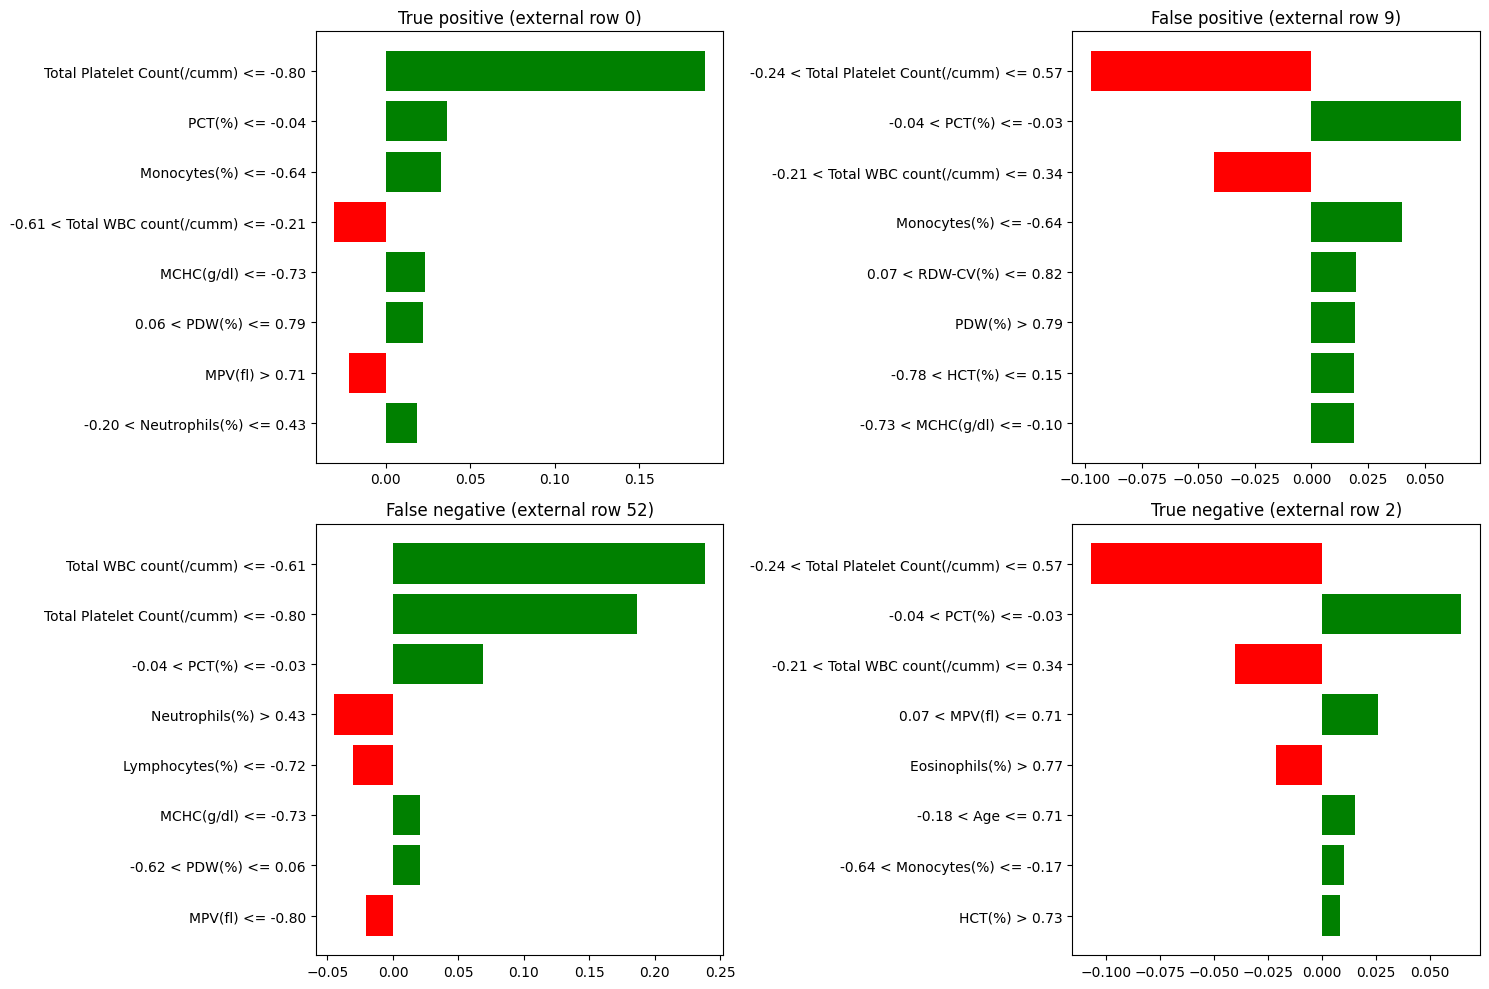

In [ ]:
# [Review: LIME beyond one record] one example each of TP, FP, FN, TN (external cohort)
pred = best_pipeline.predict(X_test); y = y_test.values
cases = {"True positive": (y == 1) & (pred == 1), "False positive": (y == 0) & (pred == 1),
         "False negative": (y == 1) & (pred == 0), "True negative": (y == 0) & (pred == 0)}
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (name, m) in zip(axes.ravel(), cases.items()):
    i = int(np.where(m)[0][0])
    exp = explainer_lime.explain_instance(X_test_transformed[i], final_model.predict_proba, num_features=8)
    items = exp.as_list()[::-1]
    ax.barh([a for a, _ in items], [b for _, b in items], color=["green" if b > 0 else "red" for _, b in items])
    ax.set_title(f"{name} (external row {i})")
plt.tight_layout(); plt.savefig("xai_lime_cases.png", dpi=300); plt.show()

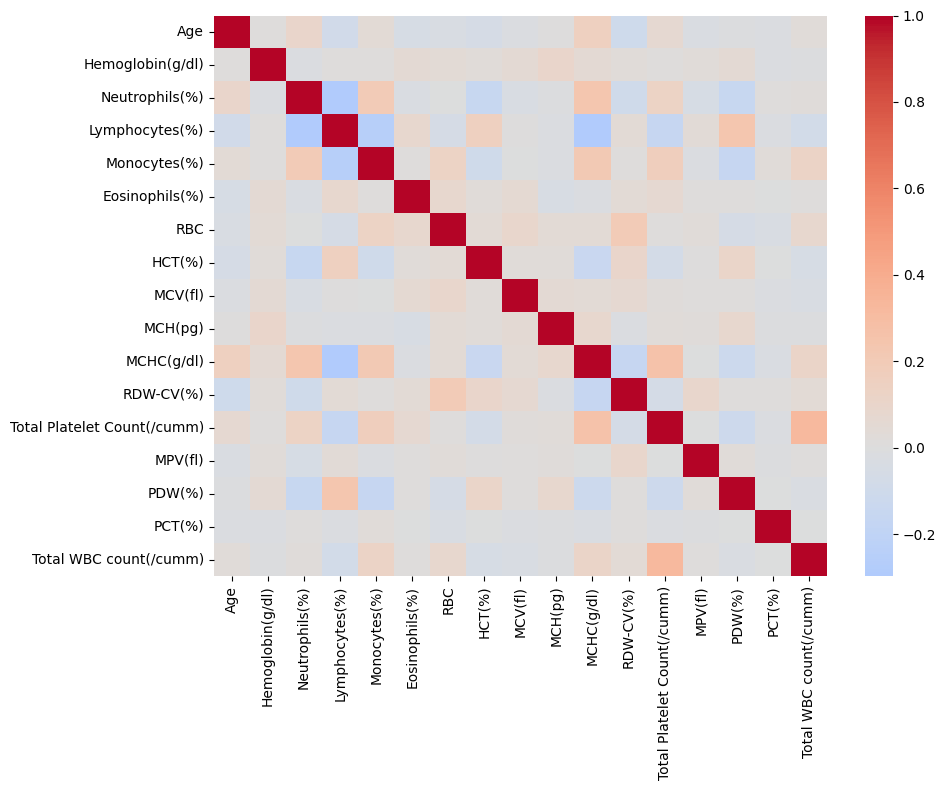

PCT(%)    -0.018
MPV(fl)   -0.004
PDW(%)    -0.111
Name: Total Platelet Count(/cumm), dtype: float64


In [ ]:
# [Review: feature correlation] correlation among the numeric features (development set)
corr = X_train[NUMERIC_COLS].corr()
plt.figure(figsize=(10, 8)); sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.tight_layout(); plt.savefig("feature_correlation.png", dpi=300); plt.show()
pl = "Total Platelet Count(/cumm)"
print(corr[pl][["PCT(%)", "MPV(fl)", "PDW(%)"]].round(3))

In [ ]:
# [Review: XAI on development data] permutation importance on a held-out part of the DEVELOPMENT set
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
Xtr, Xva, ytr, yva = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEED)
p = clone(best_pipeline); p.fit(Xtr, ytr)
Xva_t = p.named_steps["scaler"].transform(p.named_steps["outlier_handler"].transform(Xva))
pi = permutation_importance(p.named_steps["model"], Xva_t, yva, scoring="accuracy", n_repeats=10, random_state=SEED)
print(pd.Series(pi.importances_mean, index=FEATURE_COLS).sort_values(ascending=False).round(4).to_string())

Total WBC count(/cumm)         0.1274
Total Platelet Count(/cumm)    0.1224
PCT(%)                         0.0665
Monocytes(%)                   0.0395
Neutrophils(%)                 0.0222
Eosinophils(%)                 0.0151
RBC                            0.0142
PDW(%)                         0.0140
Lymphocytes(%)                 0.0107
MPV(fl)                        0.0057
RDW-CV(%)                      0.0034
Age                            0.0017
MCV(fl)                       -0.0013
Gender                        -0.0019
HCT(%)                        -0.0019
MCHC(g/dl)                    -0.0027
MCH(pg)                       -0.0036
Hemoglobin(g/dl)              -0.0046


In [ ]:
# [Review: model selection inside the development set only] NESTED cross-validation.
# Outer 5-fold estimates performance; inside each outer-training part the balancing strategy of the
# DengueStackX-19 stack is chosen by an inner 3-fold CV. The external cohort is NOT touched here.
from sklearn.model_selection import StratifiedKFold, cross_val_score
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
samplers = make_samplers(SEED)
outer_acc, chosen = [], []
for k, (tr, te) in enumerate(outer.split(X_train, y_train)):
    Xa, ya = X_train.iloc[tr], y_train.iloc[tr]
    Xb, yb = X_train.iloc[te], y_train.iloc[te]
    inner_scores = {}
    for name, smp in samplers.items():
        pipe = build_pipeline(make_stack(SEED), smp)
        inner_scores[name] = cross_val_score(pipe, Xa, ya, cv=inner, scoring="accuracy", n_jobs=-1).mean()
    best = max(inner_scores, key=inner_scores.get)
    pipe = build_pipeline(make_stack(SEED), samplers[best]).fit(Xa, ya)
    acc = (pipe.predict(Xb) == yb.values).mean() * 100
    outer_acc.append(acc); chosen.append(best)
    print(f"outer fold {k+1}: chosen balancer = {best:18s} outer acc = {acc:.2f}")
print("Nested-CV accuracy: %.2f +/- %.2f" % (np.mean(outer_acc), np.std(outer_acc)))
print("Balancer chosen per fold:", chosen)


outer fold 1: chosen balancer = Tomek links        outer acc = 85.13
outer fold 2: chosen balancer = SMOTETomek         outer acc = 85.61
outer fold 3: chosen balancer = Tomek links        outer acc = 85.61
outer fold 4: chosen balancer = Tomek links        outer acc = 85.85
outer fold 5: chosen balancer = Tomek links        outer acc = 89.21
Nested-CV accuracy: 86.28 +/- 1.48
Balancer chosen per fold: ['Tomek links', 'SMOTETomek', 'Tomek links', 'Tomek links', 'Tomek links']


In [ ]:
# [Review: development-only final protocol] Pre-specified rule: the configuration with the best 10-fold CV
# accuracy on the DEVELOPMENT set is evaluated ONCE on the external cohort (no external ranking involved).
# Uses the table built in the first cell (all_combinations_rows). Check the column names it printed if this fails.
cv_df = pd.DataFrame(all_combinations_rows)
print(cv_df.columns.tolist())
cv_col = [c for c in cv_df.columns if "CV" in c][0]
top = cv_df.sort_values(cv_col, ascending=False).head(5)
print(top.to_string(index=False))


['Model', 'Balancing', '10-Fold CV Acc (%) [Dataset 2]', 'Holdout Test Acc (%) [Dataset 1]', 'Holdout Precision (%)', 'Holdout Recall (%)', 'Holdout Specificity (%)', 'Holdout F1-score (%)']
             Model         Balancing  10-Fold CV Acc (%) [Dataset 2]  Holdout Test Acc (%) [Dataset 1]  Holdout Precision (%)  Holdout Recall (%)  Holdout Specificity (%)  Holdout F1-score (%)
Random Forest (RF) Without balancing                       86.765734                         92.580433              90.997352           98.944338                78.794179             94.804598
Random Forest (RF)            ADASYN                       86.765274                         92.711753              91.013216           99.136276                78.794179             94.901240
Random Forest (RF)       Tomek links                       86.525810                         87.524622              85.090610           99.136276                62.370062             91.578014
Random Forest (RF)        SMOTETomek 

In [ ]:
# [Review: error analysis] What do the false positives / false negatives of the best pipeline look like?
pred = best_pipeline.predict(X_test); y = y_test.values
grp = np.select([(y==1)&(pred==1), (y==0)&(pred==1), (y==1)&(pred==0), (y==0)&(pred==0)], ["TP","FP","FN","TN"], default="NA")
tab = X_test[NUMERIC_COLS].groupby(grp).median().T[["TP","FP","FN","TN"]]
print(tab.round(2).to_string())
print(pd.Series(grp).value_counts().to_string())


                                    TP         FP         FN         TN
Age                              40.00      44.50      38.00      34.00
Hemoglobin(g/dl)                 14.52      14.75      14.20      14.74
Neutrophils(%)                   45.00      44.00      44.50      44.00
Lymphocytes(%)                   44.00      44.00      46.00      46.00
Monocytes(%)                      3.00       3.00       3.00       4.00
Eosinophils(%)                    3.00       3.00       3.00       3.00
RBC                               5.00       4.00       5.00       5.00
HCT(%)                           45.18      44.12      47.13      46.28
MCV(fl)                          89.35      90.05      91.05      90.00
MCH(pg)                          29.80      30.05      30.30      30.14
MCHC(g/dl)                       32.10      32.15      32.63      31.70
RDW-CV(%)                        13.50      12.90      13.60      14.53
Total Platelet Count(/cumm)  160187.50  192344.00  184210.50  17

In [ ]:
# ============================================================================
# CROSS-COHORT EVALUATION (new cell: run AFTER cell 0, in the same runtime)
#   Fixes (1) the record overlap and (2) the selection-on-external-set problem, with the existing data only.
#   Direction A: train on DEVELOPMENT (rows that also occur in the external cohort removed) -> test on EXTERNAL
#   Direction B: train on EXTERNAL   (rows that also occur in the development cohort removed) -> test on DEVELOPMENT
#   In BOTH directions the configuration is chosen by 10-fold CV on the TRAINING cohort only (pre-specified rule),
#   and the other cohort is used once for testing. No test cohort record (or identical pattern) is ever trained on.
# ============================================================================
from math import sqrt
from sklearn.metrics import roc_auc_score, confusion_matrix
from scipy.stats import spearmanr

QUICK = False   # True: only RF, LGBM and the stack (18 configurations) -> about 2-3x faster

def wilson(k, n, z=1.959964):
    p = k / n; d = 1 + z*z/n; c = (p + z*z/(2*n)) / d
    h = z * sqrt(p*(1-p)/n + z*z/(4*n*n)) / d
    return 100*(c-h), 100*(c+h)

def _keys(X):
    return [tuple(r) for r in X.round(6).values]

dev_keys, ext_keys = _keys(X_train), _keys(X_test)
dev_set, ext_set = set(dev_keys), set(ext_keys)
dev_keep = np.array([k not in ext_set for k in dev_keys])    # development rows NOT present in external
ext_keep = np.array([k not in dev_set for k in ext_keys])    # external rows NOT present in development
print(f"Development: {len(X_train)} rows -> {dev_keep.sum()} after removing patterns that occur in the external cohort")
print(f"External   : {len(X_test)} rows -> {ext_keep.sum()} after removing patterns that occur in the development cohort")

def run_direction(Xtr, ytr, tests, label):
    """tests = {name: (X, y)}; returns one row per model x balancing, with CV accuracy and metrics on every test set"""
    rows = []
    samplers = make_samplers(SEED)
    models = make_models(SEED)
    if QUICK:
        models = {k: v for k, v in models.items() if k.startswith(("Random Forest", "Light", "Proposed"))}
    for mname, model in models.items():
        for bname, sampler in samplers.items():
            pipe = build_pipeline(model, sampler)
            cv_acc = cross_validate(pipe, Xtr, ytr, cv=CV, scoring={"a": "accuracy"}, n_jobs=-1)["test_a"].mean() * 100
            pipe.fit(Xtr, ytr)
            row = {"Model": mname, "Balancing": bname, "CV acc (train cohort)": cv_acc}
            for tname, (Xt, yt) in tests.items():
                pred = pipe.predict(Xt)
                tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
                try: auc = roc_auc_score(yt, pipe.predict_proba(Xt)[:, 1])
                except Exception: auc = np.nan
                row.update({f"{tname} acc": 100*(tn+tp)/len(yt), f"{tname} rec": 100*tp/(tp+fn),
                            f"{tname} spec": 100*tn/(tn+fp), f"{tname} AUC": auc,
                            f"{tname} correct": int(tn+tp), f"{tname} n": len(yt)})
            rows.append(row)
        print(f"  [{label}] {mname} done")
    return pd.DataFrame(rows)

def summarize(df, tname, label):
    col = f"{tname} acc"
    d = df.sort_values("CV acc (train cohort)", ascending=False).reset_index(drop=True)
    sel = d.iloc[0]
    print("\n" + "=" * 90)
    print(f"{label} | test set: {tname} (n={int(sel[f'{tname} n'])})")
    print("=" * 90)
    cols = ["Model", "Balancing", "CV acc (train cohort)", f"{tname} acc", f"{tname} rec", f"{tname} spec", f"{tname} AUC"]
    print("Top 8 by CV accuracy on the TRAINING cohort (pre-specified selection rule):")
    print(d[cols].head(8).round(2).to_string(index=False))
    lo, hi = wilson(sel[f"{tname} correct"], sel[f"{tname} n"])
    print(f"\n>> CV-selected configuration: {sel['Model']} | {sel['Balancing']}  ->  test acc {sel[col]:.2f}% (95% Wilson CI {lo:.2f}-{hi:.2f}), "
          f"rec {sel[f'{tname} rec']:.2f}, spec {sel[f'{tname} spec']:.2f}, AUC {sel[f'{tname} AUC']:.4f}")
    st = d[(d["Model"] == "Proposed DengueStackX-19")]
    if len(st):
        b = st.iloc[0]   # best stack option by CV
        lo, hi = wilson(b[f"{tname} correct"], b[f"{tname} n"])
        print(f">> Stack, best balancer by CV ({b['Balancing']}): test acc {b[col]:.2f}% ({lo:.2f}-{hi:.2f}), rec {b[f'{tname} rec']:.2f}, spec {b[f'{tname} spec']:.2f}, AUC {b[f'{tname} AUC']:.4f}")
        a = st[st["Balancing"] == "ADASYN"]
        if len(a):
            a = a.iloc[0]; lo, hi = wilson(a[f"{tname} correct"], a[f"{tname} n"])
            print(f">> Stack + ADASYN (named pipeline): test acc {a[col]:.2f}% ({lo:.2f}-{hi:.2f}), rec {a[f'{tname} rec']:.2f}, spec {a[f'{tname} spec']:.2f}, AUC {a[f'{tname} AUC']:.4f}")
    rho = spearmanr(d["CV acc (train cohort)"], d[col]).correlation
    best = d.sort_values(col, ascending=False).iloc[0]
    print(f">> Spearman rho between CV rank and test rank over all configurations: {rho:.3f}")
    print(f">> (exploratory only) best configuration on the test set: {best['Model']} | {best['Balancing']} = {best[col]:.2f}%")
    return d

# ---------------- Direction A: development (de-duplicated) -> external ----------------
XA, yA = X_train[dev_keep], y_train[dev_keep]
resA = run_direction(XA, yA, {"external-all": (X_test, y_test),
                              "external-nonoverlap": (X_test[ext_keep], y_test[ext_keep])}, "A dev->ext")
resA.to_csv("cross_cohort_A_dev_to_external.csv", index=False)
dA1 = summarize(resA, "external-all", "DIRECTION A: train = development (de-duplicated), 10-fold CV selection")
dA2 = summarize(resA, "external-nonoverlap", "DIRECTION A")

# ---------------- Direction B: external (de-duplicated) -> development ----------------
XB, yB = X_test[ext_keep], y_test[ext_keep]
resB = run_direction(XB, yB, {"development-all": (X_train, y_train),
                              "development-nonoverlap": (X_train[dev_keep], y_train[dev_keep])}, "B ext->dev")
resB.to_csv("cross_cohort_B_external_to_dev.csv", index=False)
dB1 = summarize(resB, "development-all", "DIRECTION B: train = external (de-duplicated), 10-fold CV selection")
dB2 = summarize(resB, "development-nonoverlap", "DIRECTION B")

print("\nBaselines for reference: all-positive classifier = 68.4% accuracy on the external cohort and "
      f"{100*(y_train==1).mean():.1f}% on the development cohort; all-negative = {100*(y_train==0).mean():.1f}% on development.")
print("Class balance of the training cohorts: A (dev, dedup) positives = %.1f%%, B (ext, dedup) positives = %.1f%%"
      % (100*yA.mean(), 100*yB.mean()))


Development: 2085 rows -> 1868 after removing patterns that occur in the external cohort
External   : 1523 rows -> 1299 after removing patterns that occur in the development cohort
  [A dev->ext] Logistic Regression (LR) done
  [A dev->ext] Decision Tree (DT) done
  [A dev->ext] Random Forest (RF) done
  [A dev->ext] Support Vector Machine (SVM) done
  [A dev->ext] K-Nearest Neighbors (KNN) done
  [A dev->ext] Proposed DengueStackX-19 done
  [A dev->ext] Light Gradient Boosting Machine (LGBM) done

DIRECTION A: train = development (de-duplicated), 10-fold CV selection | test set: external-all (n=1523)
Top 8 by CV accuracy on the TRAINING cohort (pre-specified selection rule):
                                 Model         Balancing  CV acc (train cohort)  external-all acc  external-all rec  external-all spec  external-all AUC
                    Random Forest (RF)       Tomek links                  88.71             85.10             96.45              60.50              0.87
         


############################################################################################
# S1 data audit (PCT consistency, per-cohort correlations, units, shift)
############################################################################################
[development] PCT vs platelet*MPV/10^7: Pearson r = -0.018; median PCT/expected = 1.020; share within +-20% of expected = 23.9%; corr(PCT, platelet) = -0.018, corr(PCT, MPV) = -0.009, corr(platelet, MPV) = -0.004
[external] PCT vs platelet*MPV/10^7: Pearson r = -0.036; median PCT/expected = 0.837; share within +-20% of expected = 30.1%; corr(PCT, platelet) = -0.036, corr(PCT, MPV) = -0.014, corr(platelet, MPV) = 0.001

Units / range check (median [p1, p99]) and distribution shift (standardized mean difference, KS statistic):
                    feature                   development                     external   SMD    KS
                        Age                 40 [2.84, 98]                  39 [14, 69] -0.20 0.140
           

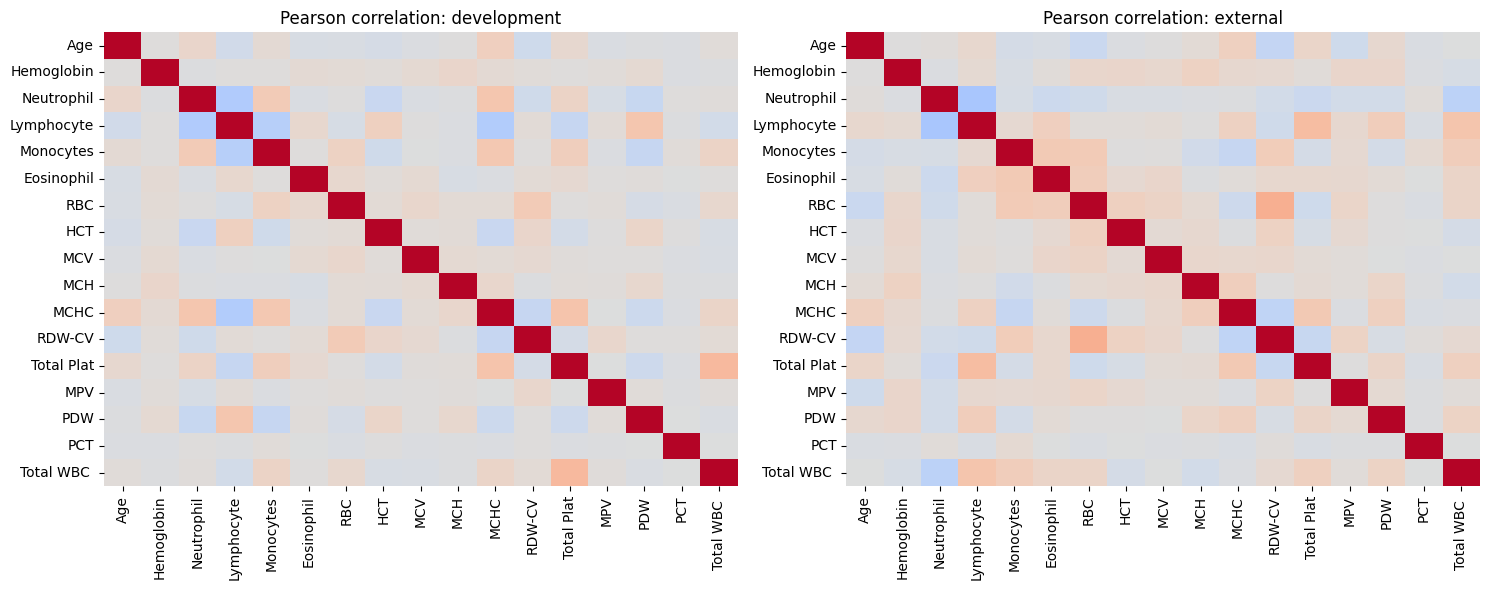

Positive-class prevalence: development 43.8%, external 68.4%

############################################################################################
# S2 simple baselines and why full LR is weak
############################################################################################

--- A dev->ext: train n=1868 (42.3% pos), test n=1523 (68.4% pos) ---
Majority class (train):   acc 31.58 (CI 29.30-33.96) rec 0.00 spec 100.00
All-positive:             acc 68.42 (CI 66.04-70.70) rec 100.00 spec 0.00
Platelet <= 153,537 rule:    acc 54.10 (CI 51.59-56.59) rec 48.37 spec 66.53 AUC 0.5317
LR on platelet + WBC      acc 52.46 (CI 49.95-54.96) rec 53.74 spec 49.69 AUC 0.5549
LR on platelet only       acc 52.66 (CI 50.15-55.16) rec 51.25 spec 55.72 AUC 0.5317
Full LR (as in grid):     acc 64.74 (CI 62.31-67.10) rec 77.35 spec 37.42 AUC 0.6082 | predicted-positive rate 72.7% vs true 68.4%
   largest LR coefficients (standardized): Total WBC count=-1.79, Total Platelet Count=-1.06, Mono

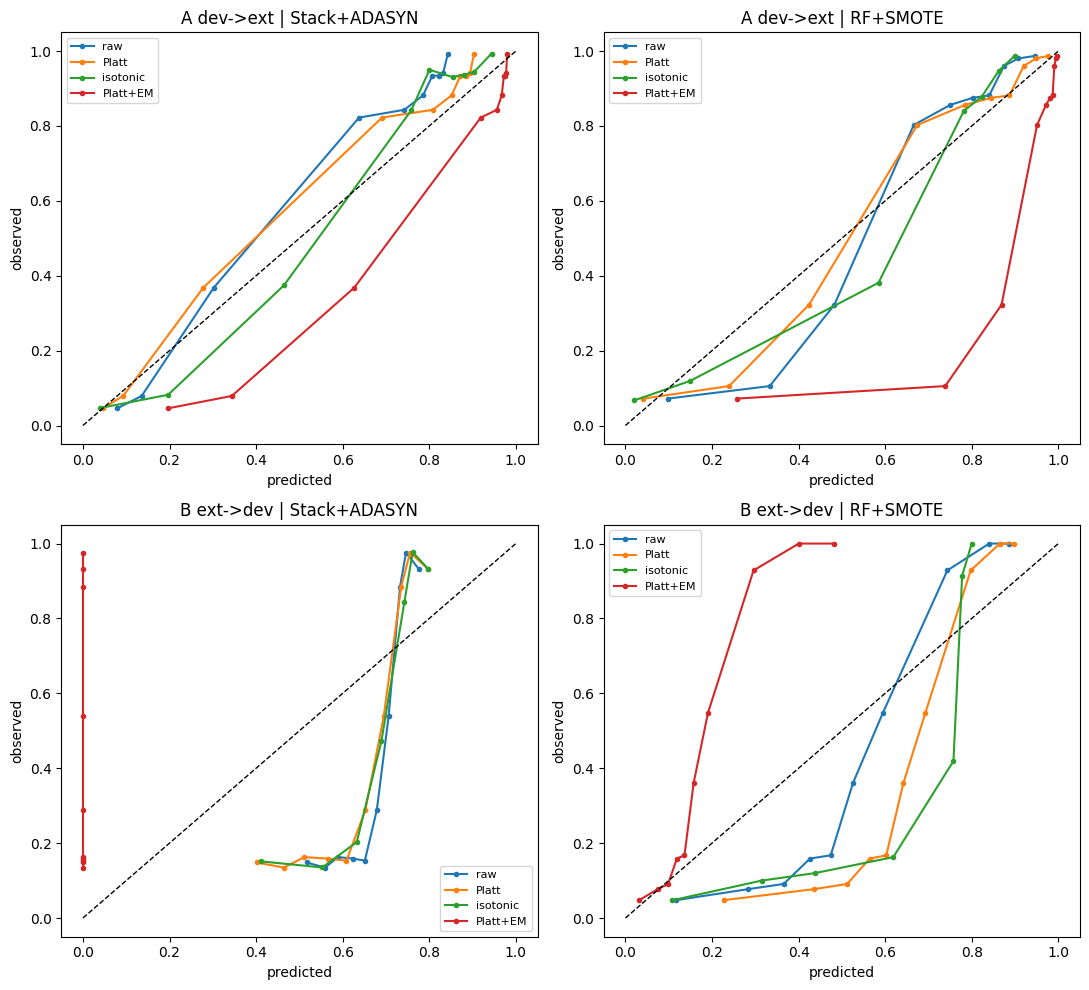


############################################################################################
# S4 paired predictions, exact McNemar, bootstrap CI, TOST, DeLong
############################################################################################
Saved paired_predictions_external.csv

Stack+ADASYN vs RF+SMOTE:
  discordant: stack right/other wrong = 20, stack wrong/other right = 28; exact McNemar p = 0.3123
  accuracy difference (stack - other) = -0.53 pp, paired-bootstrap 95% CI [-1.44, +0.39]
  TOST equivalence (margin +-1.0 pp): 90% CI [-1.31, +0.20] -> equivalence NOT shown
  AUC: stack 0.9490 vs 0.9457; difference +0.0033 (DeLong 95% CI [-0.0026, +0.0092], p = 0.2717)

Stack+ADASYN vs LGBM (no balancing):
  discordant: stack right/other wrong = 15, stack wrong/other right = 23; exact McNemar p = 0.2559
  accuracy difference (stack - other) = -0.53 pp, paired-bootstrap 95% CI [-1.31, +0.26]
  TOST equivalence (margin +-1.0 pp): 90% CI [-1.18, +0.13] -> equivalence NOT shown


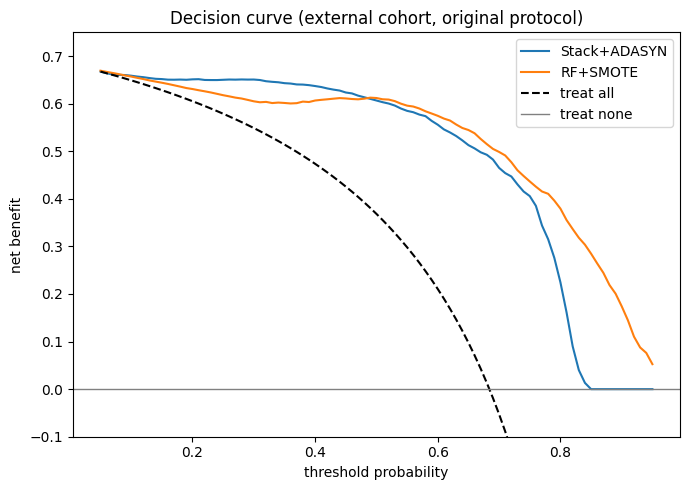

  threshold 0.1: net benefit stack 0.659, RF 0.657, treat-all 0.649
  threshold 0.3: net benefit stack 0.651, RF 0.605, treat-all 0.549
  threshold 0.5: net benefit stack 0.607, RF 0.612, treat-all 0.368
  threshold 0.7: net benefit stack 0.465, RF 0.499, treat-all -0.053

############################################################################################
# S7 age-stratified performance
############################################################################################

children (<18 y): n=39, positive share 30.8%
  Proposed DengueStackX-19 | ADASYN    acc 100.00 (CI 91.03-100.00) rec 100.00 spec 100.00 AUC 1.0000
  Random Forest (RF) | SMOTE           acc 97.44 (CI 86.82-99.55) rec 100.00 spec 96.30 AUC 1.0000

adults (>=18 y): n=1484, positive share 69.4%
  Proposed DengueStackX-19 | ADASYN    acc 92.05 (CI 90.56-93.32) rec 96.50 spec 81.94 AUC 0.9461
  Random Forest (RF) | SMOTE           acc 92.65 (CI 91.21-93.87) rec 99.13 spec 77.97 AUC 0.9427

Development cohor

In [ ]:
# ============================================================================
# REVISION EXPERIMENTS (one new cell; run AFTER cell 0, in the same runtime)
# Covers the open TODOs of the response letter:
#   S1  data audit: PCT ~ platelet x MPV / 10,000, per-cohort correlations, units / distribution shift
#   S2  simple baselines (majority, platelet threshold, LR on platelet+WBC, full LR diagnostics), both directions
#   S3  recalibration (Platt, isotonic, EM prior-shift, Youden threshold) fitted on the TRAINING cohort only,
#       Brier score, ECE, calibration curves, both directions
#   S4  paired predictions export, exact McNemar, paired-bootstrap difference CIs, TOST, DeLong AUC tests
#       (stack vs RF+SMOTE, stack vs wide MLP+SMOTE)
#   S5  repeated CV with several seeds (mean +/- SD)
#   S6  decision-curve analysis
#   S7  age-stratified results (children < 18 y vs adults)
#   S8  within-cohort duplicate removal sensitivity
# Every section is wrapped in try/except, so one failure does not stop the others.
# Set QUICK = True for a faster run (fewer bootstrap / CV repeats).
# ============================================================================
import traceback
from math import sqrt
from scipy import stats
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.model_selection import cross_val_predict, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.metrics import roc_auc_score, brier_score_loss, confusion_matrix, roc_curve

QUICK = False
N_BOOT = 500 if QUICK else 2000
N_REPEATS = 2 if QUICK else 3
TOST_DELTA = 1.0          # equivalence margin in accuracy percentage points (state and justify it in the paper)
PLT, WBC, MPVc, PCTc = "Total Platelet Count(/cumm)", "Total WBC count(/cumm)", "MPV(fl)", "PCT(%)"

def safe(name, fn):
    print("\n" + "#" * 92 + f"\n# {name}\n" + "#" * 92)
    try: fn()
    except Exception as e:
        print(f"!! {name} failed: {type(e).__name__}: {e}"); traceback.print_exc()

def wilson(k, n, z=1.959964):
    p = k / n; d = 1 + z*z/n; c = (p + z*z/(2*n)) / d
    h = z * sqrt(p*(1-p)/n + z*z/(4*n*n)) / d
    return 100*(c-h), 100*(c+h)

def metrics(y, pred, prob=None):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    out = dict(n=len(y), acc=100*(tn+tp)/len(y), rec=100*tp/max(tp+fn, 1), spec=100*tn/max(tn+fp, 1),
               ppv=100*tp/max(tp+fp, 1), tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn))
    if prob is not None and len(set(y)) == 2: out["auc"] = roc_auc_score(y, prob)
    return out

def fmt(m):
    s = f"acc {m['acc']:.2f} (CI {wilson(m['tp']+m['tn'], m['n'])[0]:.2f}-{wilson(m['tp']+m['tn'], m['n'])[1]:.2f}) rec {m['rec']:.2f} spec {m['spec']:.2f}"
    return s + (f" AUC {m['auc']:.4f}" if "auc" in m else "")

# ---- cohorts (recomputed here so the cell is self-contained) ----
_keys = lambda X: [tuple(r) for r in X.round(6).values]
_dk, _ek = _keys(X_train), _keys(X_test)
_dev_keep = np.array([k not in set(_ek) for k in _dk]); _ext_keep = np.array([k not in set(_dk) for k in _ek])
XA, yA = X_train[_dev_keep], y_train[_dev_keep]          # direction A training (dev without external patterns)
XB, yB = X_test[_ext_keep], y_test[_ext_keep]            # direction B training (ext without development patterns)
DIRS = {"A dev->ext": (XA, yA, X_test, y_test), "B ext->dev": (XB, yB, X_train, y_train)}

# ============================ S1 data audit ==================================
def s1():
    for name, X in [("development", X_train), ("external", X_test)]:
        expected = X[PLT] / 1000.0 * X[MPVc] / 10000.0          # PCT(%) = platelets(x10^3/uL) x MPV(fL) / 10,000
        ratio = X[PCTc] / expected.replace(0, np.nan)
        r = np.corrcoef(X[PCTc], expected)[0, 1]
        print(f"[{name}] PCT vs platelet*MPV/10^7: Pearson r = {r:.3f}; median PCT/expected = {ratio.median():.3f}; "
              f"share within +-20% of expected = {100*((ratio-1).abs() <= 0.2).mean():.1f}%; "
              f"corr(PCT, platelet) = {X[PCTc].corr(X[PLT]):.3f}, corr(PCT, MPV) = {X[PCTc].corr(X[MPVc]):.3f}, corr(platelet, MPV) = {X[PLT].corr(X[MPVc]):.3f}")
    print("\nUnits / range check (median [p1, p99]) and distribution shift (standardized mean difference, KS statistic):")
    rows = []
    for c in NUMERIC_COLS:
        a, b = X_train[c], X_test[c]
        smd = (b.mean() - a.mean()) / sqrt((a.var() + b.var()) / 2)
        rows.append([c, f"{a.median():.3g} [{a.quantile(.01):.3g}, {a.quantile(.99):.3g}]",
                     f"{b.median():.3g} [{b.quantile(.01):.3g}, {b.quantile(.99):.3g}]", round(smd, 2), round(stats.ks_2samp(a, b).statistic, 3)])
    print(pd.DataFrame(rows, columns=["feature", "development", "external", "SMD", "KS"]).to_string(index=False))
    fig, ax = plt.subplots(1, 2, figsize=(15, 6))
    for a_, (name, X) in zip(ax, [("development", X_train), ("external", X_test)]):
        sns.heatmap(X[NUMERIC_COLS].corr(), cmap="coolwarm", vmin=-1, vmax=1, ax=a_, cbar=False,
                    xticklabels=[c.split("(")[0][:10] for c in NUMERIC_COLS], yticklabels=[c.split("(")[0][:10] for c in NUMERIC_COLS])
        a_.set_title(f"Pearson correlation: {name}")
    plt.tight_layout(); plt.savefig("corr_per_cohort.png", dpi=300); plt.show()
    print("Positive-class prevalence: development %.1f%%, external %.1f%%" % (100*y_train.mean(), 100*y_test.mean()))
safe("S1 data audit (PCT consistency, per-cohort correlations, units, shift)", s1)

# ============================ S2 simple baselines ============================
def s2():
    for dname, (Xtr, ytr, Xte, yte) in DIRS.items():
        print(f"\n--- {dname}: train n={len(Xtr)} ({100*ytr.mean():.1f}% pos), test n={len(Xte)} ({100*yte.mean():.1f}% pos) ---")
        maj = int(ytr.mean() >= 0.5); print("Majority class (train):  ", fmt(metrics(yte, np.full(len(yte), maj))))
        print("All-positive:            ", fmt(metrics(yte, np.ones(len(yte), int))))
        # platelet-threshold rule: positive if platelets <= t; t maximizes Youden J on the training cohort
        fpr, tpr, thr = roc_curve(ytr, -Xtr[PLT]); t = -thr[np.argmax(tpr - fpr)]
        pr = (-Xte[PLT]).values; m = metrics(yte, (Xte[PLT] <= t).astype(int), pr)
        print(f"Platelet <= {t:,.0f} rule:   ", fmt(m))
        for label, cols in [("LR on platelet + WBC", [PLT, WBC]), ("LR on platelet only", [PLT])]:
            p = SkPipeline([("sc", StandardScaler()), ("lr", LogisticRegression(max_iter=1000))]).fit(Xtr[cols], ytr)
            print(f"{label:25s}", fmt(metrics(yte, p.predict(Xte[cols]), p.predict_proba(Xte[cols])[:, 1])))
        p = build_pipeline(LogisticRegression(max_iter=1000, random_state=SEED), None).fit(Xtr, ytr)
        prob = p.predict_proba(Xte)[:, 1]; m = metrics(yte, p.predict(Xte), prob)
        print("Full LR (as in grid):    ", fmt(m), f"| predicted-positive rate {100*(prob >= 0.5).mean():.1f}% vs true {100*yte.mean():.1f}%")
        coef = pd.Series(p.named_steps["model"].coef_[0], index=FEATURE_COLS).sort_values(key=abs, ascending=False)
        print("   largest LR coefficients (standardized):", ", ".join(f"{k.split('(')[0]}={v:+.2f}" for k, v in coef.head(5).items()))
        oof = cross_val_predict(clone(p), Xtr, ytr, cv=5, method="predict_proba")[:, 1]
        f2, t2, th2 = roc_curve(ytr, oof); thr_y = th2[np.argmax(t2 - f2)]
        print(f"   full LR with a training-cohort Youden threshold ({thr_y:.2f}):", fmt(metrics(yte, (prob >= thr_y).astype(int), prob)))
safe("S2 simple baselines and why full LR is weak", s2)

# ============================ S3 recalibration ===============================
def ece_score(y, p, bins=10):
    idx = np.minimum((p * bins).astype(int), bins - 1); e = 0.0
    for b in range(bins):
        m = idx == b
        if m.any(): e += m.mean() * abs(y[m].mean() - p[m].mean())
    return e

def em_prior_shift(q, prior_tr, iters=100):
    """Saerens et al. 2002: re-estimate the test prevalence without labels and rescale the posteriors."""
    pi = prior_tr
    for _ in range(iters):
        a = q * pi / prior_tr; b = (1 - q) * (1 - pi) / (1 - prior_tr)
        post = a / (a + b); pi_new = post.mean()
        if abs(pi_new - pi) < 1e-7: break
        pi = pi_new
    return post, pi

CAL_MODELS = {"Stack+ADASYN": ("Proposed DengueStackX-19", "ADASYN"), "RF+SMOTE": ("Random Forest (RF)", "SMOTE")}
_cal_store = {}
def s3():
    samplers, models = make_samplers(SEED), make_models(SEED)
    rows = []
    for dname, (Xtr, ytr, Xte, yte) in DIRS.items():
        for mname, (m_, b_) in CAL_MODELS.items():
            pipe = build_pipeline(models[m_], samplers[b_])
            oof = cross_val_predict(clone(pipe), Xtr, ytr, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba", n_jobs=-1)[:, 1]
            pipe.fit(Xtr, ytr); raw = pipe.predict_proba(Xte)[:, 1]; yt = yte.values
            lg = lambda p: np.log(np.clip(p, 1e-6, 1-1e-6) / (1 - np.clip(p, 1e-6, 1-1e-6))).reshape(-1, 1)
            platt = LogisticRegression(C=1e6, max_iter=1000).fit(lg(oof), ytr); p_platt = platt.predict_proba(lg(raw))[:, 1]
            iso = IsotonicRegression(out_of_bounds="clip").fit(oof, ytr); p_iso = iso.predict(raw)
            p_em, pi_hat = em_prior_shift(p_platt, ytr.mean())
            f_, t_, th_ = roc_curve(ytr, oof); thr_y = th_[np.argmax(t_ - f_)]
            variants = {"raw (0.5)": (raw, 0.5), "raw + Youden thr": (raw, thr_y), "Platt": (p_platt, 0.5),
                        "Isotonic": (p_iso, 0.5), "Platt + EM prior shift": (p_em, 0.5)}
            for vname, (p, th) in variants.items():
                m = metrics(yt, (p >= th).astype(int), p)
                rows.append([dname, mname, vname, round(m["acc"], 2), round(m["rec"], 2), round(m["spec"], 2), round(m["auc"], 4),
                             round(brier_score_loss(yt, np.clip(p, 0, 1)), 4), round(ece_score(yt, np.clip(p, 0, 1)), 4)])
            print(f"[{dname} | {mname}] train prevalence {100*ytr.mean():.1f}%, EM-estimated test prevalence {100*pi_hat:.1f}% (true {100*yt.mean():.1f}%)")
            _cal_store[(dname, mname)] = (yt, raw, p_platt, p_iso, p_em)
    df = pd.DataFrame(rows, columns=["direction", "model", "variant", "acc", "rec", "spec", "AUC", "Brier", "ECE"])
    print(df.to_string(index=False)); df.to_csv("recalibration_results.csv", index=False)
    fig, axes = plt.subplots(2, 2, figsize=(11, 10))
    for ax, ((dname, mname), (yt, raw, pp, pi_, pe)) in zip(axes.ravel(), _cal_store.items()):
        for lab, p in [("raw", raw), ("Platt", pp), ("isotonic", pi_), ("Platt+EM", pe)]:
            fo, mp = calibration_curve(yt, np.clip(p, 0, 1), n_bins=10, strategy="quantile"); ax.plot(mp, fo, marker="o", ms=3, label=lab)
        ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_title(f"{dname} | {mname}"); ax.set_xlabel("predicted"); ax.set_ylabel("observed"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig("calibration_curves.png", dpi=300); plt.show()
safe("S3 recalibration and calibration curves (fitted on training cohort only)", s3)

# ============================ S4 paired tests ================================
def delong_paired(y, p1, p2):
    """DeLong test for two correlated ROC AUCs (fast O(n log n) version, Sun & Xu 2014)."""
    y = np.asarray(y); order = np.argsort(-y); m = int(y.sum()); n = len(y) - m
    preds = np.vstack([np.asarray(p1), np.asarray(p2)])[:, order]
    def midrank(x):
        j = np.argsort(x); z = x[j]; N = len(x); t = np.zeros(N); i = 0
        while i < N:
            k = i
            while k < N and z[k] == z[i]: k += 1
            t[i:k] = 0.5 * (i + k - 1) + 1; i = k
        out = np.empty(N); out[j] = t; return out
    tx = np.array([midrank(p[:m]) for p in preds]); ty = np.array([midrank(p[m:]) for p in preds]); tz = np.array([midrank(p) for p in preds])
    aucs = tz[:, :m].sum(axis=1) / m / n - (m + 1.0) / 2.0 / n
    v01 = (tz[:, :m] - tx) / n; v10 = 1.0 - (tz[:, m:] - ty) / m
    cov = np.cov(v01) / m + np.cov(v10) / n
    d = aucs[0] - aucs[1]; var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    z = d / sqrt(var) if var > 0 else 0.0
    return aucs, d, 2 * stats.norm.sf(abs(z)), (d - 1.96*sqrt(max(var, 0)), d + 1.96*sqrt(max(var, 0)))

def s4():
    yt = y_test.values
    pipes = {"Stack+ADASYN": fitted_pipelines["Proposed DengueStackX-19 | ADASYN"],
             "RF+SMOTE": fitted_pipelines["Random Forest (RF) | SMOTE"],
             "LGBM (no balancing)": fitted_pipelines["Light Gradient Boosting Machine (LGBM) | Without balancing"]}
    mlp = build_pipeline(MLPClassifier(hidden_layer_sizes=(256, 128, 64), activation="tanh", max_iter=500, random_state=SEED), SMOTE(random_state=SEED))
    pipes["Wide MLP+SMOTE"] = mlp.fit(X_train, y_train)
    P = {k: v.predict_proba(X_test)[:, 1] for k, v in pipes.items()}; C = {k: (p >= 0.5).astype(int) for k, p in P.items()}
    out = pd.DataFrame({"y_true": yt, **{f"pred_{k}": C[k] for k in C}, **{f"prob_{k}": P[k] for k in P}}); out.to_csv("paired_predictions_external.csv", index=False)
    print("Saved paired_predictions_external.csv")
    rng = np.random.RandomState(SEED); idx = rng.randint(0, len(yt), (N_BOOT, len(yt)))
    for other in ["RF+SMOTE", "LGBM (no balancing)", "Wide MLP+SMOTE"]:
        a, b = C["Stack+ADASYN"], C[other]
        b01 = int(((a == yt) & (b != yt)).sum()); b10 = int(((a != yt) & (b == yt)).sum())
        p_mc = stats.binomtest(b01, b01 + b10, 0.5).pvalue if b01 + b10 else 1.0
        d_acc = 100 * ((a == yt).mean() - (b == yt).mean())
        boot = np.array([100 * (((a[i] == yt[i]).mean()) - ((b[i] == yt[i]).mean())) for i in idx])
        lo, hi = np.percentile(boot, [2.5, 97.5]); lo90, hi90 = np.percentile(boot, [5, 95])
        aucs, d_auc, p_dl, ci_dl = delong_paired(yt, P["Stack+ADASYN"], P[other])
        print(f"\nStack+ADASYN vs {other}:")
        print(f"  discordant: stack right/other wrong = {b01}, stack wrong/other right = {b10}; exact McNemar p = {p_mc:.4f}")
        print(f"  accuracy difference (stack - other) = {d_acc:+.2f} pp, paired-bootstrap 95% CI [{lo:+.2f}, {hi:+.2f}]")
        print(f"  TOST equivalence (margin +-{TOST_DELTA} pp): 90% CI [{lo90:+.2f}, {hi90:+.2f}] -> "
              f"{'EQUIVALENT within margin' if (lo90 > -TOST_DELTA and hi90 < TOST_DELTA) else 'equivalence NOT shown'}")
        print(f"  AUC: stack {aucs[0]:.4f} vs {aucs[1]:.4f}; difference {d_auc:+.4f} (DeLong 95% CI [{ci_dl[0]:+.4f}, {ci_dl[1]:+.4f}], p = {p_dl:.4f})")
safe("S4 paired predictions, exact McNemar, bootstrap CI, TOST, DeLong", s4)

# ============================ S5 multi-seed CV ===============================
def s5():
    cfg = [("Proposed DengueStackX-19", "ADASYN"), ("Proposed DengueStackX-19", "Tomek links"), ("Random Forest (RF)", "SMOTE"),
           ("Random Forest (RF)", "Without balancing"), ("Light Gradient Boosting Machine (LGBM)", "Without balancing")]
    samplers, models = make_samplers(SEED), make_models(SEED); rows = []
    for m_, b_ in cfg:
        pipe = build_pipeline(models[m_], samplers[b_]); accs = []
        for seed in range(N_REPEATS):
            cv = StratifiedKFold(10, shuffle=True, random_state=SEED + seed)
            accs.append(cross_validate(clone(pipe), X_train, y_train, cv=cv, scoring={"a": "accuracy"}, n_jobs=-1)["test_a"].mean() * 100)
        rows.append([m_, b_, np.mean(accs), np.std(accs, ddof=1) if len(accs) > 1 else np.nan, *np.round(accs, 2)])
        print(f"  {m_} | {b_}: mean {np.mean(accs):.2f}, SD across {N_REPEATS} CV seeds {rows[-1][3]:.2f}  {np.round(accs, 2)}")
    pd.DataFrame(rows).to_csv("multiseed_cv.csv", index=False)
safe(f"S5 repeated 10-fold CV with {N_REPEATS} seeds", s5)

# ============================ S6 decision curve ==============================
def s6():
    yt = y_test.values; pts = np.linspace(0.05, 0.95, 91)
    nb = lambda p, t: np.array([((p >= th) & (yt == 1)).sum() / len(yt) - ((p >= th) & (yt == 0)).sum() / len(yt) * th / (1 - th) for th in t])
    stack = fitted_pipelines["Proposed DengueStackX-19 | ADASYN"].predict_proba(X_test)[:, 1]
    rf = fitted_pipelines["Random Forest (RF) | SMOTE"].predict_proba(X_test)[:, 1]
    prev = yt.mean(); treat_all = prev - (1 - prev) * pts / (1 - pts)
    plt.figure(figsize=(7, 5)); plt.plot(pts, nb(stack, pts), label="Stack+ADASYN"); plt.plot(pts, nb(rf, pts), label="RF+SMOTE")
    plt.plot(pts, treat_all, "k--", label="treat all"); plt.axhline(0, color="gray", lw=1, label="treat none")
    plt.ylim(-0.1, 0.75); plt.xlabel("threshold probability"); plt.ylabel("net benefit"); plt.title("Decision curve (external cohort, original protocol)")
    plt.legend(); plt.tight_layout(); plt.savefig("decision_curve.png", dpi=300); plt.show()
    for th in (0.1, 0.3, 0.5, 0.7):
        print(f"  threshold {th}: net benefit stack {nb(stack, [th])[0]:.3f}, RF {nb(rf, [th])[0]:.3f}, treat-all {prev - (1-prev)*th/(1-th):.3f}")
safe("S6 decision-curve analysis", s6)

# ============================ S7 age strata ==================================
def s7():
    yt = y_test.values
    for label, mask in [("children (<18 y)", (X_test["Age"] < 18).values), ("adults (>=18 y)", (X_test["Age"] >= 18).values)]:
        print(f"\n{label}: n={mask.sum()}, positive share {100*yt[mask].mean():.1f}%")
        for k in ["Proposed DengueStackX-19 | ADASYN", "Random Forest (RF) | SMOTE"]:
            pipe = fitted_pipelines[k]; prob = pipe.predict_proba(X_test[mask])[:, 1]
            print(f"  {k:36s}", fmt(metrics(yt[mask], pipe.predict(X_test[mask]), prob)))
    print("\nDevelopment cohort age groups:", (X_train['Age'] < 18).sum(), "children,", (X_train['Age'] >= 18).sum(), "adults")
safe("S7 age-stratified performance", s7)

# ============================ S8 within-cohort duplicates ====================
def s8():
    d_keep = ~pd.Series(_dk).duplicated().values; e_keep = ~pd.Series(_ek).duplicated().values
    Xd, yd, Xe, ye = X_train[d_keep], y_train[d_keep], X_test[e_keep], y_test[e_keep]
    print(f"After removing within-cohort duplicates: development {len(Xd)} (from {len(X_train)}), external {len(Xe)} (from {len(X_test)})")
    samplers, models = make_samplers(SEED), make_models(SEED)
    for m_, b_ in [("Proposed DengueStackX-19", "ADASYN"), ("Random Forest (RF)", "SMOTE")]:
        p = build_pipeline(models[m_], samplers[b_]).fit(Xd, yd)
        print(f"  {m_} | {b_}:", fmt(metrics(ye, p.predict(Xe), p.predict_proba(Xe)[:, 1])))
safe("S8 within-cohort duplicate removal", s8)

print("\nFiles written: corr_per_cohort.png, recalibration_results.csv, calibration_curves.png, paired_predictions_external.csv, "
      "multiseed_cv.csv, decision_curve.png")
